\n======================================================================
CAUSAL SHAP on NPZ Dataset
======================================================================\n
Loading NPZ dataset...
✓ NPZ loaded with keys: ['X_train', 'X_test', 'y_train', 'y_test', 'feature_names']
Shapes: X_train=(800, 4), X_test=(200, 4), y_train=(800,), y_test=(200,)
Features: Nitrogen, Irrigation, Precipitation, Herbicide
Target classes: 3
\n======================================================================
Training Model
Using XGBoost classifier
✓ Model trained
  Test Accuracy: 0.8050
  Test Macro F1: 0.8081
\n======================================================================
Step 1: Causal Discovery (PC Algorithm)
Running PC algorithm on 4 features...
✓ Causal discovery complete
\nDiscovered graph: 4 nodes, 4 edges
✓ Causal graph saved to 'causal_graph_yield.png'
\n======================================================================
Step 2: Computing Causal SHAP
\nLearning causal mechanism

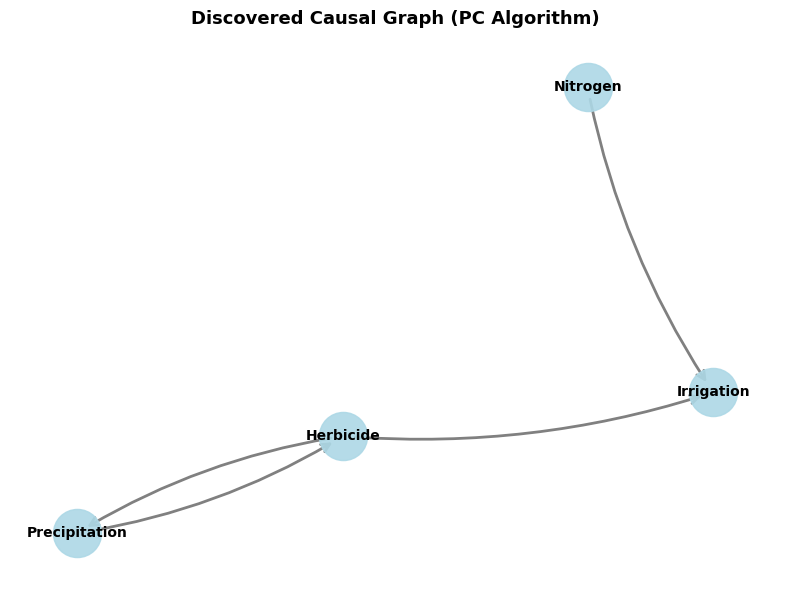

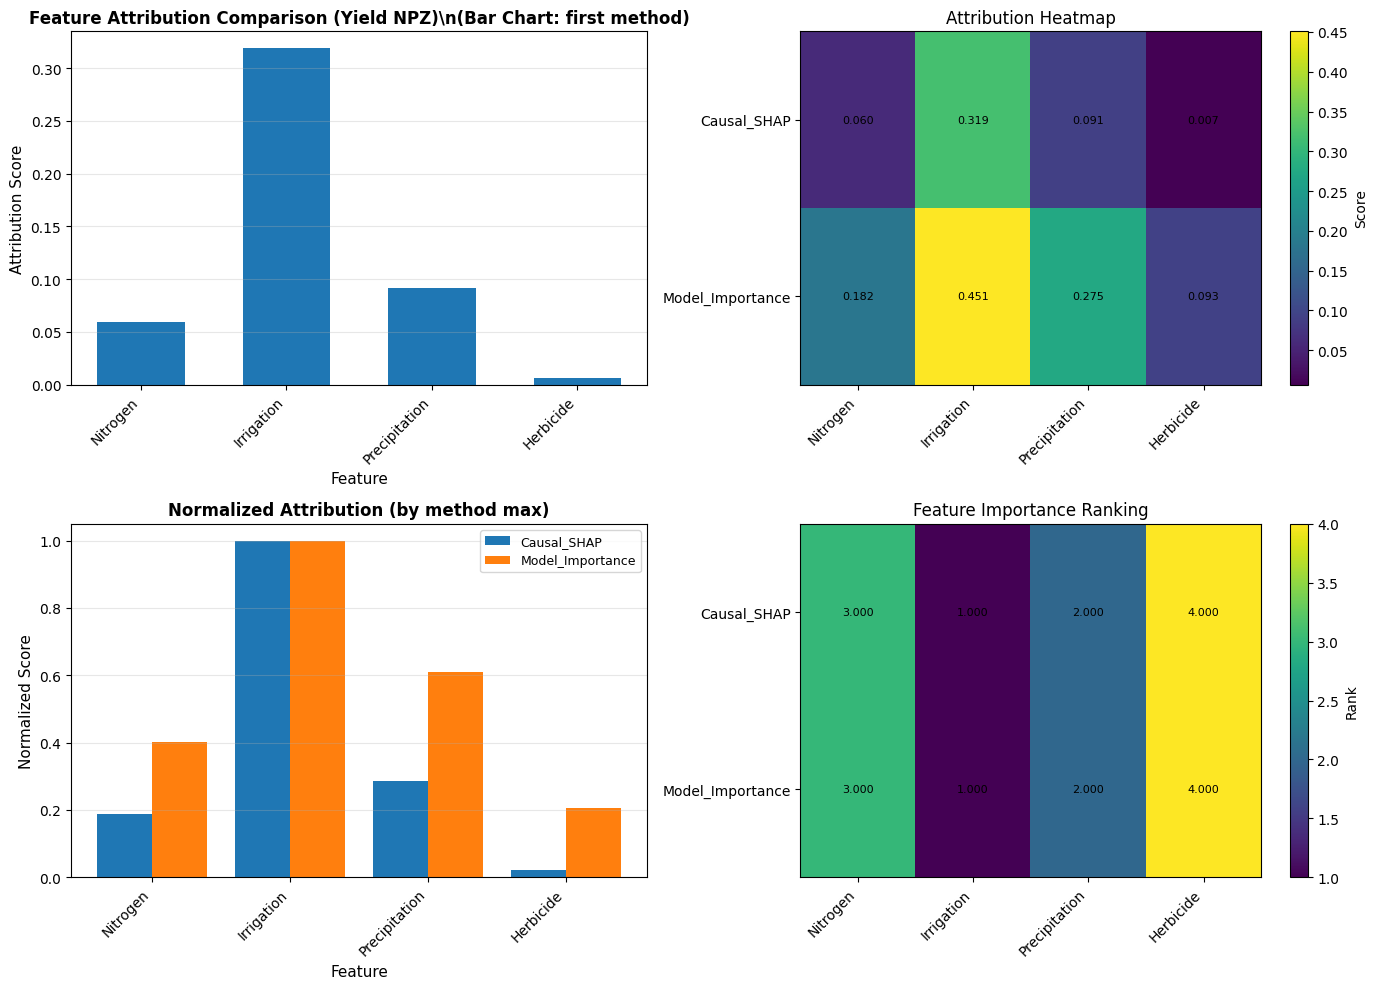

In [1]:
"""
CAUSAL SHAP on yield_preprocessed.npz
- Works with keys: X_train, X_test, y_train, y_test, feature_names
- Implements PC-based causal discovery, IDA-style causal effects, and Causal SHAP
- Saves outputs: causal graph PNG, comparison PNG, and CSV of attributions
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from typing import Dict, List, Tuple, Set
warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, accuracy_score
import networkx as nx

try:
    from xgboost import XGBClassifier
    HAVE_XGB = True
except:
    HAVE_XGB = False

from causallearn.search.ConstraintBased.PC import pc

# Configuration
CONFIG = {
    'DATA_PATH': '../../datasets/yield_preprocessed.npz',
    'ALPHA_PC': 0.1,
    'MAX_PERM': 200,
    'M_RESAMPLES': 64,
    'GLOBAL_K': 30,
    'RANDOM_SEED': 42,
    'N_DAGS': 5  # Sample multiple DAGs from CPDAG
}

np.random.seed(CONFIG['RANDOM_SEED'])
rng = np.random.default_rng(CONFIG['RANDOM_SEED'])


# 1. Causal Discovery & Structure Learning

class CausalStructure:
    """Handles causal discovery and DAG sampling from CPDAG"""

    def __init__(self, alpha=0.05):
        self.alpha = alpha
        self.cpdag = None
        self.feature_names = None
        self.dags = []

    def discover(self, X: pd.DataFrame):
        """Run PC algorithm on features"""
        self.feature_names = list(X.columns)
        print(f"Running PC algorithm on {len(self.feature_names)} features...")

        pc_res = pc(X.values, alpha=self.alpha, show_progress=False)
        self.cpdag = pc_res.G.graph

        print(f"Causal discovery complete")
        return self

    def get_skeleton(self) -> nx.DiGraph:
        """Convert CPDAG to networkx DiGraph"""
        G = nx.DiGraph()
        G.add_nodes_from(self.feature_names)

        n = len(self.feature_names)
        for i in range(n):
            for j in range(n):
                if i == j:
                    continue
                # Directed edge i->j
                if self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                    G.add_edge(self.feature_names[i], self.feature_names[j])
                # Undirected edge: add both directions
                elif self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1:
                    if i < j:  # Avoid double-adding
                        G.add_edge(self.feature_names[i], self.feature_names[j])
                        G.add_edge(self.feature_names[j], self.feature_names[i])

        return G

    def sample_dags(self, n_samples=5) -> List[nx.DiGraph]:
        """
        Sample multiple DAG orientations from CPDAG
        For undirected edges, randomly orient them
        """
        base_G = self.get_skeleton()
        dags = []

        # Find undirected edges
        undirected = []
        for i, u in enumerate(self.feature_names):
            for j, v in enumerate(self.feature_names):
                if i < j and self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1:
                    undirected.append((u, v))

        if len(undirected) == 0:
            # CPDAG is already fully directed
            print(f"  CPDAG is fully directed ({base_G.number_of_edges()} edges)")
            return [base_G]

        print(f"  Found {len(undirected)} undirected edges, sampling orientations...")

        # Sample orientations
        for _ in range(n_samples):
            G = nx.DiGraph()
            G.add_nodes_from(self.feature_names)

            # Add directed edges from CPDAG
            for i, u in enumerate(self.feature_names):
                for j, v in enumerate(self.feature_names):
                    if self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                        G.add_edge(u, v)

            # Randomly orient undirected edges (ensuring acyclicity)
            for u, v in undirected:
                if rng.random() < 0.5:
                    G.add_edge(u, v)
                else:
                    G.add_edge(v, u)

                # Check for cycles and reverse if needed
                if not nx.is_directed_acyclic_graph(G):
                    G.remove_edge(u, v) if G.has_edge(u, v) else G.remove_edge(v, u)
                    G.add_edge(v, u) if not G.has_edge(v, u) else G.add_edge(u, v)

            dags.append(G)

        self.dags = dags
        return dags


# 2. Causal Mechanism Learning

class LinearMechanisms:
    """Learn linear structural equation models"""

    def __init__(self, dag: nx.DiGraph, feature_names: List[str]):
        self.dag = dag
        self.feature_names = feature_names
        self.mechanisms = {}
        self.topo_order = None

    def fit(self, X: pd.DataFrame):
        """Fit linear mechanisms for each variable"""
        # Get topological order
        try:
            self.topo_order = list(nx.topological_sort(self.dag))
        except:
            # Fallback if cycles exist
            self.topo_order = self._safe_topo_order()

        for var in self.feature_names:
            parents = list(self.dag.predecessors(var))

            if not parents:
                # No parents: use marginal distribution
                self.mechanisms[var] = {
                    'parents': [],
                    'intercept': float(X[var].mean()),
                    'coef': None,
                    'sigma': float(X[var].std())
                }
            else:
                # Regress on parents
                lr = LinearRegression()
                lr.fit(X[parents].values, X[var].values)

                pred = lr.predict(X[parents].values)
                resid = X[var].values - pred

                self.mechanisms[var] = {
                    'parents': parents,
                    'intercept': float(lr.intercept_),
                    'coef': lr.coef_.astype(float),
                    'sigma': float(np.std(resid))
                }

        return self

    def _safe_topo_order(self) -> List[str]:
        """Fallback topological sort"""
        ordered = []
        remaining = set(self.feature_names)

        while remaining:
            # Find nodes with no remaining parents
            ready = [n for n in remaining
                    if all(p in ordered or p not in remaining
                           for p in self.dag.predecessors(n))]

            if not ready:
                # Force one with fewest remaining parents
                ready = [min(remaining,
                           key=lambda n: len([p for p in self.dag.predecessors(n)
                                            if p in remaining]))]

            for n in ready:
                ordered.append(n)
                remaining.remove(n)

        return ordered

    def sample_intervention(self, S: Set[str], x_obs: pd.Series, rng) -> Dict:
        """
        Sample from interventional distribution do(X_S = x_S)
        """
        x_new = {}

        for var in self.topo_order:
            if var in S:
                x_new[var] = float(x_obs[var])
            else:
                # Sample from mechanism
                mech = self.mechanisms[var]

                if not mech['parents']:
                    # No parents: sample from marginal
                    mu, sigma = mech['intercept'], mech['sigma']
                    if sigma < 1e-6:
                        x_new[var] = mu
                    else:
                        x_new[var] = float(rng.normal(mu, sigma))
                else:
                    # Sample from conditional
                    parent_vals = np.array([x_new.get(p, x_obs[p])
                                           for p in mech['parents']])

                    mu = mech['intercept'] + parent_vals @ mech['coef']
                    sigma = mech['sigma']
                    if sigma < 1e-6:
                        x_new[var] = mu
                    else:
                        x_new[var] = float(rng.normal(mu, sigma))

        return x_new


# 3. Causal Effect Estimation (IDA-style)

class CausalEffects:
    """Estimate total causal effects using path analysis"""

    def __init__(self, dags: List[nx.DiGraph], feature_names: List[str]):
        self.dags = dags
        self.feature_names = feature_names
        self.effects = {}

    def compute_effects(self, X: pd.DataFrame, y: pd.Series) -> Dict[str, float]:
        """
        Compute total causal effects for each feature on target
        Average over multiple DAG samples (IDA-style)
        """
        print("Computing causal effects (IDA-style)...")

        # Build augmented graphs with target
        aug_graphs = []

        for dag in self.dags:
            G = dag.copy()
            G.add_node('Y')

            # Add edges from features to Y with estimated weights
            for feat in self.feature_names:
                # Conditional regression: feat -> Y | other features
                other_feats = [f for f in self.feature_names if f != feat]
                if other_feats:
                    X_cond = np.column_stack([X[other_feats].values, X[feat].values])
                else:
                    X_cond = X[[feat]].values

                lr = LinearRegression()
                lr.fit(X_cond, y.values)
                weight = abs(lr.coef_[-1])

                if weight > 1e-6:
                    G.add_edge(feat, 'Y', weight=weight)

            # Add edge weights for feature->feature edges
            for u, v in dag.edges():
                parents = [p for p in dag.predecessors(v) if p != u]
                if parents:
                    X_reg = np.column_stack([X[parents].values, X[u].values])
                else:
                    X_reg = X[[u]].values

                lr = LinearRegression()
                lr.fit(X_reg, X[v].values)
                weight = abs(lr.coef_[-1])
                G[u][v]['weight'] = weight

            aug_graphs.append(G)

        # Compute total effects (average over DAGs)
        total_effects = {feat: [] for feat in self.feature_names}

        for G in aug_graphs:
            for feat in self.feature_names:
                effect = 0.0

                # Sum over all paths feat -> Y
                try:
                    for path in nx.all_simple_paths(G, feat, 'Y', cutoff=10):
                        path_effect = 1.0
                        for i in range(len(path) - 1):
                            edge_data = G.get_edge_data(path[i], path[i+1])
                            if edge_data and 'weight' in edge_data:
                                path_effect *= edge_data['weight']
                        effect += path_effect
                except:
                    pass

                total_effects[feat].append(effect)

        # Average across DAGs
        self.effects = {feat: np.mean(effects)
                       for feat, effects in total_effects.items()}

        print(f"Causal effects computed (averaged over {len(self.dags)} DAGs)")
        return self.effects

    def get_gamma_weights(self) -> Dict[str, float]:
        """Compute gamma weights (normalized absolute effects)"""
        abs_effects = {k: abs(v) for k, v in self.effects.items()}
        total = sum(abs_effects.values()) + 1e-12

        return {k: v / total for k, v in abs_effects.items()}


# 4. Causal SHAP Implementation

class CausalSHAP:
    """Main Causal SHAP implementation"""

    def __init__(self, model, causal_structure: CausalStructure,
                 X_train: pd.DataFrame, y_train: pd.Series):
        self.model = model
        self.structure = causal_structure
        self.X_train = X_train
        self.y_train = y_train
        self.feature_names = list(X_train.columns)

        print("\\nLearning causal mechanisms...")
        # Learn mechanisms and effects
        self.dags = causal_structure.sample_dags(n_samples=CONFIG['N_DAGS'])
        self.mechanisms_list = [LinearMechanisms(dag, self.feature_names).fit(X_train)
                               for dag in self.dags]

        # Compute causal effects
        self.causal_effects = CausalEffects(self.dags, self.feature_names)
        self.causal_effects.compute_effects(X_train, y_train)
        self.gamma = self.causal_effects.get_gamma_weights()

        print(f"Learned {len(self.dags)} DAG orientations")

    def _causal_value_function(self, S: Set[str], x: pd.Series,
                               pred_class: int, M: int) -> float:
        """
        v_c(S) = E[f(X) | do(X_S = x_S)]
        Average over DAG samples and Monte Carlo samples
        """
        total = 0.0
        samples_per_dag = max(1, M // len(self.mechanisms_list))

        for mechanisms in self.mechanisms_list:
            for _ in range(samples_per_dag):
                x_sample = mechanisms.sample_intervention(S, x, rng)
                X_mat = pd.DataFrame([x_sample], columns=self.feature_names)

                prob = self.model.predict_proba(X_mat.values)[0][pred_class]
                total += prob

        actual_samples = samples_per_dag * len(self.mechanisms_list)
        return total / actual_samples

    def explain_instance(self, x: pd.Series, n_perms: int = None,
                        m_samples: int = None) -> pd.Series:
        """
        Compute Causal SHAP values for a single instance
        """
        if n_perms is None:
            n_perms = CONFIG['MAX_PERM']
        if m_samples is None:
            m_samples = CONFIG['M_RESAMPLES']

        # Get predicted class
        probs = self.model.predict_proba(pd.DataFrame([x],
                                         columns=self.feature_names).values)[0]
        pred_class = int(np.argmax(probs))

        # Permutation-based estimation
        phi = np.zeros(len(self.feature_names))

        for _ in range(n_perms):
            perm = rng.permutation(self.feature_names)
            S = set()
            v_prev = self._causal_value_function(S, x, pred_class, m_samples)

            for feat in perm:
                S_next = S | {feat}
                v_curr = self._causal_value_function(S_next, x, pred_class, m_samples)

                delta = v_curr - v_prev
                contrib = self.gamma[feat] * delta  # Causal weighting

                phi[self.feature_names.index(feat)] += contrib
                v_prev = v_curr
                S = S_next

        phi /= n_perms

        # Normalize for local accuracy
        f_x = probs[pred_class]
        v_empty = self._causal_value_function(set(), x, pred_class, m_samples)

        sum_phi = np.sum(phi)
        if abs(sum_phi) > 1e-12:
            phi = phi * ((f_x - v_empty) / sum_phi)

        return pd.Series(phi, index=self.feature_names, name='Causal_SHAP')

    def explain_global(self, X_test: pd.DataFrame, n_samples: int = None) -> pd.Series:
        """Global explanation: average over test instances"""
        if n_samples is None:
            n_samples = CONFIG['GLOBAL_K']

        n_samples = min(n_samples, len(X_test))
        indices = rng.choice(len(X_test), size=n_samples, replace=False)

        print(f"\\nComputing global Causal SHAP (averaging over {n_samples} instances)...")
        explanations = []
        for i, idx in enumerate(indices):
            if (i + 1) % 5 == 0:
                print(f"  Progress: {i+1}/{n_samples}")
            exp = self.explain_instance(X_test.iloc[idx],
                                       n_perms=max(10, CONFIG['MAX_PERM']//4))
            explanations.append(exp)

        print("ok Global Causal SHAP computed")
        return pd.concat(explanations, axis=1).mean(axis=1).rename('Causal_SHAP_Global')


# 5. Baseline Methods for Comparison (optional SHAP if installed)

def compute_baseline_shap(model, X_train, X_test):
    """Compute Kernel SHAP values if shap is installed"""
    try:
        import shap
        print("\\nComputing KERNEL SHAP baseline...")
        bg_size = min(100, len(X_train))
        bg = shap.kmeans(X_train.values, bg_size)
        explainer = shap.KernelExplainer(lambda x: model.predict_proba(x), bg)
        shap_values = explainer.shap_values(X_test.values, nsamples=100)

        # Average absolute values across classes
        if isinstance(shap_values, list):
            global_imp = np.mean([np.abs(sv).mean(axis=0) for sv in shap_values], axis=0)
        else:
            global_imp = np.abs(shap_values).mean(axis=0)
        print("ok KERNEL SHAP computed")
        return pd.Series(global_imp, index=X_test.columns, name='SHAP_kernel')
    except Exception as e:
        print(f"Warning: SHAP computation skipped/failed: {e}")
        return None


def compute_feature_importance(model, feature_names):
    """Compute model's native feature importance"""
    if hasattr(model, 'feature_importances_'):
        imp = model.feature_importances_
        return pd.Series(imp, index=feature_names, name='Model_Importance')
    return None


# 6. Visualization (pure matplotlib, no seaborn)

def annotate_heatmap(ax, data: pd.DataFrame, title: str, cbar_label: str):
    im = ax.imshow(data.values, aspect='auto')
    ax.set_xticks(np.arange(data.shape[1]))
    ax.set_yticks(np.arange(data.shape[0]))
    ax.set_xticklabels(data.columns, rotation=45, ha='right')
    ax.set_yticklabels(data.index)
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            ax.text(j, i, f"{data.values[i, j]:.3f}", ha='center', va='center', fontsize=8)
    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label(cbar_label)
    ax.set_title(title)


def plot_comparison(df_comp: pd.DataFrame, title: str = "Feature Attribution Comparison"):
    """Visualize comparison of different methods (matplotlib only)"""
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    # Bar plot
    axes[0, 0].bar(np.arange(df_comp.shape[0]), df_comp.iloc[:, 0], width=0.6)
    axes[0, 0].set_title(f'{title}\\n(Bar Chart: first method)', fontsize=12, fontweight='bold')
    axes[0, 0].set_ylabel('Attribution Score', fontsize=11)
    axes[0, 0].set_xlabel('Feature', fontsize=11)
    axes[0, 0].set_xticks(np.arange(df_comp.shape[0]))
    axes[0, 0].set_xticklabels(df_comp.index, rotation=45, ha='right')
    axes[0, 0].grid(axis='y', alpha=0.3)

    # Heatmap
    annotate_heatmap(axes[0, 1], df_comp.T, 'Attribution Heatmap', 'Score')

    # Normalized comparison
    df_norm = df_comp.div(df_comp.abs().max(axis=0), axis=1)
    for i, col in enumerate(df_norm.columns):
        axes[1, 0].bar(np.arange(df_norm.shape[0]) + (i-0.5)*(0.8/len(df_norm.columns)), df_norm[col], width=0.8/len(df_norm.columns), label=col)
    axes[1, 0].set_title('Normalized Attribution (by method max)', fontsize=12, fontweight='bold')
    axes[1, 0].set_ylabel('Normalized Score', fontsize=11)
    axes[1, 0].set_xlabel('Feature', fontsize=11)
    axes[1, 0].set_xticks(np.arange(df_norm.shape[0]))
    axes[1, 0].set_xticklabels(df_norm.index, rotation=45, ha='right')
    axes[1, 0].legend(loc='best', fontsize=9)
    axes[1, 0].grid(axis='y', alpha=0.3)

    # Rank comparison heatmap
    ranks = df_comp.rank(ascending=False)
    annotate_heatmap(axes[1, 1], ranks.T, 'Feature Importance Ranking', 'Rank')

    fig.tight_layout()
    return fig


def plot_causal_graph(G: nx.DiGraph, title: str = "Discovered Causal Graph"):
    """Visualize the causal graph"""
    plt.figure(figsize=(8, 6))
    pos = nx.spring_layout(G, seed=CONFIG['RANDOM_SEED'], k=1.0, iterations=200)

    nx.draw_networkx_nodes(G, pos, node_color='lightblue', node_size=1200, alpha=0.9)
    nx.draw_networkx_edges(G, pos, edge_color='gray', arrows=True, arrowsize=15,
                           arrowstyle='->', width=2, connectionstyle='arc3,rad=0.1')
    nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')

    plt.title(title, fontsize=13, fontweight='bold', pad=12)
    plt.axis('off')
    plt.tight_layout()
    return plt.gcf()


# 7. Main Execution

def main():
    """Run complete Causal SHAP analysis on NPZ dataset"""

    print("\\n" + "="*70)
    print("CAUSAL SHAP on NPZ Dataset")
    print("="*70 + "\\n")

    # Load data
    print("Loading NPZ dataset...")
    try:
        data = np.load(CONFIG['DATA_PATH'], allow_pickle=True)
        keys = list(data.keys())
        print(f"NPZ loaded with keys: {keys}")
    except FileNotFoundError:
        print(f"ERROR: Could not find '{CONFIG['DATA_PATH']}'")
        print("Please ensure the file is in the current directory.")
        return

    required_keys = {'X_train', 'X_test', 'y_train', 'y_test', 'feature_names'}
    if not required_keys.issubset(set(keys)):
        print("ERROR: NPZ must contain X_train, X_test, y_train, y_test, feature_names.")
        return

    # Extract
    X_train = pd.DataFrame(data['X_train'], columns=list(data['feature_names']))
    X_test  = pd.DataFrame(data['X_test'],  columns=list(data['feature_names']))
    y_train = pd.Series(data['y_train'].astype(int))
    y_test  = pd.Series(data['y_test'].astype(int))

    print(f"Shapes: X_train={X_train.shape}, X_test={X_test.shape}, y_train={y_train.shape}, y_test={y_test.shape}")
    print(f"Features: {', '.join(X_train.columns)}")
    n_classes = len(np.unique(y_train))
    print(f"Target classes: {n_classes}")

    # Scale features using training stats
    scaler = StandardScaler()
    X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
    X_test_scaled  = pd.DataFrame(scaler.transform(X_test),  columns=X_test.columns)

    # Train model
    print("\\n" + "="*70)
    print("Training Model")
    print("="*70)

    if HAVE_XGB:
        model = XGBClassifier(
            n_estimators=160,
            max_depth=5,
            learning_rate=0.08,
            subsample=0.9,
            colsample_bytree=0.9,
            random_state=CONFIG['RANDOM_SEED'],
            verbosity=0,
            objective="multi:softprob",
            num_class=n_classes,
        )
        print("Using XGBoost classifier")
    else:
        model = RandomForestClassifier(
            n_estimators=160,
            max_depth=6,
            random_state=CONFIG['RANDOM_SEED']
        )
        print("Using Random Forest classifier")

    model.fit(X_train_scaled.values, y_train.values)

    y_pred = model.predict(X_test_scaled.values)
    f1 = f1_score(y_test, y_pred, average='macro')
    acc = accuracy_score(y_test, y_pred)

    print(f"Model trained")
    print(f"  Test Accuracy: {acc:.4f}")
    print(f"  Test Macro F1: {f1:.4f}")

    # Causal Discovery
    print("\\n" + "="*70)
    print("Step 1: Causal Discovery (PC Algorithm)")
    print("="*70)

    causal_structure = CausalStructure(alpha=CONFIG['ALPHA_PC'])
    causal_structure.discover(X_train_scaled)

    # Visualize discovered graph
    G = causal_structure.get_skeleton()
    print(f"\\nDiscovered graph: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")

    fig_graph = plot_causal_graph(G, "Discovered Causal Graph (PC Algorithm)")
    fig_graph.savefig('causal_graph_yield.png', dpi=150, bbox_inches='tight')
    print("ok Causal graph saved to 'causal_graph_yield.png'")

    # Causal SHAP
    print("\\n" + "="*70)
    print("Step 2: Computing Causal SHAP")
    print("="*70)

    causal_shap = CausalSHAP(model, causal_structure, X_train_scaled, y_train)

    # Show causal effects
    print("\\nTotal Causal Effects (W_i):")
    print("-" * 40)
    for feat in X_train.columns:
        effect = causal_shap.causal_effects.effects[feat]
        gamma = causal_shap.gamma[feat]
        print(f"  {feat:15s}: W={effect:8.4f}  γ={gamma:.4f}")

    # Global explanation
    global_causal_shap = causal_shap.explain_global(X_test_scaled, n_samples=CONFIG['GLOBAL_K'])

    # Baseline methods (optional)
    print("\\n" + "="*70)
    print("Step 3: Computing Baseline Methods")
    print("="*70)
    baseline_shap = compute_baseline_shap(model, X_train_scaled, X_test_scaled)
    model_imp = compute_feature_importance(model, list(X_train.columns))

    # Comparison
    print("\\n" + "="*70)
    print("Step 4: Results Comparison")
    print("="*70)

    attributions = {
        'Causal_SHAP': global_causal_shap,
    }

    if baseline_shap is not None:
        attributions['Kernel_SHAP'] = baseline_shap

    if model_imp is not None:
        attributions['Model_Importance'] = model_imp

    df_comparison = pd.DataFrame(attributions)
    df_comparison.to_csv('attribution_scores_yield.csv', index=True)

    print("\\n" + "="*70)
    print("Attribution Scores:")
    print("="*70)
    print(df_comparison.round(6).to_string())
    print("\\nSaved CSV -> attribution_scores_yield.csv")

    # Correlation analysis
    if len(attributions) > 1:
        print("\\n" + "="*70)
        print("Correlation between methods:")
        print("="*70)
        corr_matrix = df_comparison.corr()
        print(corr_matrix.round(4).to_string())

    # Visualization
    fig = plot_comparison(df_comparison,
                         title="Feature Attribution Comparison (Yield NPZ)")
    fig.savefig('attribution_comparison_yield.png', dpi=150, bbox_inches='tight')
    print("\\nok Comparison plot saved to 'attribution_comparison_yield.png'")

    try:
        plt.show()
    except Exception:
        pass

if __name__ == "__main__":
    main()

\n======================================================================
CAUSAL SHAP on NPZ Dataset
======================================================================\n
Loading NPZ dataset...
✓ NPZ loaded with keys: ['X_train', 'X_test', 'y_train', 'y_test', 'feature_names']
Shapes: X_train=(800, 4), X_test=(200, 4), y_train=(800,), y_test=(200,)
Features: Nitrogen, Irrigation, Precipitation, Herbicide
Target classes: 3
\n======================================================================
Training Model
Using XGBoost classifier
✓ Model trained
  Test Accuracy: 0.8050
  Test Macro F1: 0.8081
\n======================================================================
Step 1: Causal Discovery (PC Algorithm)
Running PC algorithm on 4 features...
✓ Causal discovery complete
\nDiscovered graph: 4 nodes, 4 edges
✓ Causal graph saved to 'causal_graph_yield.png'
\n======================================================================
Step 2: Computing Causal SHAP
\nLearning causal mechanism

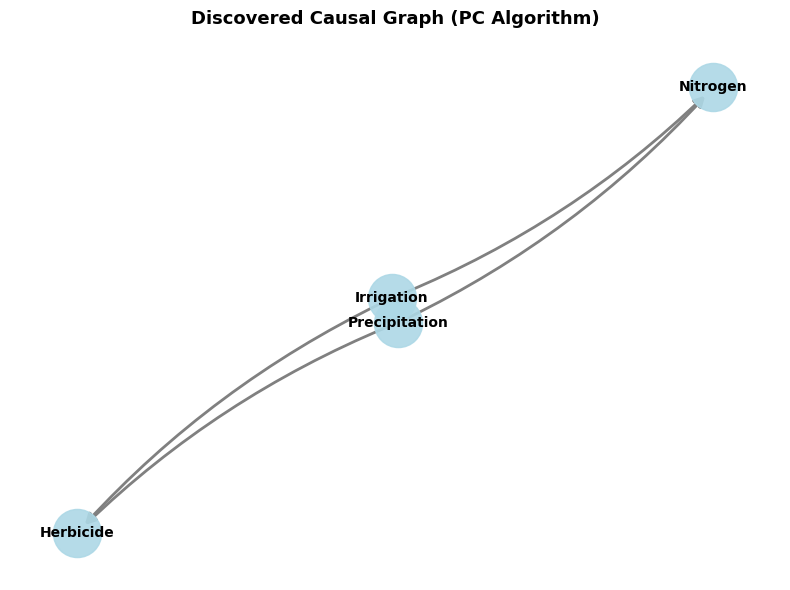

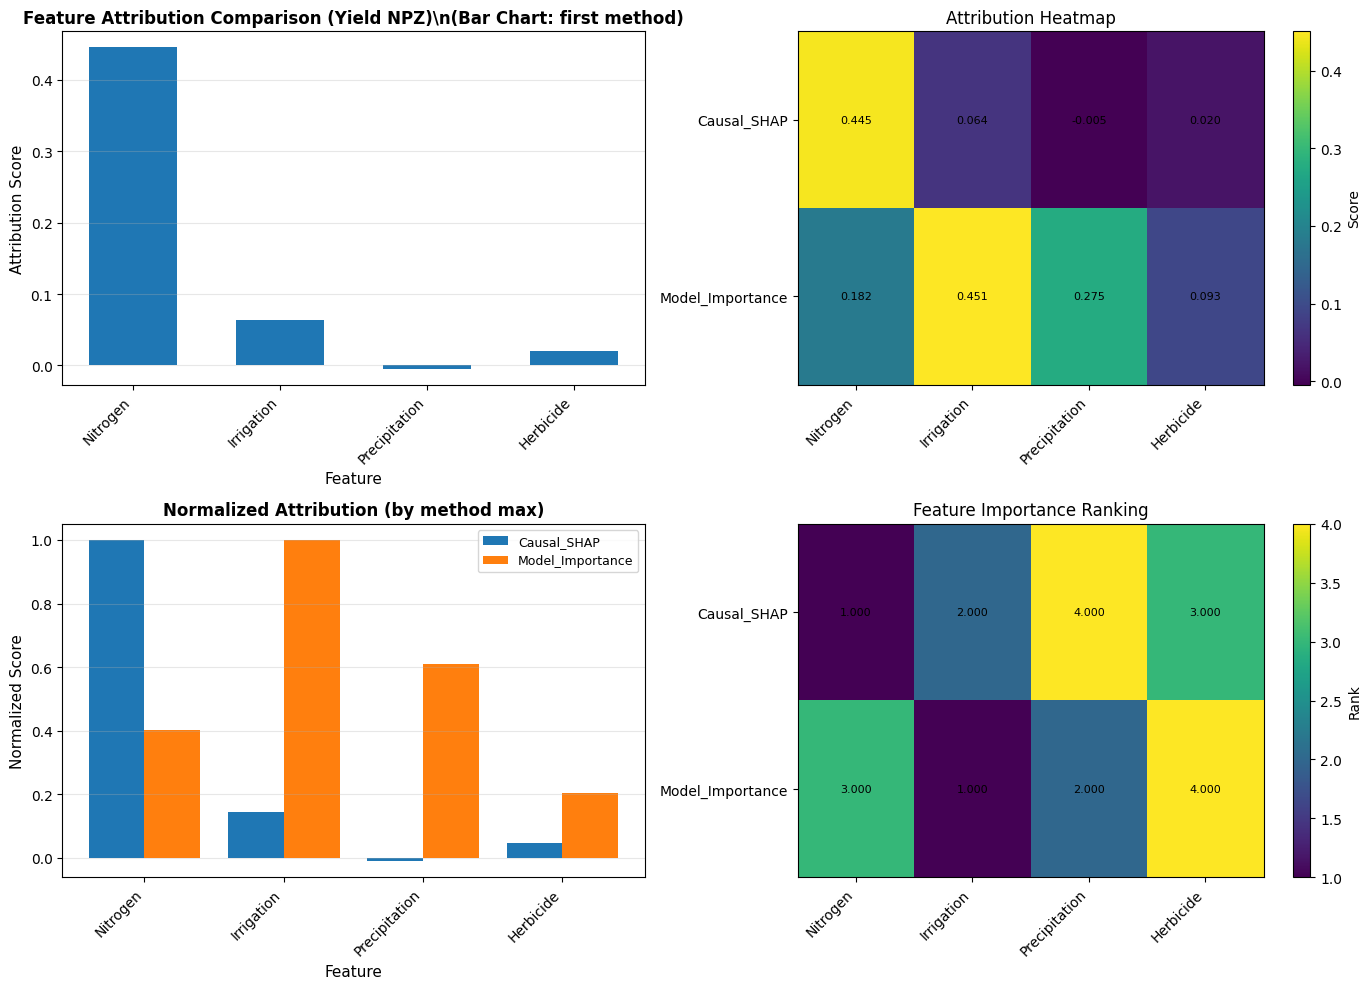

In [1]:
"""
CAUSAL SHAP on yield_preprocessed.npz
- Works with keys: X_train, X_test, y_train, y_test, feature_names
- Implements PC-based causal discovery, IDA-style causal effects, and Causal SHAP
- Saves outputs: causal graph PNG, comparison PNG, and CSV of attributions
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from typing import Dict, List, Tuple, Set
warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, accuracy_score
import networkx as nx

try:
    from xgboost import XGBClassifier
    HAVE_XGB = True
except:
    HAVE_XGB = False

from causallearn.search.ConstraintBased.PC import pc

# Configuration
CONFIG = {
    'DATA_PATH': '../../datasets/yield_preprocessed.npz',
    'ALPHA_PC': 0.9,
    'MAX_PERM': 200,
    'M_RESAMPLES': 64,
    'GLOBAL_K': 30,
    'RANDOM_SEED': 42,
    'N_DAGS': 5  # Sample multiple DAGs from CPDAG
}

np.random.seed(CONFIG['RANDOM_SEED'])
rng = np.random.default_rng(CONFIG['RANDOM_SEED'])


# 1. Causal Discovery & Structure Learning

class CausalStructure:
    """Handles causal discovery and DAG sampling from CPDAG"""

    def __init__(self, alpha=0.05):
        self.alpha = alpha
        self.cpdag = None
        self.feature_names = None
        self.dags = []

    def discover(self, X: pd.DataFrame):
        """Run PC algorithm on features"""
        self.feature_names = list(X.columns)
        print(f"Running PC algorithm on {len(self.feature_names)} features...")

        pc_res = pc(X.values, alpha=self.alpha, show_progress=False)
        self.cpdag = pc_res.G.graph

        print(f"Causal discovery complete")
        return self

    def get_skeleton(self) -> nx.DiGraph:
        """Convert CPDAG to networkx DiGraph"""
        G = nx.DiGraph()
        G.add_nodes_from(self.feature_names)

        n = len(self.feature_names)
        for i in range(n):
            for j in range(n):
                if i == j:
                    continue
                # Directed edge i->j
                if self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                    G.add_edge(self.feature_names[i], self.feature_names[j])
                # Undirected edge: add both directions
                elif self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1:
                    if i < j:  # Avoid double-adding
                        G.add_edge(self.feature_names[i], self.feature_names[j])
                        G.add_edge(self.feature_names[j], self.feature_names[i])

        return G

    def sample_dags(self, n_samples=5) -> List[nx.DiGraph]:
        """
        Sample multiple DAG orientations from CPDAG
        For undirected edges, randomly orient them
        """
        base_G = self.get_skeleton()
        dags = []

        # Find undirected edges
        undirected = []
        for i, u in enumerate(self.feature_names):
            for j, v in enumerate(self.feature_names):
                if i < j and self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1:
                    undirected.append((u, v))

        if len(undirected) == 0:
            # CPDAG is already fully directed
            print(f"  CPDAG is fully directed ({base_G.number_of_edges()} edges)")
            return [base_G]

        print(f"  Found {len(undirected)} undirected edges, sampling orientations...")

        # Sample orientations
        for _ in range(n_samples):
            G = nx.DiGraph()
            G.add_nodes_from(self.feature_names)

            # Add directed edges from CPDAG
            for i, u in enumerate(self.feature_names):
                for j, v in enumerate(self.feature_names):
                    if self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                        G.add_edge(u, v)

            # Randomly orient undirected edges (ensuring acyclicity)
            for u, v in undirected:
                if rng.random() < 0.5:
                    G.add_edge(u, v)
                else:
                    G.add_edge(v, u)

                # Check for cycles and reverse if needed
                if not nx.is_directed_acyclic_graph(G):
                    G.remove_edge(u, v) if G.has_edge(u, v) else G.remove_edge(v, u)
                    G.add_edge(v, u) if not G.has_edge(v, u) else G.add_edge(u, v)

            dags.append(G)

        self.dags = dags
        return dags


# 2. Causal Mechanism Learning

class LinearMechanisms:
    """Learn linear structural equation models"""

    def __init__(self, dag: nx.DiGraph, feature_names: List[str]):
        self.dag = dag
        self.feature_names = feature_names
        self.mechanisms = {}
        self.topo_order = None

    def fit(self, X: pd.DataFrame):
        """Fit linear mechanisms for each variable"""
        # Get topological order
        try:
            self.topo_order = list(nx.topological_sort(self.dag))
        except:
            # Fallback if cycles exist
            self.topo_order = self._safe_topo_order()

        for var in self.feature_names:
            parents = list(self.dag.predecessors(var))

            if not parents:
                # No parents: use marginal distribution
                self.mechanisms[var] = {
                    'parents': [],
                    'intercept': float(X[var].mean()),
                    'coef': None,
                    'sigma': float(X[var].std())
                }
            else:
                # Regress on parents
                lr = LinearRegression()
                lr.fit(X[parents].values, X[var].values)

                pred = lr.predict(X[parents].values)
                resid = X[var].values - pred

                self.mechanisms[var] = {
                    'parents': parents,
                    'intercept': float(lr.intercept_),
                    'coef': lr.coef_.astype(float),
                    'sigma': float(np.std(resid))
                }

        return self

    def _safe_topo_order(self) -> List[str]:
        """Fallback topological sort"""
        ordered = []
        remaining = set(self.feature_names)

        while remaining:
            # Find nodes with no remaining parents
            ready = [n for n in remaining
                    if all(p in ordered or p not in remaining
                           for p in self.dag.predecessors(n))]

            if not ready:
                # Force one with fewest remaining parents
                ready = [min(remaining,
                           key=lambda n: len([p for p in self.dag.predecessors(n)
                                            if p in remaining]))]

            for n in ready:
                ordered.append(n)
                remaining.remove(n)

        return ordered

    def sample_intervention(self, S: Set[str], x_obs: pd.Series, rng) -> Dict:
        """
        Sample from interventional distribution do(X_S = x_S)
        """
        x_new = {}

        for var in self.topo_order:
            if var in S:
                x_new[var] = float(x_obs[var])
            else:
                # Sample from mechanism
                mech = self.mechanisms[var]

                if not mech['parents']:
                    # No parents: sample from marginal
                    mu, sigma = mech['intercept'], mech['sigma']
                    if sigma < 1e-6:
                        x_new[var] = mu
                    else:
                        x_new[var] = float(rng.normal(mu, sigma))
                else:
                    # Sample from conditional
                    parent_vals = np.array([x_new.get(p, x_obs[p])
                                           for p in mech['parents']])

                    mu = mech['intercept'] + parent_vals @ mech['coef']
                    sigma = mech['sigma']
                    if sigma < 1e-6:
                        x_new[var] = mu
                    else:
                        x_new[var] = float(rng.normal(mu, sigma))

        return x_new


# 3. Causal Effect Estimation (IDA-style)

class CausalEffects:
    """Estimate total causal effects using path analysis"""

    def __init__(self, dags: List[nx.DiGraph], feature_names: List[str]):
        self.dags = dags
        self.feature_names = feature_names
        self.effects = {}

    def compute_effects(self, X: pd.DataFrame, y: pd.Series) -> Dict[str, float]:
        """
        Compute total causal effects for each feature on target
        Average over multiple DAG samples (IDA-style)
        """
        print("Computing causal effects (IDA-style)...")

        # Build augmented graphs with target
        aug_graphs = []

        for dag in self.dags:
            G = dag.copy()
            G.add_node('Y')

            # Add edges from features to Y with estimated weights
            for feat in self.feature_names:
                # Conditional regression: feat -> Y | other features
                other_feats = [f for f in self.feature_names if f != feat]
                if other_feats:
                    X_cond = np.column_stack([X[other_feats].values, X[feat].values])
                else:
                    X_cond = X[[feat]].values

                lr = LinearRegression()
                lr.fit(X_cond, y.values)
                weight = abs(lr.coef_[-1])

                if weight > 1e-6:
                    G.add_edge(feat, 'Y', weight=weight)

            # Add edge weights for feature->feature edges
            for u, v in dag.edges():
                parents = [p for p in dag.predecessors(v) if p != u]
                if parents:
                    X_reg = np.column_stack([X[parents].values, X[u].values])
                else:
                    X_reg = X[[u]].values

                lr = LinearRegression()
                lr.fit(X_reg, X[v].values)
                weight = abs(lr.coef_[-1])
                G[u][v]['weight'] = weight

            aug_graphs.append(G)

        # Compute total effects (average over DAGs)
        total_effects = {feat: [] for feat in self.feature_names}

        for G in aug_graphs:
            for feat in self.feature_names:
                effect = 0.0

                # Sum over all paths feat -> Y
                try:
                    for path in nx.all_simple_paths(G, feat, 'Y', cutoff=10):
                        path_effect = 1.0
                        for i in range(len(path) - 1):
                            edge_data = G.get_edge_data(path[i], path[i+1])
                            if edge_data and 'weight' in edge_data:
                                path_effect *= edge_data['weight']
                        effect += path_effect
                except:
                    pass

                total_effects[feat].append(effect)

        # Average across DAGs
        self.effects = {feat: np.mean(effects)
                       for feat, effects in total_effects.items()}

        print(f"Causal effects computed (averaged over {len(self.dags)} DAGs)")
        return self.effects

    def get_gamma_weights(self) -> Dict[str, float]:
        """Compute gamma weights (normalized absolute effects)"""
        abs_effects = {k: abs(v) for k, v in self.effects.items()}
        total = sum(abs_effects.values()) + 1e-12

        return {k: v / total for k, v in abs_effects.items()}


# 4. Causal SHAP Implementation

class CausalSHAP:
    """Main Causal SHAP implementation"""

    def __init__(self, model, causal_structure: CausalStructure,
                 X_train: pd.DataFrame, y_train: pd.Series):
        self.model = model
        self.structure = causal_structure
        self.X_train = X_train
        self.y_train = y_train
        self.feature_names = list(X_train.columns)

        print("\\nLearning causal mechanisms...")
        # Learn mechanisms and effects
        self.dags = causal_structure.sample_dags(n_samples=CONFIG['N_DAGS'])
        self.mechanisms_list = [LinearMechanisms(dag, self.feature_names).fit(X_train)
                               for dag in self.dags]

        # Compute causal effects
        self.causal_effects = CausalEffects(self.dags, self.feature_names)
        self.causal_effects.compute_effects(X_train, y_train)
        self.gamma = self.causal_effects.get_gamma_weights()

        print(f"Learned {len(self.dags)} DAG orientations")

    def _causal_value_function(self, S: Set[str], x: pd.Series,
                               pred_class: int, M: int) -> float:
        """
        v_c(S) = E[f(X) | do(X_S = x_S)]
        Average over DAG samples and Monte Carlo samples
        """
        total = 0.0
        samples_per_dag = max(1, M // len(self.mechanisms_list))

        for mechanisms in self.mechanisms_list:
            for _ in range(samples_per_dag):
                x_sample = mechanisms.sample_intervention(S, x, rng)
                X_mat = pd.DataFrame([x_sample], columns=self.feature_names)

                prob = self.model.predict_proba(X_mat.values)[0][pred_class]
                total += prob

        actual_samples = samples_per_dag * len(self.mechanisms_list)
        return total / actual_samples

    def explain_instance(self, x: pd.Series, n_perms: int = None,
                        m_samples: int = None) -> pd.Series:
        """
        Compute Causal SHAP values for a single instance
        """
        if n_perms is None:
            n_perms = CONFIG['MAX_PERM']
        if m_samples is None:
            m_samples = CONFIG['M_RESAMPLES']

        # Get predicted class
        probs = self.model.predict_proba(pd.DataFrame([x],
                                         columns=self.feature_names).values)[0]
        pred_class = int(np.argmax(probs))

        # Permutation-based estimation
        phi = np.zeros(len(self.feature_names))

        for _ in range(n_perms):
            perm = rng.permutation(self.feature_names)
            S = set()
            v_prev = self._causal_value_function(S, x, pred_class, m_samples)

            for feat in perm:
                S_next = S | {feat}
                v_curr = self._causal_value_function(S_next, x, pred_class, m_samples)

                delta = v_curr - v_prev
                contrib = self.gamma[feat] * delta  # Causal weighting

                phi[self.feature_names.index(feat)] += contrib
                v_prev = v_curr
                S = S_next

        phi /= n_perms

        # Normalize for local accuracy
        f_x = probs[pred_class]
        v_empty = self._causal_value_function(set(), x, pred_class, m_samples)

        sum_phi = np.sum(phi)
        if abs(sum_phi) > 1e-12:
            phi = phi * ((f_x - v_empty) / sum_phi)

        return pd.Series(phi, index=self.feature_names, name='Causal_SHAP')

    def explain_global(self, X_test: pd.DataFrame, n_samples: int = None) -> pd.Series:
        """Global explanation: average over test instances"""
        if n_samples is None:
            n_samples = CONFIG['GLOBAL_K']

        n_samples = min(n_samples, len(X_test))
        indices = rng.choice(len(X_test), size=n_samples, replace=False)

        print(f"\\nComputing global Causal SHAP (averaging over {n_samples} instances)...")
        explanations = []
        for i, idx in enumerate(indices):
            if (i + 1) % 5 == 0:
                print(f"  Progress: {i+1}/{n_samples}")
            exp = self.explain_instance(X_test.iloc[idx],
                                       n_perms=max(10, CONFIG['MAX_PERM']//4))
            explanations.append(exp)

        print("ok Global Causal SHAP computed")
        return pd.concat(explanations, axis=1).mean(axis=1).rename('Causal_SHAP_Global')


# 5. Baseline Methods for Comparison (optional SHAP if installed)

def compute_baseline_shap(model, X_train, X_test):
    """Compute Kernel SHAP values if shap is installed"""
    try:
        import shap
        print("\\nComputing KERNEL SHAP baseline...")
        bg_size = min(100, len(X_train))
        bg = shap.kmeans(X_train.values, bg_size)
        explainer = shap.KernelExplainer(lambda x: model.predict_proba(x), bg)
        shap_values = explainer.shap_values(X_test.values, nsamples=100)

        # Average absolute values across classes
        if isinstance(shap_values, list):
            global_imp = np.mean([np.abs(sv).mean(axis=0) for sv in shap_values], axis=0)
        else:
            global_imp = np.abs(shap_values).mean(axis=0)
        print("ok KERNEL SHAP computed")
        return pd.Series(global_imp, index=X_test.columns, name='SHAP_kernel')
    except Exception as e:
        print(f"Warning: SHAP computation skipped/failed: {e}")
        return None


def compute_feature_importance(model, feature_names):
    """Compute model's native feature importance"""
    if hasattr(model, 'feature_importances_'):
        imp = model.feature_importances_
        return pd.Series(imp, index=feature_names, name='Model_Importance')
    return None


# 6. Visualization (pure matplotlib, no seaborn)

def annotate_heatmap(ax, data: pd.DataFrame, title: str, cbar_label: str):
    im = ax.imshow(data.values, aspect='auto')
    ax.set_xticks(np.arange(data.shape[1]))
    ax.set_yticks(np.arange(data.shape[0]))
    ax.set_xticklabels(data.columns, rotation=45, ha='right')
    ax.set_yticklabels(data.index)
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            ax.text(j, i, f"{data.values[i, j]:.3f}", ha='center', va='center', fontsize=8)
    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label(cbar_label)
    ax.set_title(title)


def plot_comparison(df_comp: pd.DataFrame, title: str = "Feature Attribution Comparison"):
    """Visualize comparison of different methods (matplotlib only)"""
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    # Bar plot
    axes[0, 0].bar(np.arange(df_comp.shape[0]), df_comp.iloc[:, 0], width=0.6)
    axes[0, 0].set_title(f'{title}\\n(Bar Chart: first method)', fontsize=12, fontweight='bold')
    axes[0, 0].set_ylabel('Attribution Score', fontsize=11)
    axes[0, 0].set_xlabel('Feature', fontsize=11)
    axes[0, 0].set_xticks(np.arange(df_comp.shape[0]))
    axes[0, 0].set_xticklabels(df_comp.index, rotation=45, ha='right')
    axes[0, 0].grid(axis='y', alpha=0.3)

    # Heatmap
    annotate_heatmap(axes[0, 1], df_comp.T, 'Attribution Heatmap', 'Score')

    # Normalized comparison
    df_norm = df_comp.div(df_comp.abs().max(axis=0), axis=1)
    for i, col in enumerate(df_norm.columns):
        axes[1, 0].bar(np.arange(df_norm.shape[0]) + (i-0.5)*(0.8/len(df_norm.columns)), df_norm[col], width=0.8/len(df_norm.columns), label=col)
    axes[1, 0].set_title('Normalized Attribution (by method max)', fontsize=12, fontweight='bold')
    axes[1, 0].set_ylabel('Normalized Score', fontsize=11)
    axes[1, 0].set_xlabel('Feature', fontsize=11)
    axes[1, 0].set_xticks(np.arange(df_norm.shape[0]))
    axes[1, 0].set_xticklabels(df_norm.index, rotation=45, ha='right')
    axes[1, 0].legend(loc='best', fontsize=9)
    axes[1, 0].grid(axis='y', alpha=0.3)

    # Rank comparison heatmap
    ranks = df_comp.rank(ascending=False)
    annotate_heatmap(axes[1, 1], ranks.T, 'Feature Importance Ranking', 'Rank')

    fig.tight_layout()
    return fig


def plot_causal_graph(G: nx.DiGraph, title: str = "Discovered Causal Graph"):
    """Visualize the causal graph"""
    plt.figure(figsize=(8, 6))
    pos = nx.spring_layout(G, seed=CONFIG['RANDOM_SEED'], k=1.0, iterations=200)

    nx.draw_networkx_nodes(G, pos, node_color='lightblue', node_size=1200, alpha=0.9)
    nx.draw_networkx_edges(G, pos, edge_color='gray', arrows=True, arrowsize=15,
                           arrowstyle='->', width=2, connectionstyle='arc3,rad=0.1')
    nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')

    plt.title(title, fontsize=13, fontweight='bold', pad=12)
    plt.axis('off')
    plt.tight_layout()
    return plt.gcf()


# 7. Main Execution

def main():
    """Run complete Causal SHAP analysis on NPZ dataset"""

    print("\\n" + "="*70)
    print("CAUSAL SHAP on NPZ Dataset")
    print("="*70 + "\\n")

    # Load data
    print("Loading NPZ dataset...")
    try:
        data = np.load(CONFIG['DATA_PATH'], allow_pickle=True)
        keys = list(data.keys())
        print(f"NPZ loaded with keys: {keys}")
    except FileNotFoundError:
        print(f"ERROR: Could not find '{CONFIG['DATA_PATH']}'")
        print("Please ensure the file is in the current directory.")
        return

    required_keys = {'X_train', 'X_test', 'y_train', 'y_test', 'feature_names'}
    if not required_keys.issubset(set(keys)):
        print("ERROR: NPZ must contain X_train, X_test, y_train, y_test, feature_names.")
        return

    # Extract
    X_train = pd.DataFrame(data['X_train'], columns=list(data['feature_names']))
    X_test  = pd.DataFrame(data['X_test'],  columns=list(data['feature_names']))
    y_train = pd.Series(data['y_train'].astype(int))
    y_test  = pd.Series(data['y_test'].astype(int))

    print(f"Shapes: X_train={X_train.shape}, X_test={X_test.shape}, y_train={y_train.shape}, y_test={y_test.shape}")
    print(f"Features: {', '.join(X_train.columns)}")
    n_classes = len(np.unique(y_train))
    print(f"Target classes: {n_classes}")

    # Scale features using training stats
    scaler = StandardScaler()
    X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
    X_test_scaled  = pd.DataFrame(scaler.transform(X_test),  columns=X_test.columns)

    # Train model
    print("\\n" + "="*70)
    print("Training Model")
    print("="*70)

    if HAVE_XGB:
        model = XGBClassifier(
            n_estimators=160,
            max_depth=5,
            learning_rate=0.08,
            subsample=0.9,
            colsample_bytree=0.9,
            random_state=CONFIG['RANDOM_SEED'],
            verbosity=0,
            objective="multi:softprob",
            num_class=n_classes,
        )
        print("Using XGBoost classifier")
    else:
        model = RandomForestClassifier(
            n_estimators=160,
            max_depth=6,
            random_state=CONFIG['RANDOM_SEED']
        )
        print("Using Random Forest classifier")

    model.fit(X_train_scaled.values, y_train.values)

    y_pred = model.predict(X_test_scaled.values)
    f1 = f1_score(y_test, y_pred, average='macro')
    acc = accuracy_score(y_test, y_pred)

    print(f"Model trained")
    print(f"  Test Accuracy: {acc:.4f}")
    print(f"  Test Macro F1: {f1:.4f}")

    # Causal Discovery
    print("\\n" + "="*70)
    print("Step 1: Causal Discovery (PC Algorithm)")
    print("="*70)

    causal_structure = CausalStructure(alpha=CONFIG['ALPHA_PC'])
    causal_structure.discover(X_train_scaled)

    # Visualize discovered graph
    G = causal_structure.get_skeleton()
    print(f"\\nDiscovered graph: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")

    fig_graph = plot_causal_graph(G, "Discovered Causal Graph (PC Algorithm)")
    fig_graph.savefig('causal_graph_yield.png', dpi=150, bbox_inches='tight')
    print("ok Causal graph saved to 'causal_graph_yield.png'")

    # Causal SHAP
    print("\\n" + "="*70)
    print("Step 2: Computing Causal SHAP")
    print("="*70)

    causal_shap = CausalSHAP(model, causal_structure, X_train_scaled, y_train)

    # Show causal effects
    print("\\nTotal Causal Effects (W_i):")
    print("-" * 40)
    for feat in X_train.columns:
        effect = causal_shap.causal_effects.effects[feat]
        gamma = causal_shap.gamma[feat]
        print(f"  {feat:15s}: W={effect:8.4f}  γ={gamma:.4f}")

    # Global explanation
    global_causal_shap = causal_shap.explain_global(X_test_scaled, n_samples=CONFIG['GLOBAL_K'])

    # Baseline methods (optional)
    print("\\n" + "="*70)
    print("Step 3: Computing Baseline Methods")
    print("="*70)
    baseline_shap = compute_baseline_shap(model, X_train_scaled, X_test_scaled)
    model_imp = compute_feature_importance(model, list(X_train.columns))

    # Comparison
    print("\\n" + "="*70)
    print("Step 4: Results Comparison")
    print("="*70)

    attributions = {
        'Causal_SHAP': global_causal_shap,
    }

    if baseline_shap is not None:
        attributions['Kernel_SHAP'] = baseline_shap

    if model_imp is not None:
        attributions['Model_Importance'] = model_imp

    df_comparison = pd.DataFrame(attributions)
    df_comparison.to_csv('attribution_scores_yield.csv', index=True)

    print("\\n" + "="*70)
    print("Attribution Scores:")
    print("="*70)
    print(df_comparison.round(6).to_string())
    print("\\nSaved CSV -> attribution_scores_yield.csv")

    # Correlation analysis
    if len(attributions) > 1:
        print("\\n" + "="*70)
        print("Correlation between methods:")
        print("="*70)
        corr_matrix = df_comparison.corr()
        print(corr_matrix.round(4).to_string())

    # Visualization
    fig = plot_comparison(df_comparison,
                         title="Feature Attribution Comparison (Yield NPZ)")
    fig.savefig('attribution_comparison_yield.png', dpi=150, bbox_inches='tight')
    print("\\nok Comparison plot saved to 'attribution_comparison_yield.png'")

    try:
        plt.show()
    except Exception:
        pass

if __name__ == "__main__":
    main()

\n======================================================================
CAUSAL SHAP on NPZ Dataset
======================================================================\n
Loading NPZ dataset...
✓ NPZ loaded with keys: ['X_train', 'X_test', 'y_train', 'y_test', 'feature_names']
Shapes: X_train=(800, 4), X_test=(200, 4), y_train=(800,), y_test=(200,)
Features: Nitrogen, Irrigation, Precipitation, Herbicide
Target classes: 3
\n======================================================================
Training Model
Using XGBoost classifier
✓ Model trained
  Test Accuracy: 0.8050
  Test Macro F1: 0.8081
\n======================================================================
Step 1: Causal Discovery (PC Algorithm)
Running PC algorithm on 4 features...
✓ Causal discovery complete
\nDiscovered graph: 4 nodes, 4 edges
✓ Causal graph saved to 'causal_graph_yield.png'
\n======================================================================
Step 2: Computing Causal SHAP
\nLearning causal mechanism

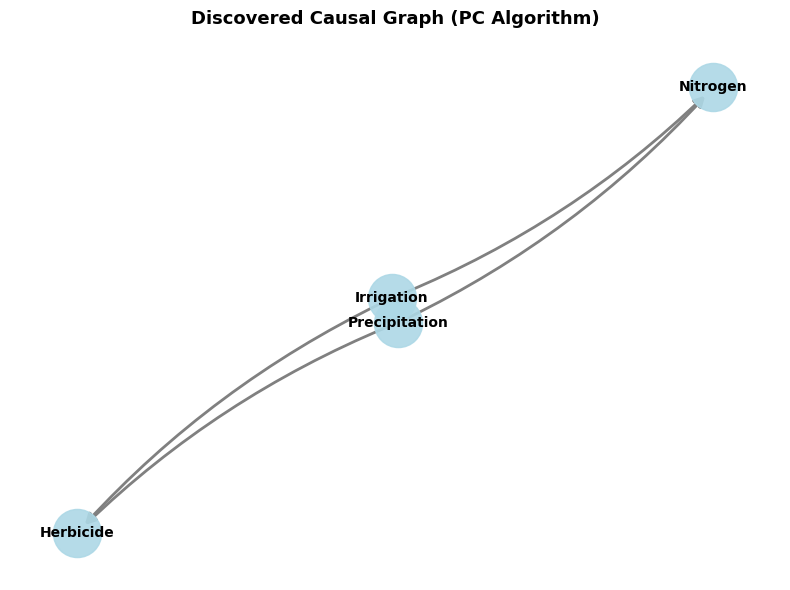

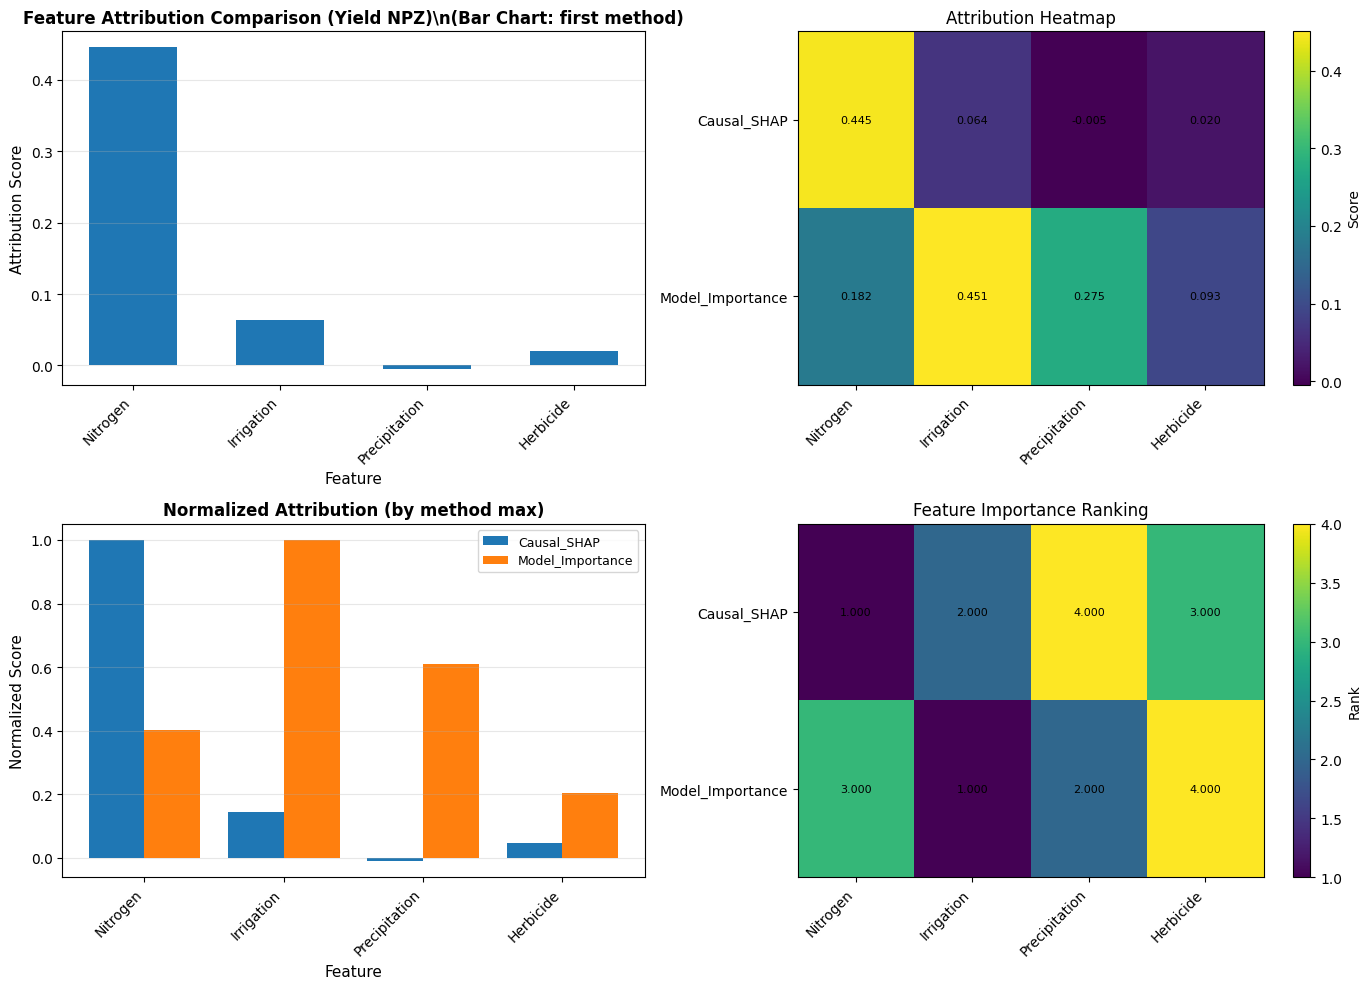

In [2]:
"""
CAUSAL SHAP on yield_preprocessed.npz
- Works with keys: X_train, X_test, y_train, y_test, feature_names
- Implements PC-based causal discovery, IDA-style causal effects, and Causal SHAP
- Saves outputs: causal graph PNG, comparison PNG, and CSV of attributions
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from typing import Dict, List, Tuple, Set
warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, accuracy_score
import networkx as nx

try:
    from xgboost import XGBClassifier
    HAVE_XGB = True
except:
    HAVE_XGB = False

from causallearn.search.ConstraintBased.PC import pc

# Configuration
CONFIG = {
    'DATA_PATH': '../../datasets/yield_preprocessed.npz',
    'ALPHA_PC': 0.5,
    'MAX_PERM': 200,
    'M_RESAMPLES': 64,
    'GLOBAL_K': 30,
    'RANDOM_SEED': 42,
    'N_DAGS': 5  # Sample multiple DAGs from CPDAG
}

np.random.seed(CONFIG['RANDOM_SEED'])
rng = np.random.default_rng(CONFIG['RANDOM_SEED'])


# 1. Causal Discovery & Structure Learning

class CausalStructure:
    """Handles causal discovery and DAG sampling from CPDAG"""

    def __init__(self, alpha=0.05):
        self.alpha = alpha
        self.cpdag = None
        self.feature_names = None
        self.dags = []

    def discover(self, X: pd.DataFrame):
        """Run PC algorithm on features"""
        self.feature_names = list(X.columns)
        print(f"Running PC algorithm on {len(self.feature_names)} features...")

        pc_res = pc(X.values, alpha=self.alpha, show_progress=False)
        self.cpdag = pc_res.G.graph

        print(f"Causal discovery complete")
        return self

    def get_skeleton(self) -> nx.DiGraph:
        """Convert CPDAG to networkx DiGraph"""
        G = nx.DiGraph()
        G.add_nodes_from(self.feature_names)

        n = len(self.feature_names)
        for i in range(n):
            for j in range(n):
                if i == j:
                    continue
                # Directed edge i->j
                if self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                    G.add_edge(self.feature_names[i], self.feature_names[j])
                # Undirected edge: add both directions
                elif self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1:
                    if i < j:  # Avoid double-adding
                        G.add_edge(self.feature_names[i], self.feature_names[j])
                        G.add_edge(self.feature_names[j], self.feature_names[i])

        return G

    def sample_dags(self, n_samples=5) -> List[nx.DiGraph]:
        """
        Sample multiple DAG orientations from CPDAG
        For undirected edges, randomly orient them
        """
        base_G = self.get_skeleton()
        dags = []

        # Find undirected edges
        undirected = []
        for i, u in enumerate(self.feature_names):
            for j, v in enumerate(self.feature_names):
                if i < j and self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1:
                    undirected.append((u, v))

        if len(undirected) == 0:
            # CPDAG is already fully directed
            print(f"  CPDAG is fully directed ({base_G.number_of_edges()} edges)")
            return [base_G]

        print(f"  Found {len(undirected)} undirected edges, sampling orientations...")

        # Sample orientations
        for _ in range(n_samples):
            G = nx.DiGraph()
            G.add_nodes_from(self.feature_names)

            # Add directed edges from CPDAG
            for i, u in enumerate(self.feature_names):
                for j, v in enumerate(self.feature_names):
                    if self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                        G.add_edge(u, v)

            # Randomly orient undirected edges (ensuring acyclicity)
            for u, v in undirected:
                if rng.random() < 0.5:
                    G.add_edge(u, v)
                else:
                    G.add_edge(v, u)

                # Check for cycles and reverse if needed
                if not nx.is_directed_acyclic_graph(G):
                    G.remove_edge(u, v) if G.has_edge(u, v) else G.remove_edge(v, u)
                    G.add_edge(v, u) if not G.has_edge(v, u) else G.add_edge(u, v)

            dags.append(G)

        self.dags = dags
        return dags


# 2. Causal Mechanism Learning

class LinearMechanisms:
    """Learn linear structural equation models"""

    def __init__(self, dag: nx.DiGraph, feature_names: List[str]):
        self.dag = dag
        self.feature_names = feature_names
        self.mechanisms = {}
        self.topo_order = None

    def fit(self, X: pd.DataFrame):
        """Fit linear mechanisms for each variable"""
        # Get topological order
        try:
            self.topo_order = list(nx.topological_sort(self.dag))
        except:
            # Fallback if cycles exist
            self.topo_order = self._safe_topo_order()

        for var in self.feature_names:
            parents = list(self.dag.predecessors(var))

            if not parents:
                # No parents: use marginal distribution
                self.mechanisms[var] = {
                    'parents': [],
                    'intercept': float(X[var].mean()),
                    'coef': None,
                    'sigma': float(X[var].std())
                }
            else:
                # Regress on parents
                lr = LinearRegression()
                lr.fit(X[parents].values, X[var].values)

                pred = lr.predict(X[parents].values)
                resid = X[var].values - pred

                self.mechanisms[var] = {
                    'parents': parents,
                    'intercept': float(lr.intercept_),
                    'coef': lr.coef_.astype(float),
                    'sigma': float(np.std(resid))
                }

        return self

    def _safe_topo_order(self) -> List[str]:
        """Fallback topological sort"""
        ordered = []
        remaining = set(self.feature_names)

        while remaining:
            # Find nodes with no remaining parents
            ready = [n for n in remaining
                    if all(p in ordered or p not in remaining
                           for p in self.dag.predecessors(n))]

            if not ready:
                # Force one with fewest remaining parents
                ready = [min(remaining,
                           key=lambda n: len([p for p in self.dag.predecessors(n)
                                            if p in remaining]))]

            for n in ready:
                ordered.append(n)
                remaining.remove(n)

        return ordered

    def sample_intervention(self, S: Set[str], x_obs: pd.Series, rng) -> Dict:
        """
        Sample from interventional distribution do(X_S = x_S)
        """
        x_new = {}

        for var in self.topo_order:
            if var in S:
                x_new[var] = float(x_obs[var])
            else:
                # Sample from mechanism
                mech = self.mechanisms[var]

                if not mech['parents']:
                    # No parents: sample from marginal
                    mu, sigma = mech['intercept'], mech['sigma']
                    if sigma < 1e-6:
                        x_new[var] = mu
                    else:
                        x_new[var] = float(rng.normal(mu, sigma))
                else:
                    # Sample from conditional
                    parent_vals = np.array([x_new.get(p, x_obs[p])
                                           for p in mech['parents']])

                    mu = mech['intercept'] + parent_vals @ mech['coef']
                    sigma = mech['sigma']
                    if sigma < 1e-6:
                        x_new[var] = mu
                    else:
                        x_new[var] = float(rng.normal(mu, sigma))

        return x_new


# 3. Causal Effect Estimation (IDA-style)

class CausalEffects:
    """Estimate total causal effects using path analysis"""

    def __init__(self, dags: List[nx.DiGraph], feature_names: List[str]):
        self.dags = dags
        self.feature_names = feature_names
        self.effects = {}

    def compute_effects(self, X: pd.DataFrame, y: pd.Series) -> Dict[str, float]:
        """
        Compute total causal effects for each feature on target
        Average over multiple DAG samples (IDA-style)
        """
        print("Computing causal effects (IDA-style)...")

        # Build augmented graphs with target
        aug_graphs = []

        for dag in self.dags:
            G = dag.copy()
            G.add_node('Y')

            # Add edges from features to Y with estimated weights
            for feat in self.feature_names:
                # Conditional regression: feat -> Y | other features
                other_feats = [f for f in self.feature_names if f != feat]
                if other_feats:
                    X_cond = np.column_stack([X[other_feats].values, X[feat].values])
                else:
                    X_cond = X[[feat]].values

                lr = LinearRegression()
                lr.fit(X_cond, y.values)
                weight = abs(lr.coef_[-1])

                if weight > 1e-6:
                    G.add_edge(feat, 'Y', weight=weight)

            # Add edge weights for feature->feature edges
            for u, v in dag.edges():
                parents = [p for p in dag.predecessors(v) if p != u]
                if parents:
                    X_reg = np.column_stack([X[parents].values, X[u].values])
                else:
                    X_reg = X[[u]].values

                lr = LinearRegression()
                lr.fit(X_reg, X[v].values)
                weight = abs(lr.coef_[-1])
                G[u][v]['weight'] = weight

            aug_graphs.append(G)

        # Compute total effects (average over DAGs)
        total_effects = {feat: [] for feat in self.feature_names}

        for G in aug_graphs:
            for feat in self.feature_names:
                effect = 0.0

                # Sum over all paths feat -> Y
                try:
                    for path in nx.all_simple_paths(G, feat, 'Y', cutoff=10):
                        path_effect = 1.0
                        for i in range(len(path) - 1):
                            edge_data = G.get_edge_data(path[i], path[i+1])
                            if edge_data and 'weight' in edge_data:
                                path_effect *= edge_data['weight']
                        effect += path_effect
                except:
                    pass

                total_effects[feat].append(effect)

        # Average across DAGs
        self.effects = {feat: np.mean(effects)
                       for feat, effects in total_effects.items()}

        print(f"Causal effects computed (averaged over {len(self.dags)} DAGs)")
        return self.effects

    def get_gamma_weights(self) -> Dict[str, float]:
        """Compute gamma weights (normalized absolute effects)"""
        abs_effects = {k: abs(v) for k, v in self.effects.items()}
        total = sum(abs_effects.values()) + 1e-12

        return {k: v / total for k, v in abs_effects.items()}


# 4. Causal SHAP Implementation

class CausalSHAP:
    """Main Causal SHAP implementation"""

    def __init__(self, model, causal_structure: CausalStructure,
                 X_train: pd.DataFrame, y_train: pd.Series):
        self.model = model
        self.structure = causal_structure
        self.X_train = X_train
        self.y_train = y_train
        self.feature_names = list(X_train.columns)

        print("\\nLearning causal mechanisms...")
        # Learn mechanisms and effects
        self.dags = causal_structure.sample_dags(n_samples=CONFIG['N_DAGS'])
        self.mechanisms_list = [LinearMechanisms(dag, self.feature_names).fit(X_train)
                               for dag in self.dags]

        # Compute causal effects
        self.causal_effects = CausalEffects(self.dags, self.feature_names)
        self.causal_effects.compute_effects(X_train, y_train)
        self.gamma = self.causal_effects.get_gamma_weights()

        print(f"Learned {len(self.dags)} DAG orientations")

    def _causal_value_function(self, S: Set[str], x: pd.Series,
                               pred_class: int, M: int) -> float:
        """
        v_c(S) = E[f(X) | do(X_S = x_S)]
        Average over DAG samples and Monte Carlo samples
        """
        total = 0.0
        samples_per_dag = max(1, M // len(self.mechanisms_list))

        for mechanisms in self.mechanisms_list:
            for _ in range(samples_per_dag):
                x_sample = mechanisms.sample_intervention(S, x, rng)
                X_mat = pd.DataFrame([x_sample], columns=self.feature_names)

                prob = self.model.predict_proba(X_mat.values)[0][pred_class]
                total += prob

        actual_samples = samples_per_dag * len(self.mechanisms_list)
        return total / actual_samples

    def explain_instance(self, x: pd.Series, n_perms: int = None,
                        m_samples: int = None) -> pd.Series:
        """
        Compute Causal SHAP values for a single instance
        """
        if n_perms is None:
            n_perms = CONFIG['MAX_PERM']
        if m_samples is None:
            m_samples = CONFIG['M_RESAMPLES']

        # Get predicted class
        probs = self.model.predict_proba(pd.DataFrame([x],
                                         columns=self.feature_names).values)[0]
        pred_class = int(np.argmax(probs))

        # Permutation-based estimation
        phi = np.zeros(len(self.feature_names))

        for _ in range(n_perms):
            perm = rng.permutation(self.feature_names)
            S = set()
            v_prev = self._causal_value_function(S, x, pred_class, m_samples)

            for feat in perm:
                S_next = S | {feat}
                v_curr = self._causal_value_function(S_next, x, pred_class, m_samples)

                delta = v_curr - v_prev
                contrib = self.gamma[feat] * delta  # Causal weighting

                phi[self.feature_names.index(feat)] += contrib
                v_prev = v_curr
                S = S_next

        phi /= n_perms

        # Normalize for local accuracy
        f_x = probs[pred_class]
        v_empty = self._causal_value_function(set(), x, pred_class, m_samples)

        sum_phi = np.sum(phi)
        if abs(sum_phi) > 1e-12:
            phi = phi * ((f_x - v_empty) / sum_phi)

        return pd.Series(phi, index=self.feature_names, name='Causal_SHAP')

    def explain_global(self, X_test: pd.DataFrame, n_samples: int = None) -> pd.Series:
        """Global explanation: average over test instances"""
        if n_samples is None:
            n_samples = CONFIG['GLOBAL_K']

        n_samples = min(n_samples, len(X_test))
        indices = rng.choice(len(X_test), size=n_samples, replace=False)

        print(f"\\nComputing global Causal SHAP (averaging over {n_samples} instances)...")
        explanations = []
        for i, idx in enumerate(indices):
            if (i + 1) % 5 == 0:
                print(f"  Progress: {i+1}/{n_samples}")
            exp = self.explain_instance(X_test.iloc[idx],
                                       n_perms=max(10, CONFIG['MAX_PERM']//4))
            explanations.append(exp)

        print("ok Global Causal SHAP computed")
        return pd.concat(explanations, axis=1).mean(axis=1).rename('Causal_SHAP_Global')


# 5. Baseline Methods for Comparison (optional SHAP if installed)

def compute_baseline_shap(model, X_train, X_test):
    """Compute Kernel SHAP values if shap is installed"""
    try:
        import shap
        print("\\nComputing KERNEL SHAP baseline...")
        bg_size = min(100, len(X_train))
        bg = shap.kmeans(X_train.values, bg_size)
        explainer = shap.KernelExplainer(lambda x: model.predict_proba(x), bg)
        shap_values = explainer.shap_values(X_test.values, nsamples=100)

        # Average absolute values across classes
        if isinstance(shap_values, list):
            global_imp = np.mean([np.abs(sv).mean(axis=0) for sv in shap_values], axis=0)
        else:
            global_imp = np.abs(shap_values).mean(axis=0)
        print("ok KERNEL SHAP computed")
        return pd.Series(global_imp, index=X_test.columns, name='SHAP_kernel')
    except Exception as e:
        print(f"Warning: SHAP computation skipped/failed: {e}")
        return None


def compute_feature_importance(model, feature_names):
    """Compute model's native feature importance"""
    if hasattr(model, 'feature_importances_'):
        imp = model.feature_importances_
        return pd.Series(imp, index=feature_names, name='Model_Importance')
    return None


# 6. Visualization (pure matplotlib, no seaborn)

def annotate_heatmap(ax, data: pd.DataFrame, title: str, cbar_label: str):
    im = ax.imshow(data.values, aspect='auto')
    ax.set_xticks(np.arange(data.shape[1]))
    ax.set_yticks(np.arange(data.shape[0]))
    ax.set_xticklabels(data.columns, rotation=45, ha='right')
    ax.set_yticklabels(data.index)
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            ax.text(j, i, f"{data.values[i, j]:.3f}", ha='center', va='center', fontsize=8)
    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label(cbar_label)
    ax.set_title(title)


def plot_comparison(df_comp: pd.DataFrame, title: str = "Feature Attribution Comparison"):
    """Visualize comparison of different methods (matplotlib only)"""
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    # Bar plot
    axes[0, 0].bar(np.arange(df_comp.shape[0]), df_comp.iloc[:, 0], width=0.6)
    axes[0, 0].set_title(f'{title}\\n(Bar Chart: first method)', fontsize=12, fontweight='bold')
    axes[0, 0].set_ylabel('Attribution Score', fontsize=11)
    axes[0, 0].set_xlabel('Feature', fontsize=11)
    axes[0, 0].set_xticks(np.arange(df_comp.shape[0]))
    axes[0, 0].set_xticklabels(df_comp.index, rotation=45, ha='right')
    axes[0, 0].grid(axis='y', alpha=0.3)

    # Heatmap
    annotate_heatmap(axes[0, 1], df_comp.T, 'Attribution Heatmap', 'Score')

    # Normalized comparison
    df_norm = df_comp.div(df_comp.abs().max(axis=0), axis=1)
    for i, col in enumerate(df_norm.columns):
        axes[1, 0].bar(np.arange(df_norm.shape[0]) + (i-0.5)*(0.8/len(df_norm.columns)), df_norm[col], width=0.8/len(df_norm.columns), label=col)
    axes[1, 0].set_title('Normalized Attribution (by method max)', fontsize=12, fontweight='bold')
    axes[1, 0].set_ylabel('Normalized Score', fontsize=11)
    axes[1, 0].set_xlabel('Feature', fontsize=11)
    axes[1, 0].set_xticks(np.arange(df_norm.shape[0]))
    axes[1, 0].set_xticklabels(df_norm.index, rotation=45, ha='right')
    axes[1, 0].legend(loc='best', fontsize=9)
    axes[1, 0].grid(axis='y', alpha=0.3)

    # Rank comparison heatmap
    ranks = df_comp.rank(ascending=False)
    annotate_heatmap(axes[1, 1], ranks.T, 'Feature Importance Ranking', 'Rank')

    fig.tight_layout()
    return fig


def plot_causal_graph(G: nx.DiGraph, title: str = "Discovered Causal Graph"):
    """Visualize the causal graph"""
    plt.figure(figsize=(8, 6))
    pos = nx.spring_layout(G, seed=CONFIG['RANDOM_SEED'], k=1.0, iterations=200)

    nx.draw_networkx_nodes(G, pos, node_color='lightblue', node_size=1200, alpha=0.9)
    nx.draw_networkx_edges(G, pos, edge_color='gray', arrows=True, arrowsize=15,
                           arrowstyle='->', width=2, connectionstyle='arc3,rad=0.1')
    nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')

    plt.title(title, fontsize=13, fontweight='bold', pad=12)
    plt.axis('off')
    plt.tight_layout()
    return plt.gcf()


# 7. Main Execution

def main():
    """Run complete Causal SHAP analysis on NPZ dataset"""

    print("\\n" + "="*70)
    print("CAUSAL SHAP on NPZ Dataset")
    print("="*70 + "\\n")

    # Load data
    print("Loading NPZ dataset...")
    try:
        data = np.load(CONFIG['DATA_PATH'], allow_pickle=True)
        keys = list(data.keys())
        print(f"NPZ loaded with keys: {keys}")
    except FileNotFoundError:
        print(f"ERROR: Could not find '{CONFIG['DATA_PATH']}'")
        print("Please ensure the file is in the current directory.")
        return

    required_keys = {'X_train', 'X_test', 'y_train', 'y_test', 'feature_names'}
    if not required_keys.issubset(set(keys)):
        print("ERROR: NPZ must contain X_train, X_test, y_train, y_test, feature_names.")
        return

    # Extract
    X_train = pd.DataFrame(data['X_train'], columns=list(data['feature_names']))
    X_test  = pd.DataFrame(data['X_test'],  columns=list(data['feature_names']))
    y_train = pd.Series(data['y_train'].astype(int))
    y_test  = pd.Series(data['y_test'].astype(int))

    print(f"Shapes: X_train={X_train.shape}, X_test={X_test.shape}, y_train={y_train.shape}, y_test={y_test.shape}")
    print(f"Features: {', '.join(X_train.columns)}")
    n_classes = len(np.unique(y_train))
    print(f"Target classes: {n_classes}")

    # Scale features using training stats
    scaler = StandardScaler()
    X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
    X_test_scaled  = pd.DataFrame(scaler.transform(X_test),  columns=X_test.columns)

    # Train model
    print("\\n" + "="*70)
    print("Training Model")
    print("="*70)

    if HAVE_XGB:
        model = XGBClassifier(
            n_estimators=160,
            max_depth=5,
            learning_rate=0.08,
            subsample=0.9,
            colsample_bytree=0.9,
            random_state=CONFIG['RANDOM_SEED'],
            verbosity=0,
            objective="multi:softprob",
            num_class=n_classes,
        )
        print("Using XGBoost classifier")
    else:
        model = RandomForestClassifier(
            n_estimators=160,
            max_depth=6,
            random_state=CONFIG['RANDOM_SEED']
        )
        print("Using Random Forest classifier")

    model.fit(X_train_scaled.values, y_train.values)

    y_pred = model.predict(X_test_scaled.values)
    f1 = f1_score(y_test, y_pred, average='macro')
    acc = accuracy_score(y_test, y_pred)

    print(f"Model trained")
    print(f"  Test Accuracy: {acc:.4f}")
    print(f"  Test Macro F1: {f1:.4f}")

    # Causal Discovery
    print("\\n" + "="*70)
    print("Step 1: Causal Discovery (PC Algorithm)")
    print("="*70)

    causal_structure = CausalStructure(alpha=CONFIG['ALPHA_PC'])
    causal_structure.discover(X_train_scaled)

    # Visualize discovered graph
    G = causal_structure.get_skeleton()
    print(f"\\nDiscovered graph: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")

    fig_graph = plot_causal_graph(G, "Discovered Causal Graph (PC Algorithm)")
    fig_graph.savefig('causal_graph_yield.png', dpi=150, bbox_inches='tight')
    print("ok Causal graph saved to 'causal_graph_yield.png'")

    # Causal SHAP
    print("\\n" + "="*70)
    print("Step 2: Computing Causal SHAP")
    print("="*70)

    causal_shap = CausalSHAP(model, causal_structure, X_train_scaled, y_train)

    # Show causal effects
    print("\\nTotal Causal Effects (W_i):")
    print("-" * 40)
    for feat in X_train.columns:
        effect = causal_shap.causal_effects.effects[feat]
        gamma = causal_shap.gamma[feat]
        print(f"  {feat:15s}: W={effect:8.4f}  γ={gamma:.4f}")

    # Global explanation
    global_causal_shap = causal_shap.explain_global(X_test_scaled, n_samples=CONFIG['GLOBAL_K'])

    # Baseline methods (optional)
    print("\\n" + "="*70)
    print("Step 3: Computing Baseline Methods")
    print("="*70)
    baseline_shap = compute_baseline_shap(model, X_train_scaled, X_test_scaled)
    model_imp = compute_feature_importance(model, list(X_train.columns))

    # Comparison
    print("\\n" + "="*70)
    print("Step 4: Results Comparison")
    print("="*70)

    attributions = {
        'Causal_SHAP': global_causal_shap,
    }

    if baseline_shap is not None:
        attributions['Kernel_SHAP'] = baseline_shap

    if model_imp is not None:
        attributions['Model_Importance'] = model_imp

    df_comparison = pd.DataFrame(attributions)
    df_comparison.to_csv('attribution_scores_yield.csv', index=True)

    print("\\n" + "="*70)
    print("Attribution Scores:")
    print("="*70)
    print(df_comparison.round(6).to_string())
    print("\\nSaved CSV -> attribution_scores_yield.csv")

    # Correlation analysis
    if len(attributions) > 1:
        print("\\n" + "="*70)
        print("Correlation between methods:")
        print("="*70)
        corr_matrix = df_comparison.corr()
        print(corr_matrix.round(4).to_string())

    # Visualization
    fig = plot_comparison(df_comparison,
                         title="Feature Attribution Comparison (Yield NPZ)")
    fig.savefig('attribution_comparison_yield.png', dpi=150, bbox_inches='tight')
    print("\\nok Comparison plot saved to 'attribution_comparison_yield.png'")

    try:
        plt.show()
    except Exception:
        pass

if __name__ == "__main__":
    main()

\n======================================================================
CAUSAL SHAP on NPZ Dataset
======================================================================\n
Loading NPZ dataset...
✓ NPZ loaded with keys: ['X_train', 'X_test', 'y_train', 'y_test', 'feature_names']
Shapes: X_train=(800, 4), X_test=(200, 4), y_train=(800,), y_test=(200,)
Features: Nitrogen, Irrigation, Precipitation, Herbicide
Target classes: 3
\n======================================================================
Training Model
Using XGBoost classifier
✓ Model trained
  Test Accuracy: 0.8050
  Test Macro F1: 0.8081
\n======================================================================
Step 1: Causal Discovery (PC Algorithm)
Running PC algorithm on 4 features...
✓ Causal discovery complete
\nDiscovered graph: 4 nodes, 4 edges
✓ Causal graph saved to 'causal_graph_yield.png'
\n======================================================================
Step 2: Computing Causal SHAP
\nLearning causal mechanism

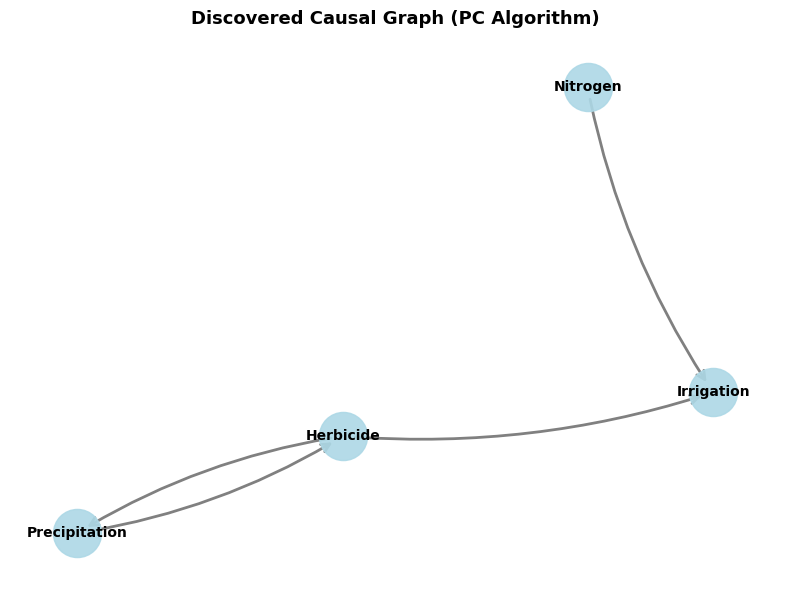

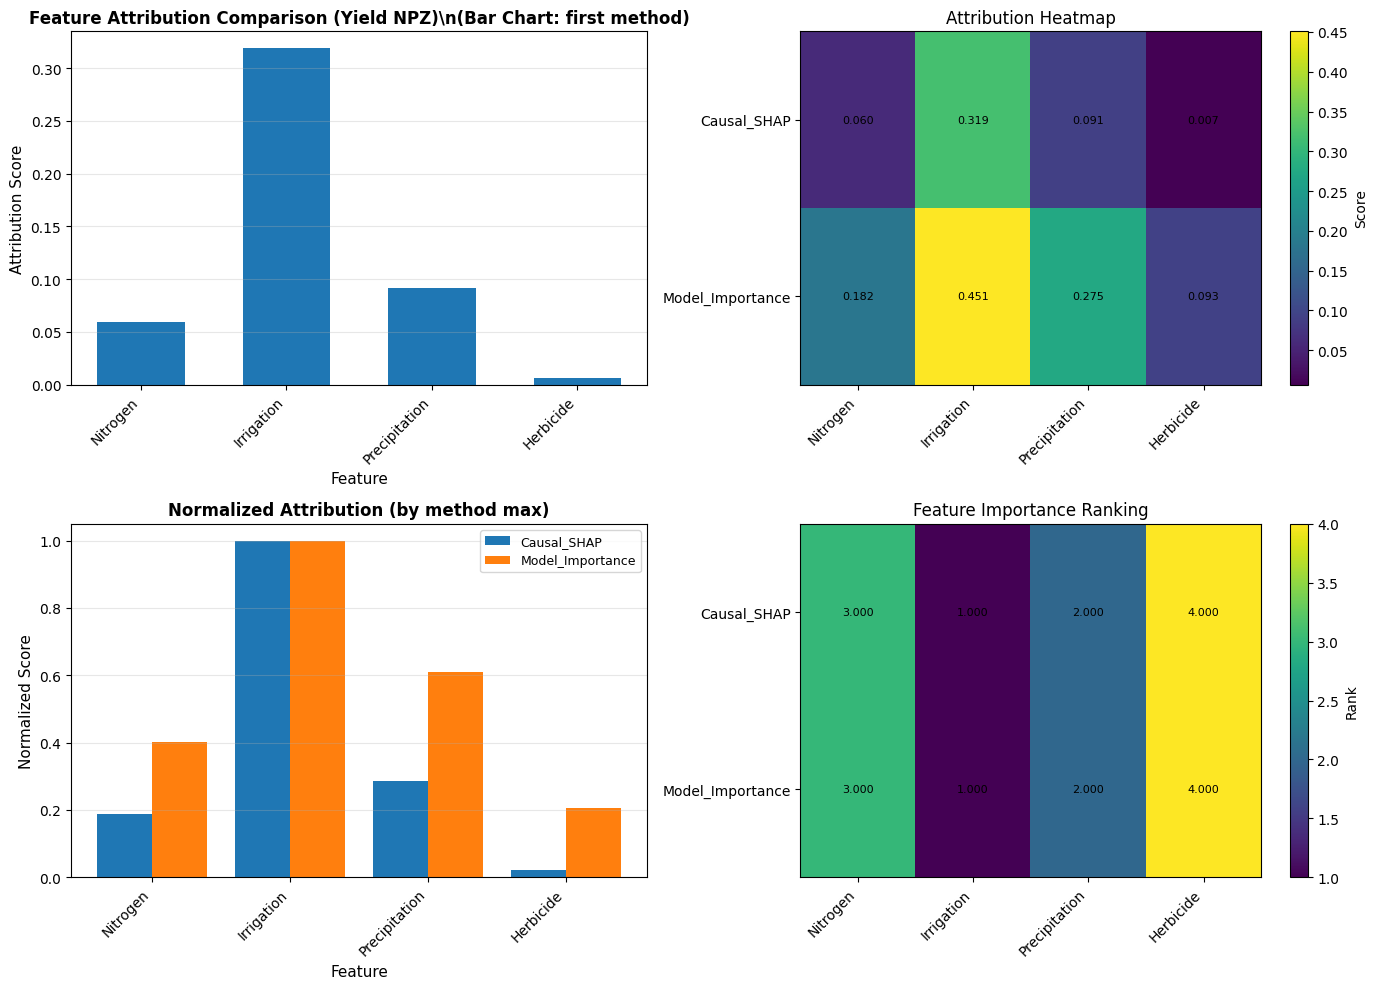

In [3]:
"""
CAUSAL SHAP on yield_preprocessed.npz
- Works with keys: X_train, X_test, y_train, y_test, feature_names
- Implements PC-based causal discovery, IDA-style causal effects, and Causal SHAP
- Saves outputs: causal graph PNG, comparison PNG, and CSV of attributions
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from typing import Dict, List, Tuple, Set
warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, accuracy_score
import networkx as nx

try:
    from xgboost import XGBClassifier
    HAVE_XGB = True
except:
    HAVE_XGB = False

from causallearn.search.ConstraintBased.PC import pc

# Configuration
CONFIG = {
    'DATA_PATH': '../../datasets/yield_preprocessed.npz',
    'ALPHA_PC': 0.3,
    'MAX_PERM': 200,
    'M_RESAMPLES': 64,
    'GLOBAL_K': 30,
    'RANDOM_SEED': 42,
    'N_DAGS': 5  # Sample multiple DAGs from CPDAG
}

np.random.seed(CONFIG['RANDOM_SEED'])
rng = np.random.default_rng(CONFIG['RANDOM_SEED'])


# 1. Causal Discovery & Structure Learning

class CausalStructure:
    """Handles causal discovery and DAG sampling from CPDAG"""

    def __init__(self, alpha=0.05):
        self.alpha = alpha
        self.cpdag = None
        self.feature_names = None
        self.dags = []

    def discover(self, X: pd.DataFrame):
        """Run PC algorithm on features"""
        self.feature_names = list(X.columns)
        print(f"Running PC algorithm on {len(self.feature_names)} features...")

        pc_res = pc(X.values, alpha=self.alpha, show_progress=False)
        self.cpdag = pc_res.G.graph

        print(f"Causal discovery complete")
        return self

    def get_skeleton(self) -> nx.DiGraph:
        """Convert CPDAG to networkx DiGraph"""
        G = nx.DiGraph()
        G.add_nodes_from(self.feature_names)

        n = len(self.feature_names)
        for i in range(n):
            for j in range(n):
                if i == j:
                    continue
                # Directed edge i->j
                if self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                    G.add_edge(self.feature_names[i], self.feature_names[j])
                # Undirected edge: add both directions
                elif self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1:
                    if i < j:  # Avoid double-adding
                        G.add_edge(self.feature_names[i], self.feature_names[j])
                        G.add_edge(self.feature_names[j], self.feature_names[i])

        return G

    def sample_dags(self, n_samples=5) -> List[nx.DiGraph]:
        """
        Sample multiple DAG orientations from CPDAG
        For undirected edges, randomly orient them
        """
        base_G = self.get_skeleton()
        dags = []

        # Find undirected edges
        undirected = []
        for i, u in enumerate(self.feature_names):
            for j, v in enumerate(self.feature_names):
                if i < j and self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1:
                    undirected.append((u, v))

        if len(undirected) == 0:
            # CPDAG is already fully directed
            print(f"  CPDAG is fully directed ({base_G.number_of_edges()} edges)")
            return [base_G]

        print(f"  Found {len(undirected)} undirected edges, sampling orientations...")

        # Sample orientations
        for _ in range(n_samples):
            G = nx.DiGraph()
            G.add_nodes_from(self.feature_names)

            # Add directed edges from CPDAG
            for i, u in enumerate(self.feature_names):
                for j, v in enumerate(self.feature_names):
                    if self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                        G.add_edge(u, v)

            # Randomly orient undirected edges (ensuring acyclicity)
            for u, v in undirected:
                if rng.random() < 0.5:
                    G.add_edge(u, v)
                else:
                    G.add_edge(v, u)

                # Check for cycles and reverse if needed
                if not nx.is_directed_acyclic_graph(G):
                    G.remove_edge(u, v) if G.has_edge(u, v) else G.remove_edge(v, u)
                    G.add_edge(v, u) if not G.has_edge(v, u) else G.add_edge(u, v)

            dags.append(G)

        self.dags = dags
        return dags


# 2. Causal Mechanism Learning

class LinearMechanisms:
    """Learn linear structural equation models"""

    def __init__(self, dag: nx.DiGraph, feature_names: List[str]):
        self.dag = dag
        self.feature_names = feature_names
        self.mechanisms = {}
        self.topo_order = None

    def fit(self, X: pd.DataFrame):
        """Fit linear mechanisms for each variable"""
        # Get topological order
        try:
            self.topo_order = list(nx.topological_sort(self.dag))
        except:
            # Fallback if cycles exist
            self.topo_order = self._safe_topo_order()

        for var in self.feature_names:
            parents = list(self.dag.predecessors(var))

            if not parents:
                # No parents: use marginal distribution
                self.mechanisms[var] = {
                    'parents': [],
                    'intercept': float(X[var].mean()),
                    'coef': None,
                    'sigma': float(X[var].std())
                }
            else:
                # Regress on parents
                lr = LinearRegression()
                lr.fit(X[parents].values, X[var].values)

                pred = lr.predict(X[parents].values)
                resid = X[var].values - pred

                self.mechanisms[var] = {
                    'parents': parents,
                    'intercept': float(lr.intercept_),
                    'coef': lr.coef_.astype(float),
                    'sigma': float(np.std(resid))
                }

        return self

    def _safe_topo_order(self) -> List[str]:
        """Fallback topological sort"""
        ordered = []
        remaining = set(self.feature_names)

        while remaining:
            # Find nodes with no remaining parents
            ready = [n for n in remaining
                    if all(p in ordered or p not in remaining
                           for p in self.dag.predecessors(n))]

            if not ready:
                # Force one with fewest remaining parents
                ready = [min(remaining,
                           key=lambda n: len([p for p in self.dag.predecessors(n)
                                            if p in remaining]))]

            for n in ready:
                ordered.append(n)
                remaining.remove(n)

        return ordered

    def sample_intervention(self, S: Set[str], x_obs: pd.Series, rng) -> Dict:
        """
        Sample from interventional distribution do(X_S = x_S)
        """
        x_new = {}

        for var in self.topo_order:
            if var in S:
                x_new[var] = float(x_obs[var])
            else:
                # Sample from mechanism
                mech = self.mechanisms[var]

                if not mech['parents']:
                    # No parents: sample from marginal
                    mu, sigma = mech['intercept'], mech['sigma']
                    if sigma < 1e-6:
                        x_new[var] = mu
                    else:
                        x_new[var] = float(rng.normal(mu, sigma))
                else:
                    # Sample from conditional
                    parent_vals = np.array([x_new.get(p, x_obs[p])
                                           for p in mech['parents']])

                    mu = mech['intercept'] + parent_vals @ mech['coef']
                    sigma = mech['sigma']
                    if sigma < 1e-6:
                        x_new[var] = mu
                    else:
                        x_new[var] = float(rng.normal(mu, sigma))

        return x_new


# 3. Causal Effect Estimation (IDA-style)

class CausalEffects:
    """Estimate total causal effects using path analysis"""

    def __init__(self, dags: List[nx.DiGraph], feature_names: List[str]):
        self.dags = dags
        self.feature_names = feature_names
        self.effects = {}

    def compute_effects(self, X: pd.DataFrame, y: pd.Series) -> Dict[str, float]:
        """
        Compute total causal effects for each feature on target
        Average over multiple DAG samples (IDA-style)
        """
        print("Computing causal effects (IDA-style)...")

        # Build augmented graphs with target
        aug_graphs = []

        for dag in self.dags:
            G = dag.copy()
            G.add_node('Y')

            # Add edges from features to Y with estimated weights
            for feat in self.feature_names:
                # Conditional regression: feat -> Y | other features
                other_feats = [f for f in self.feature_names if f != feat]
                if other_feats:
                    X_cond = np.column_stack([X[other_feats].values, X[feat].values])
                else:
                    X_cond = X[[feat]].values

                lr = LinearRegression()
                lr.fit(X_cond, y.values)
                weight = abs(lr.coef_[-1])

                if weight > 1e-6:
                    G.add_edge(feat, 'Y', weight=weight)

            # Add edge weights for feature->feature edges
            for u, v in dag.edges():
                parents = [p for p in dag.predecessors(v) if p != u]
                if parents:
                    X_reg = np.column_stack([X[parents].values, X[u].values])
                else:
                    X_reg = X[[u]].values

                lr = LinearRegression()
                lr.fit(X_reg, X[v].values)
                weight = abs(lr.coef_[-1])
                G[u][v]['weight'] = weight

            aug_graphs.append(G)

        # Compute total effects (average over DAGs)
        total_effects = {feat: [] for feat in self.feature_names}

        for G in aug_graphs:
            for feat in self.feature_names:
                effect = 0.0

                # Sum over all paths feat -> Y
                try:
                    for path in nx.all_simple_paths(G, feat, 'Y', cutoff=10):
                        path_effect = 1.0
                        for i in range(len(path) - 1):
                            edge_data = G.get_edge_data(path[i], path[i+1])
                            if edge_data and 'weight' in edge_data:
                                path_effect *= edge_data['weight']
                        effect += path_effect
                except:
                    pass

                total_effects[feat].append(effect)

        # Average across DAGs
        self.effects = {feat: np.mean(effects)
                       for feat, effects in total_effects.items()}

        print(f"Causal effects computed (averaged over {len(self.dags)} DAGs)")
        return self.effects

    def get_gamma_weights(self) -> Dict[str, float]:
        """Compute gamma weights (normalized absolute effects)"""
        abs_effects = {k: abs(v) for k, v in self.effects.items()}
        total = sum(abs_effects.values()) + 1e-12

        return {k: v / total for k, v in abs_effects.items()}


# 4. Causal SHAP Implementation

class CausalSHAP:
    """Main Causal SHAP implementation"""

    def __init__(self, model, causal_structure: CausalStructure,
                 X_train: pd.DataFrame, y_train: pd.Series):
        self.model = model
        self.structure = causal_structure
        self.X_train = X_train
        self.y_train = y_train
        self.feature_names = list(X_train.columns)

        print("\\nLearning causal mechanisms...")
        # Learn mechanisms and effects
        self.dags = causal_structure.sample_dags(n_samples=CONFIG['N_DAGS'])
        self.mechanisms_list = [LinearMechanisms(dag, self.feature_names).fit(X_train)
                               for dag in self.dags]

        # Compute causal effects
        self.causal_effects = CausalEffects(self.dags, self.feature_names)
        self.causal_effects.compute_effects(X_train, y_train)
        self.gamma = self.causal_effects.get_gamma_weights()

        print(f"Learned {len(self.dags)} DAG orientations")

    def _causal_value_function(self, S: Set[str], x: pd.Series,
                               pred_class: int, M: int) -> float:
        """
        v_c(S) = E[f(X) | do(X_S = x_S)]
        Average over DAG samples and Monte Carlo samples
        """
        total = 0.0
        samples_per_dag = max(1, M // len(self.mechanisms_list))

        for mechanisms in self.mechanisms_list:
            for _ in range(samples_per_dag):
                x_sample = mechanisms.sample_intervention(S, x, rng)
                X_mat = pd.DataFrame([x_sample], columns=self.feature_names)

                prob = self.model.predict_proba(X_mat.values)[0][pred_class]
                total += prob

        actual_samples = samples_per_dag * len(self.mechanisms_list)
        return total / actual_samples

    def explain_instance(self, x: pd.Series, n_perms: int = None,
                        m_samples: int = None) -> pd.Series:
        """
        Compute Causal SHAP values for a single instance
        """
        if n_perms is None:
            n_perms = CONFIG['MAX_PERM']
        if m_samples is None:
            m_samples = CONFIG['M_RESAMPLES']

        # Get predicted class
        probs = self.model.predict_proba(pd.DataFrame([x],
                                         columns=self.feature_names).values)[0]
        pred_class = int(np.argmax(probs))

        # Permutation-based estimation
        phi = np.zeros(len(self.feature_names))

        for _ in range(n_perms):
            perm = rng.permutation(self.feature_names)
            S = set()
            v_prev = self._causal_value_function(S, x, pred_class, m_samples)

            for feat in perm:
                S_next = S | {feat}
                v_curr = self._causal_value_function(S_next, x, pred_class, m_samples)

                delta = v_curr - v_prev
                contrib = self.gamma[feat] * delta  # Causal weighting

                phi[self.feature_names.index(feat)] += contrib
                v_prev = v_curr
                S = S_next

        phi /= n_perms

        # Normalize for local accuracy
        f_x = probs[pred_class]
        v_empty = self._causal_value_function(set(), x, pred_class, m_samples)

        sum_phi = np.sum(phi)
        if abs(sum_phi) > 1e-12:
            phi = phi * ((f_x - v_empty) / sum_phi)

        return pd.Series(phi, index=self.feature_names, name='Causal_SHAP')

    def explain_global(self, X_test: pd.DataFrame, n_samples: int = None) -> pd.Series:
        """Global explanation: average over test instances"""
        if n_samples is None:
            n_samples = CONFIG['GLOBAL_K']

        n_samples = min(n_samples, len(X_test))
        indices = rng.choice(len(X_test), size=n_samples, replace=False)

        print(f"\\nComputing global Causal SHAP (averaging over {n_samples} instances)...")
        explanations = []
        for i, idx in enumerate(indices):
            if (i + 1) % 5 == 0:
                print(f"  Progress: {i+1}/{n_samples}")
            exp = self.explain_instance(X_test.iloc[idx],
                                       n_perms=max(10, CONFIG['MAX_PERM']//4))
            explanations.append(exp)

        print("ok Global Causal SHAP computed")
        return pd.concat(explanations, axis=1).mean(axis=1).rename('Causal_SHAP_Global')


# 5. Baseline Methods for Comparison (optional SHAP if installed)

def compute_baseline_shap(model, X_train, X_test):
    """Compute Kernel SHAP values if shap is installed"""
    try:
        import shap
        print("\\nComputing KERNEL SHAP baseline...")
        bg_size = min(100, len(X_train))
        bg = shap.kmeans(X_train.values, bg_size)
        explainer = shap.KernelExplainer(lambda x: model.predict_proba(x), bg)
        shap_values = explainer.shap_values(X_test.values, nsamples=100)

        # Average absolute values across classes
        if isinstance(shap_values, list):
            global_imp = np.mean([np.abs(sv).mean(axis=0) for sv in shap_values], axis=0)
        else:
            global_imp = np.abs(shap_values).mean(axis=0)
        print("ok KERNEL SHAP computed")
        return pd.Series(global_imp, index=X_test.columns, name='SHAP_kernel')
    except Exception as e:
        print(f"Warning: SHAP computation skipped/failed: {e}")
        return None


def compute_feature_importance(model, feature_names):
    """Compute model's native feature importance"""
    if hasattr(model, 'feature_importances_'):
        imp = model.feature_importances_
        return pd.Series(imp, index=feature_names, name='Model_Importance')
    return None


# 6. Visualization (pure matplotlib, no seaborn)

def annotate_heatmap(ax, data: pd.DataFrame, title: str, cbar_label: str):
    im = ax.imshow(data.values, aspect='auto')
    ax.set_xticks(np.arange(data.shape[1]))
    ax.set_yticks(np.arange(data.shape[0]))
    ax.set_xticklabels(data.columns, rotation=45, ha='right')
    ax.set_yticklabels(data.index)
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            ax.text(j, i, f"{data.values[i, j]:.3f}", ha='center', va='center', fontsize=8)
    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label(cbar_label)
    ax.set_title(title)


def plot_comparison(df_comp: pd.DataFrame, title: str = "Feature Attribution Comparison"):
    """Visualize comparison of different methods (matplotlib only)"""
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    # Bar plot
    axes[0, 0].bar(np.arange(df_comp.shape[0]), df_comp.iloc[:, 0], width=0.6)
    axes[0, 0].set_title(f'{title}\\n(Bar Chart: first method)', fontsize=12, fontweight='bold')
    axes[0, 0].set_ylabel('Attribution Score', fontsize=11)
    axes[0, 0].set_xlabel('Feature', fontsize=11)
    axes[0, 0].set_xticks(np.arange(df_comp.shape[0]))
    axes[0, 0].set_xticklabels(df_comp.index, rotation=45, ha='right')
    axes[0, 0].grid(axis='y', alpha=0.3)

    # Heatmap
    annotate_heatmap(axes[0, 1], df_comp.T, 'Attribution Heatmap', 'Score')

    # Normalized comparison
    df_norm = df_comp.div(df_comp.abs().max(axis=0), axis=1)
    for i, col in enumerate(df_norm.columns):
        axes[1, 0].bar(np.arange(df_norm.shape[0]) + (i-0.5)*(0.8/len(df_norm.columns)), df_norm[col], width=0.8/len(df_norm.columns), label=col)
    axes[1, 0].set_title('Normalized Attribution (by method max)', fontsize=12, fontweight='bold')
    axes[1, 0].set_ylabel('Normalized Score', fontsize=11)
    axes[1, 0].set_xlabel('Feature', fontsize=11)
    axes[1, 0].set_xticks(np.arange(df_norm.shape[0]))
    axes[1, 0].set_xticklabels(df_norm.index, rotation=45, ha='right')
    axes[1, 0].legend(loc='best', fontsize=9)
    axes[1, 0].grid(axis='y', alpha=0.3)

    # Rank comparison heatmap
    ranks = df_comp.rank(ascending=False)
    annotate_heatmap(axes[1, 1], ranks.T, 'Feature Importance Ranking', 'Rank')

    fig.tight_layout()
    return fig


def plot_causal_graph(G: nx.DiGraph, title: str = "Discovered Causal Graph"):
    """Visualize the causal graph"""
    plt.figure(figsize=(8, 6))
    pos = nx.spring_layout(G, seed=CONFIG['RANDOM_SEED'], k=1.0, iterations=200)

    nx.draw_networkx_nodes(G, pos, node_color='lightblue', node_size=1200, alpha=0.9)
    nx.draw_networkx_edges(G, pos, edge_color='gray', arrows=True, arrowsize=15,
                           arrowstyle='->', width=2, connectionstyle='arc3,rad=0.1')
    nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')

    plt.title(title, fontsize=13, fontweight='bold', pad=12)
    plt.axis('off')
    plt.tight_layout()
    return plt.gcf()


# 7. Main Execution

def main():
    """Run complete Causal SHAP analysis on NPZ dataset"""

    print("\\n" + "="*70)
    print("CAUSAL SHAP on NPZ Dataset")
    print("="*70 + "\\n")

    # Load data
    print("Loading NPZ dataset...")
    try:
        data = np.load(CONFIG['DATA_PATH'], allow_pickle=True)
        keys = list(data.keys())
        print(f"NPZ loaded with keys: {keys}")
    except FileNotFoundError:
        print(f"ERROR: Could not find '{CONFIG['DATA_PATH']}'")
        print("Please ensure the file is in the current directory.")
        return

    required_keys = {'X_train', 'X_test', 'y_train', 'y_test', 'feature_names'}
    if not required_keys.issubset(set(keys)):
        print("ERROR: NPZ must contain X_train, X_test, y_train, y_test, feature_names.")
        return

    # Extract
    X_train = pd.DataFrame(data['X_train'], columns=list(data['feature_names']))
    X_test  = pd.DataFrame(data['X_test'],  columns=list(data['feature_names']))
    y_train = pd.Series(data['y_train'].astype(int))
    y_test  = pd.Series(data['y_test'].astype(int))

    print(f"Shapes: X_train={X_train.shape}, X_test={X_test.shape}, y_train={y_train.shape}, y_test={y_test.shape}")
    print(f"Features: {', '.join(X_train.columns)}")
    n_classes = len(np.unique(y_train))
    print(f"Target classes: {n_classes}")

    # Scale features using training stats
    scaler = StandardScaler()
    X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
    X_test_scaled  = pd.DataFrame(scaler.transform(X_test),  columns=X_test.columns)

    # Train model
    print("\\n" + "="*70)
    print("Training Model")
    print("="*70)

    if HAVE_XGB:
        model = XGBClassifier(
            n_estimators=160,
            max_depth=5,
            learning_rate=0.08,
            subsample=0.9,
            colsample_bytree=0.9,
            random_state=CONFIG['RANDOM_SEED'],
            verbosity=0,
            objective="multi:softprob",
            num_class=n_classes,
        )
        print("Using XGBoost classifier")
    else:
        model = RandomForestClassifier(
            n_estimators=160,
            max_depth=6,
            random_state=CONFIG['RANDOM_SEED']
        )
        print("Using Random Forest classifier")

    model.fit(X_train_scaled.values, y_train.values)

    y_pred = model.predict(X_test_scaled.values)
    f1 = f1_score(y_test, y_pred, average='macro')
    acc = accuracy_score(y_test, y_pred)

    print(f"Model trained")
    print(f"  Test Accuracy: {acc:.4f}")
    print(f"  Test Macro F1: {f1:.4f}")

    # Causal Discovery
    print("\\n" + "="*70)
    print("Step 1: Causal Discovery (PC Algorithm)")
    print("="*70)

    causal_structure = CausalStructure(alpha=CONFIG['ALPHA_PC'])
    causal_structure.discover(X_train_scaled)

    # Visualize discovered graph
    G = causal_structure.get_skeleton()
    print(f"\\nDiscovered graph: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")

    fig_graph = plot_causal_graph(G, "Discovered Causal Graph (PC Algorithm)")
    fig_graph.savefig('causal_graph_yield.png', dpi=150, bbox_inches='tight')
    print("ok Causal graph saved to 'causal_graph_yield.png'")

    # Causal SHAP
    print("\\n" + "="*70)
    print("Step 2: Computing Causal SHAP")
    print("="*70)

    causal_shap = CausalSHAP(model, causal_structure, X_train_scaled, y_train)

    # Show causal effects
    print("\\nTotal Causal Effects (W_i):")
    print("-" * 40)
    for feat in X_train.columns:
        effect = causal_shap.causal_effects.effects[feat]
        gamma = causal_shap.gamma[feat]
        print(f"  {feat:15s}: W={effect:8.4f}  γ={gamma:.4f}")

    # Global explanation
    global_causal_shap = causal_shap.explain_global(X_test_scaled, n_samples=CONFIG['GLOBAL_K'])

    # Baseline methods (optional)
    print("\\n" + "="*70)
    print("Step 3: Computing Baseline Methods")
    print("="*70)
    baseline_shap = compute_baseline_shap(model, X_train_scaled, X_test_scaled)
    model_imp = compute_feature_importance(model, list(X_train.columns))

    # Comparison
    print("\\n" + "="*70)
    print("Step 4: Results Comparison")
    print("="*70)

    attributions = {
        'Causal_SHAP': global_causal_shap,
    }

    if baseline_shap is not None:
        attributions['Kernel_SHAP'] = baseline_shap

    if model_imp is not None:
        attributions['Model_Importance'] = model_imp

    df_comparison = pd.DataFrame(attributions)
    df_comparison.to_csv('attribution_scores_yield.csv', index=True)

    print("\\n" + "="*70)
    print("Attribution Scores:")
    print("="*70)
    print(df_comparison.round(6).to_string())
    print("\\nSaved CSV -> attribution_scores_yield.csv")

    # Correlation analysis
    if len(attributions) > 1:
        print("\\n" + "="*70)
        print("Correlation between methods:")
        print("="*70)
        corr_matrix = df_comparison.corr()
        print(corr_matrix.round(4).to_string())

    # Visualization
    fig = plot_comparison(df_comparison,
                         title="Feature Attribution Comparison (Yield NPZ)")
    fig.savefig('attribution_comparison_yield.png', dpi=150, bbox_inches='tight')
    print("\\nok Comparison plot saved to 'attribution_comparison_yield.png'")

    try:
        plt.show()
    except Exception:
        pass

if __name__ == "__main__":
    main()

\n======================================================================
CAUSAL SHAP on NPZ Dataset
======================================================================\n
Loading NPZ dataset...
✓ NPZ loaded with keys: ['X_train', 'X_test', 'y_train', 'y_test', 'feature_names']
Shapes: X_train=(800, 4), X_test=(200, 4), y_train=(800,), y_test=(200,)
Features: Nitrogen, Irrigation, Precipitation, Herbicide
Target classes: 3
\n======================================================================
Training Model
Using XGBoost classifier
✓ Model trained
  Test Accuracy: 0.8050
  Test Macro F1: 0.8081
\n======================================================================
Step 1: Causal Discovery (PC Algorithm)
Running PC algorithm on 4 features...
✓ Causal discovery complete
\nDiscovered graph: 4 nodes, 4 edges
✓ Causal graph saved to 'causal_graph_yield.png'
\n======================================================================
Step 2: Computing Causal SHAP
\nLearning causal mechanism

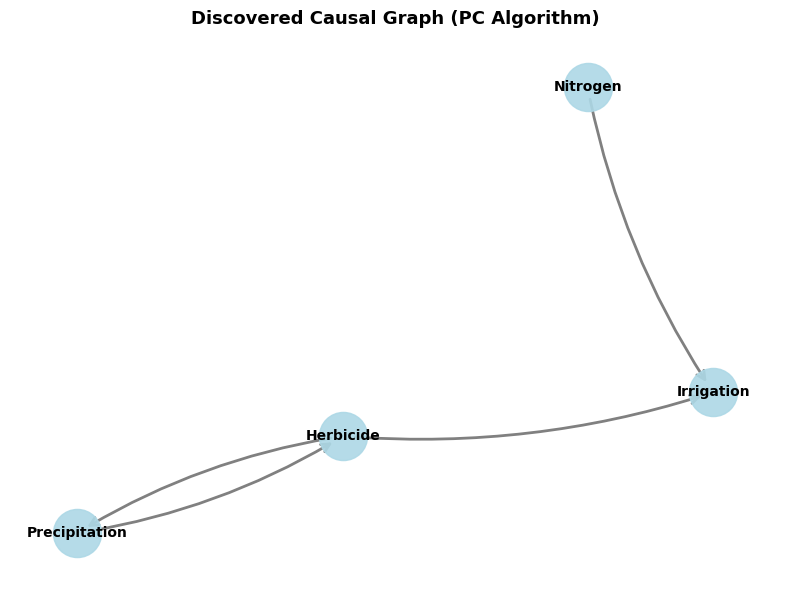

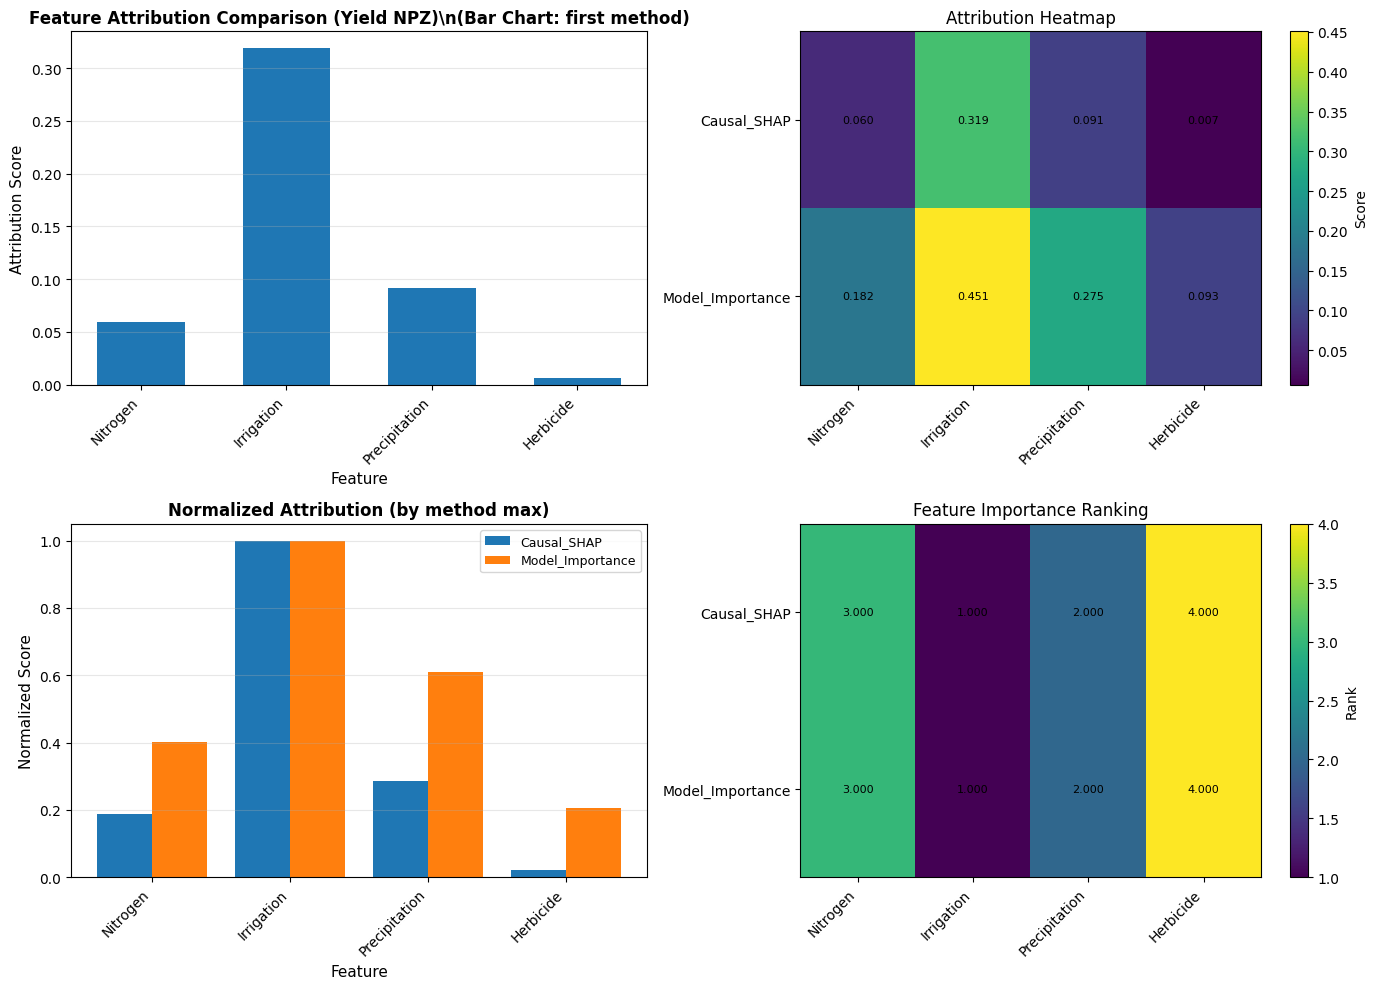

In [4]:
"""
CAUSAL SHAP on yield_preprocessed.npz
- Works with keys: X_train, X_test, y_train, y_test, feature_names
- Implements PC-based causal discovery, IDA-style causal effects, and Causal SHAP
- Saves outputs: causal graph PNG, comparison PNG, and CSV of attributions
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from typing import Dict, List, Tuple, Set
warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, accuracy_score
import networkx as nx

try:
    from xgboost import XGBClassifier
    HAVE_XGB = True
except:
    HAVE_XGB = False

from causallearn.search.ConstraintBased.PC import pc

# Configuration
CONFIG = {
    'DATA_PATH': '../../datasets/yield_preprocessed.npz',
    'ALPHA_PC': 0.4,
    'MAX_PERM': 200,
    'M_RESAMPLES': 64,
    'GLOBAL_K': 30,
    'RANDOM_SEED': 42,
    'N_DAGS': 5  # Sample multiple DAGs from CPDAG
}

np.random.seed(CONFIG['RANDOM_SEED'])
rng = np.random.default_rng(CONFIG['RANDOM_SEED'])


# 1. Causal Discovery & Structure Learning

class CausalStructure:
    """Handles causal discovery and DAG sampling from CPDAG"""

    def __init__(self, alpha=0.05):
        self.alpha = alpha
        self.cpdag = None
        self.feature_names = None
        self.dags = []

    def discover(self, X: pd.DataFrame):
        """Run PC algorithm on features"""
        self.feature_names = list(X.columns)
        print(f"Running PC algorithm on {len(self.feature_names)} features...")

        pc_res = pc(X.values, alpha=self.alpha, show_progress=False)
        self.cpdag = pc_res.G.graph

        print(f"Causal discovery complete")
        return self

    def get_skeleton(self) -> nx.DiGraph:
        """Convert CPDAG to networkx DiGraph"""
        G = nx.DiGraph()
        G.add_nodes_from(self.feature_names)

        n = len(self.feature_names)
        for i in range(n):
            for j in range(n):
                if i == j:
                    continue
                # Directed edge i->j
                if self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                    G.add_edge(self.feature_names[i], self.feature_names[j])
                # Undirected edge: add both directions
                elif self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1:
                    if i < j:  # Avoid double-adding
                        G.add_edge(self.feature_names[i], self.feature_names[j])
                        G.add_edge(self.feature_names[j], self.feature_names[i])

        return G

    def sample_dags(self, n_samples=5) -> List[nx.DiGraph]:
        """
        Sample multiple DAG orientations from CPDAG
        For undirected edges, randomly orient them
        """
        base_G = self.get_skeleton()
        dags = []

        # Find undirected edges
        undirected = []
        for i, u in enumerate(self.feature_names):
            for j, v in enumerate(self.feature_names):
                if i < j and self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1:
                    undirected.append((u, v))

        if len(undirected) == 0:
            # CPDAG is already fully directed
            print(f"  CPDAG is fully directed ({base_G.number_of_edges()} edges)")
            return [base_G]

        print(f"  Found {len(undirected)} undirected edges, sampling orientations...")

        # Sample orientations
        for _ in range(n_samples):
            G = nx.DiGraph()
            G.add_nodes_from(self.feature_names)

            # Add directed edges from CPDAG
            for i, u in enumerate(self.feature_names):
                for j, v in enumerate(self.feature_names):
                    if self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                        G.add_edge(u, v)

            # Randomly orient undirected edges (ensuring acyclicity)
            for u, v in undirected:
                if rng.random() < 0.5:
                    G.add_edge(u, v)
                else:
                    G.add_edge(v, u)

                # Check for cycles and reverse if needed
                if not nx.is_directed_acyclic_graph(G):
                    G.remove_edge(u, v) if G.has_edge(u, v) else G.remove_edge(v, u)
                    G.add_edge(v, u) if not G.has_edge(v, u) else G.add_edge(u, v)

            dags.append(G)

        self.dags = dags
        return dags


# 2. Causal Mechanism Learning

class LinearMechanisms:
    """Learn linear structural equation models"""

    def __init__(self, dag: nx.DiGraph, feature_names: List[str]):
        self.dag = dag
        self.feature_names = feature_names
        self.mechanisms = {}
        self.topo_order = None

    def fit(self, X: pd.DataFrame):
        """Fit linear mechanisms for each variable"""
        # Get topological order
        try:
            self.topo_order = list(nx.topological_sort(self.dag))
        except:
            # Fallback if cycles exist
            self.topo_order = self._safe_topo_order()

        for var in self.feature_names:
            parents = list(self.dag.predecessors(var))

            if not parents:
                # No parents: use marginal distribution
                self.mechanisms[var] = {
                    'parents': [],
                    'intercept': float(X[var].mean()),
                    'coef': None,
                    'sigma': float(X[var].std())
                }
            else:
                # Regress on parents
                lr = LinearRegression()
                lr.fit(X[parents].values, X[var].values)

                pred = lr.predict(X[parents].values)
                resid = X[var].values - pred

                self.mechanisms[var] = {
                    'parents': parents,
                    'intercept': float(lr.intercept_),
                    'coef': lr.coef_.astype(float),
                    'sigma': float(np.std(resid))
                }

        return self

    def _safe_topo_order(self) -> List[str]:
        """Fallback topological sort"""
        ordered = []
        remaining = set(self.feature_names)

        while remaining:
            # Find nodes with no remaining parents
            ready = [n for n in remaining
                    if all(p in ordered or p not in remaining
                           for p in self.dag.predecessors(n))]

            if not ready:
                # Force one with fewest remaining parents
                ready = [min(remaining,
                           key=lambda n: len([p for p in self.dag.predecessors(n)
                                            if p in remaining]))]

            for n in ready:
                ordered.append(n)
                remaining.remove(n)

        return ordered

    def sample_intervention(self, S: Set[str], x_obs: pd.Series, rng) -> Dict:
        """
        Sample from interventional distribution do(X_S = x_S)
        """
        x_new = {}

        for var in self.topo_order:
            if var in S:
                x_new[var] = float(x_obs[var])
            else:
                # Sample from mechanism
                mech = self.mechanisms[var]

                if not mech['parents']:
                    # No parents: sample from marginal
                    mu, sigma = mech['intercept'], mech['sigma']
                    if sigma < 1e-6:
                        x_new[var] = mu
                    else:
                        x_new[var] = float(rng.normal(mu, sigma))
                else:
                    # Sample from conditional
                    parent_vals = np.array([x_new.get(p, x_obs[p])
                                           for p in mech['parents']])

                    mu = mech['intercept'] + parent_vals @ mech['coef']
                    sigma = mech['sigma']
                    if sigma < 1e-6:
                        x_new[var] = mu
                    else:
                        x_new[var] = float(rng.normal(mu, sigma))

        return x_new


# 3. Causal Effect Estimation (IDA-style)

class CausalEffects:
    """Estimate total causal effects using path analysis"""

    def __init__(self, dags: List[nx.DiGraph], feature_names: List[str]):
        self.dags = dags
        self.feature_names = feature_names
        self.effects = {}

    def compute_effects(self, X: pd.DataFrame, y: pd.Series) -> Dict[str, float]:
        """
        Compute total causal effects for each feature on target
        Average over multiple DAG samples (IDA-style)
        """
        print("Computing causal effects (IDA-style)...")

        # Build augmented graphs with target
        aug_graphs = []

        for dag in self.dags:
            G = dag.copy()
            G.add_node('Y')

            # Add edges from features to Y with estimated weights
            for feat in self.feature_names:
                # Conditional regression: feat -> Y | other features
                other_feats = [f for f in self.feature_names if f != feat]
                if other_feats:
                    X_cond = np.column_stack([X[other_feats].values, X[feat].values])
                else:
                    X_cond = X[[feat]].values

                lr = LinearRegression()
                lr.fit(X_cond, y.values)
                weight = abs(lr.coef_[-1])

                if weight > 1e-6:
                    G.add_edge(feat, 'Y', weight=weight)

            # Add edge weights for feature->feature edges
            for u, v in dag.edges():
                parents = [p for p in dag.predecessors(v) if p != u]
                if parents:
                    X_reg = np.column_stack([X[parents].values, X[u].values])
                else:
                    X_reg = X[[u]].values

                lr = LinearRegression()
                lr.fit(X_reg, X[v].values)
                weight = abs(lr.coef_[-1])
                G[u][v]['weight'] = weight

            aug_graphs.append(G)

        # Compute total effects (average over DAGs)
        total_effects = {feat: [] for feat in self.feature_names}

        for G in aug_graphs:
            for feat in self.feature_names:
                effect = 0.0

                # Sum over all paths feat -> Y
                try:
                    for path in nx.all_simple_paths(G, feat, 'Y', cutoff=10):
                        path_effect = 1.0
                        for i in range(len(path) - 1):
                            edge_data = G.get_edge_data(path[i], path[i+1])
                            if edge_data and 'weight' in edge_data:
                                path_effect *= edge_data['weight']
                        effect += path_effect
                except:
                    pass

                total_effects[feat].append(effect)

        # Average across DAGs
        self.effects = {feat: np.mean(effects)
                       for feat, effects in total_effects.items()}

        print(f"Causal effects computed (averaged over {len(self.dags)} DAGs)")
        return self.effects

    def get_gamma_weights(self) -> Dict[str, float]:
        """Compute gamma weights (normalized absolute effects)"""
        abs_effects = {k: abs(v) for k, v in self.effects.items()}
        total = sum(abs_effects.values()) + 1e-12

        return {k: v / total for k, v in abs_effects.items()}


# 4. Causal SHAP Implementation

class CausalSHAP:
    """Main Causal SHAP implementation"""

    def __init__(self, model, causal_structure: CausalStructure,
                 X_train: pd.DataFrame, y_train: pd.Series):
        self.model = model
        self.structure = causal_structure
        self.X_train = X_train
        self.y_train = y_train
        self.feature_names = list(X_train.columns)

        print("\\nLearning causal mechanisms...")
        # Learn mechanisms and effects
        self.dags = causal_structure.sample_dags(n_samples=CONFIG['N_DAGS'])
        self.mechanisms_list = [LinearMechanisms(dag, self.feature_names).fit(X_train)
                               for dag in self.dags]

        # Compute causal effects
        self.causal_effects = CausalEffects(self.dags, self.feature_names)
        self.causal_effects.compute_effects(X_train, y_train)
        self.gamma = self.causal_effects.get_gamma_weights()

        print(f"Learned {len(self.dags)} DAG orientations")

    def _causal_value_function(self, S: Set[str], x: pd.Series,
                               pred_class: int, M: int) -> float:
        """
        v_c(S) = E[f(X) | do(X_S = x_S)]
        Average over DAG samples and Monte Carlo samples
        """
        total = 0.0
        samples_per_dag = max(1, M // len(self.mechanisms_list))

        for mechanisms in self.mechanisms_list:
            for _ in range(samples_per_dag):
                x_sample = mechanisms.sample_intervention(S, x, rng)
                X_mat = pd.DataFrame([x_sample], columns=self.feature_names)

                prob = self.model.predict_proba(X_mat.values)[0][pred_class]
                total += prob

        actual_samples = samples_per_dag * len(self.mechanisms_list)
        return total / actual_samples

    def explain_instance(self, x: pd.Series, n_perms: int = None,
                        m_samples: int = None) -> pd.Series:
        """
        Compute Causal SHAP values for a single instance
        """
        if n_perms is None:
            n_perms = CONFIG['MAX_PERM']
        if m_samples is None:
            m_samples = CONFIG['M_RESAMPLES']

        # Get predicted class
        probs = self.model.predict_proba(pd.DataFrame([x],
                                         columns=self.feature_names).values)[0]
        pred_class = int(np.argmax(probs))

        # Permutation-based estimation
        phi = np.zeros(len(self.feature_names))

        for _ in range(n_perms):
            perm = rng.permutation(self.feature_names)
            S = set()
            v_prev = self._causal_value_function(S, x, pred_class, m_samples)

            for feat in perm:
                S_next = S | {feat}
                v_curr = self._causal_value_function(S_next, x, pred_class, m_samples)

                delta = v_curr - v_prev
                contrib = self.gamma[feat] * delta  # Causal weighting

                phi[self.feature_names.index(feat)] += contrib
                v_prev = v_curr
                S = S_next

        phi /= n_perms

        # Normalize for local accuracy
        f_x = probs[pred_class]
        v_empty = self._causal_value_function(set(), x, pred_class, m_samples)

        sum_phi = np.sum(phi)
        if abs(sum_phi) > 1e-12:
            phi = phi * ((f_x - v_empty) / sum_phi)

        return pd.Series(phi, index=self.feature_names, name='Causal_SHAP')

    def explain_global(self, X_test: pd.DataFrame, n_samples: int = None) -> pd.Series:
        """Global explanation: average over test instances"""
        if n_samples is None:
            n_samples = CONFIG['GLOBAL_K']

        n_samples = min(n_samples, len(X_test))
        indices = rng.choice(len(X_test), size=n_samples, replace=False)

        print(f"\\nComputing global Causal SHAP (averaging over {n_samples} instances)...")
        explanations = []
        for i, idx in enumerate(indices):
            if (i + 1) % 5 == 0:
                print(f"  Progress: {i+1}/{n_samples}")
            exp = self.explain_instance(X_test.iloc[idx],
                                       n_perms=max(10, CONFIG['MAX_PERM']//4))
            explanations.append(exp)

        print("ok Global Causal SHAP computed")
        return pd.concat(explanations, axis=1).mean(axis=1).rename('Causal_SHAP_Global')


# 5. Baseline Methods for Comparison (optional SHAP if installed)

def compute_baseline_shap(model, X_train, X_test):
    """Compute Kernel SHAP values if shap is installed"""
    try:
        import shap
        print("\\nComputing KERNEL SHAP baseline...")
        bg_size = min(100, len(X_train))
        bg = shap.kmeans(X_train.values, bg_size)
        explainer = shap.KernelExplainer(lambda x: model.predict_proba(x), bg)
        shap_values = explainer.shap_values(X_test.values, nsamples=100)

        # Average absolute values across classes
        if isinstance(shap_values, list):
            global_imp = np.mean([np.abs(sv).mean(axis=0) for sv in shap_values], axis=0)
        else:
            global_imp = np.abs(shap_values).mean(axis=0)
        print("ok KERNEL SHAP computed")
        return pd.Series(global_imp, index=X_test.columns, name='SHAP_kernel')
    except Exception as e:
        print(f"Warning: SHAP computation skipped/failed: {e}")
        return None


def compute_feature_importance(model, feature_names):
    """Compute model's native feature importance"""
    if hasattr(model, 'feature_importances_'):
        imp = model.feature_importances_
        return pd.Series(imp, index=feature_names, name='Model_Importance')
    return None


# 6. Visualization (pure matplotlib, no seaborn)

def annotate_heatmap(ax, data: pd.DataFrame, title: str, cbar_label: str):
    im = ax.imshow(data.values, aspect='auto')
    ax.set_xticks(np.arange(data.shape[1]))
    ax.set_yticks(np.arange(data.shape[0]))
    ax.set_xticklabels(data.columns, rotation=45, ha='right')
    ax.set_yticklabels(data.index)
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            ax.text(j, i, f"{data.values[i, j]:.3f}", ha='center', va='center', fontsize=8)
    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label(cbar_label)
    ax.set_title(title)


def plot_comparison(df_comp: pd.DataFrame, title: str = "Feature Attribution Comparison"):
    """Visualize comparison of different methods (matplotlib only)"""
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    # Bar plot
    axes[0, 0].bar(np.arange(df_comp.shape[0]), df_comp.iloc[:, 0], width=0.6)
    axes[0, 0].set_title(f'{title}\\n(Bar Chart: first method)', fontsize=12, fontweight='bold')
    axes[0, 0].set_ylabel('Attribution Score', fontsize=11)
    axes[0, 0].set_xlabel('Feature', fontsize=11)
    axes[0, 0].set_xticks(np.arange(df_comp.shape[0]))
    axes[0, 0].set_xticklabels(df_comp.index, rotation=45, ha='right')
    axes[0, 0].grid(axis='y', alpha=0.3)

    # Heatmap
    annotate_heatmap(axes[0, 1], df_comp.T, 'Attribution Heatmap', 'Score')

    # Normalized comparison
    df_norm = df_comp.div(df_comp.abs().max(axis=0), axis=1)
    for i, col in enumerate(df_norm.columns):
        axes[1, 0].bar(np.arange(df_norm.shape[0]) + (i-0.5)*(0.8/len(df_norm.columns)), df_norm[col], width=0.8/len(df_norm.columns), label=col)
    axes[1, 0].set_title('Normalized Attribution (by method max)', fontsize=12, fontweight='bold')
    axes[1, 0].set_ylabel('Normalized Score', fontsize=11)
    axes[1, 0].set_xlabel('Feature', fontsize=11)
    axes[1, 0].set_xticks(np.arange(df_norm.shape[0]))
    axes[1, 0].set_xticklabels(df_norm.index, rotation=45, ha='right')
    axes[1, 0].legend(loc='best', fontsize=9)
    axes[1, 0].grid(axis='y', alpha=0.3)

    # Rank comparison heatmap
    ranks = df_comp.rank(ascending=False)
    annotate_heatmap(axes[1, 1], ranks.T, 'Feature Importance Ranking', 'Rank')

    fig.tight_layout()
    return fig


def plot_causal_graph(G: nx.DiGraph, title: str = "Discovered Causal Graph"):
    """Visualize the causal graph"""
    plt.figure(figsize=(8, 6))
    pos = nx.spring_layout(G, seed=CONFIG['RANDOM_SEED'], k=1.0, iterations=200)

    nx.draw_networkx_nodes(G, pos, node_color='lightblue', node_size=1200, alpha=0.9)
    nx.draw_networkx_edges(G, pos, edge_color='gray', arrows=True, arrowsize=15,
                           arrowstyle='->', width=2, connectionstyle='arc3,rad=0.1')
    nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')

    plt.title(title, fontsize=13, fontweight='bold', pad=12)
    plt.axis('off')
    plt.tight_layout()
    return plt.gcf()


# 7. Main Execution

def main():
    """Run complete Causal SHAP analysis on NPZ dataset"""

    print("\\n" + "="*70)
    print("CAUSAL SHAP on NPZ Dataset")
    print("="*70 + "\\n")

    # Load data
    print("Loading NPZ dataset...")
    try:
        data = np.load(CONFIG['DATA_PATH'], allow_pickle=True)
        keys = list(data.keys())
        print(f"NPZ loaded with keys: {keys}")
    except FileNotFoundError:
        print(f"ERROR: Could not find '{CONFIG['DATA_PATH']}'")
        print("Please ensure the file is in the current directory.")
        return

    required_keys = {'X_train', 'X_test', 'y_train', 'y_test', 'feature_names'}
    if not required_keys.issubset(set(keys)):
        print("ERROR: NPZ must contain X_train, X_test, y_train, y_test, feature_names.")
        return

    # Extract
    X_train = pd.DataFrame(data['X_train'], columns=list(data['feature_names']))
    X_test  = pd.DataFrame(data['X_test'],  columns=list(data['feature_names']))
    y_train = pd.Series(data['y_train'].astype(int))
    y_test  = pd.Series(data['y_test'].astype(int))

    print(f"Shapes: X_train={X_train.shape}, X_test={X_test.shape}, y_train={y_train.shape}, y_test={y_test.shape}")
    print(f"Features: {', '.join(X_train.columns)}")
    n_classes = len(np.unique(y_train))
    print(f"Target classes: {n_classes}")

    # Scale features using training stats
    scaler = StandardScaler()
    X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
    X_test_scaled  = pd.DataFrame(scaler.transform(X_test),  columns=X_test.columns)

    # Train model
    print("\\n" + "="*70)
    print("Training Model")
    print("="*70)

    if HAVE_XGB:
        model = XGBClassifier(
            n_estimators=160,
            max_depth=5,
            learning_rate=0.08,
            subsample=0.9,
            colsample_bytree=0.9,
            random_state=CONFIG['RANDOM_SEED'],
            verbosity=0,
            objective="multi:softprob",
            num_class=n_classes,
        )
        print("Using XGBoost classifier")
    else:
        model = RandomForestClassifier(
            n_estimators=160,
            max_depth=6,
            random_state=CONFIG['RANDOM_SEED']
        )
        print("Using Random Forest classifier")

    model.fit(X_train_scaled.values, y_train.values)

    y_pred = model.predict(X_test_scaled.values)
    f1 = f1_score(y_test, y_pred, average='macro')
    acc = accuracy_score(y_test, y_pred)

    print(f"Model trained")
    print(f"  Test Accuracy: {acc:.4f}")
    print(f"  Test Macro F1: {f1:.4f}")

    # Causal Discovery
    print("\\n" + "="*70)
    print("Step 1: Causal Discovery (PC Algorithm)")
    print("="*70)

    causal_structure = CausalStructure(alpha=CONFIG['ALPHA_PC'])
    causal_structure.discover(X_train_scaled)

    # Visualize discovered graph
    G = causal_structure.get_skeleton()
    print(f"\\nDiscovered graph: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")

    fig_graph = plot_causal_graph(G, "Discovered Causal Graph (PC Algorithm)")
    fig_graph.savefig('causal_graph_yield.png', dpi=150, bbox_inches='tight')
    print("ok Causal graph saved to 'causal_graph_yield.png'")

    # Causal SHAP
    print("\\n" + "="*70)
    print("Step 2: Computing Causal SHAP")
    print("="*70)

    causal_shap = CausalSHAP(model, causal_structure, X_train_scaled, y_train)

    # Show causal effects
    print("\\nTotal Causal Effects (W_i):")
    print("-" * 40)
    for feat in X_train.columns:
        effect = causal_shap.causal_effects.effects[feat]
        gamma = causal_shap.gamma[feat]
        print(f"  {feat:15s}: W={effect:8.4f}  γ={gamma:.4f}")

    # Global explanation
    global_causal_shap = causal_shap.explain_global(X_test_scaled, n_samples=CONFIG['GLOBAL_K'])

    # Baseline methods (optional)
    print("\\n" + "="*70)
    print("Step 3: Computing Baseline Methods")
    print("="*70)
    baseline_shap = compute_baseline_shap(model, X_train_scaled, X_test_scaled)
    model_imp = compute_feature_importance(model, list(X_train.columns))

    # Comparison
    print("\\n" + "="*70)
    print("Step 4: Results Comparison")
    print("="*70)

    attributions = {
        'Causal_SHAP': global_causal_shap,
    }

    if baseline_shap is not None:
        attributions['Kernel_SHAP'] = baseline_shap

    if model_imp is not None:
        attributions['Model_Importance'] = model_imp

    df_comparison = pd.DataFrame(attributions)
    df_comparison.to_csv('attribution_scores_yield.csv', index=True)

    print("\\n" + "="*70)
    print("Attribution Scores:")
    print("="*70)
    print(df_comparison.round(6).to_string())
    print("\\nSaved CSV -> attribution_scores_yield.csv")

    # Correlation analysis
    if len(attributions) > 1:
        print("\\n" + "="*70)
        print("Correlation between methods:")
        print("="*70)
        corr_matrix = df_comparison.corr()
        print(corr_matrix.round(4).to_string())

    # Visualization
    fig = plot_comparison(df_comparison,
                         title="Feature Attribution Comparison (Yield NPZ)")
    fig.savefig('attribution_comparison_yield.png', dpi=150, bbox_inches='tight')
    print("\\nok Comparison plot saved to 'attribution_comparison_yield.png'")

    try:
        plt.show()
    except Exception:
        pass

if __name__ == "__main__":
    main()

\n======================================================================
CAUSAL SHAP on NPZ Dataset
======================================================================\n
Loading NPZ dataset...
✓ NPZ loaded with keys: ['X_train', 'X_test', 'y_train', 'y_test', 'feature_names']
Shapes: X_train=(800, 4), X_test=(200, 4), y_train=(800,), y_test=(200,)
Features: Nitrogen, Irrigation, Precipitation, Herbicide
Target classes: 3
\n======================================================================
Training Model
Using XGBoost classifier
✓ Model trained
  Test Accuracy: 0.8050
  Test Macro F1: 0.8081
\n======================================================================
Step 1: Causal Discovery (PC Algorithm)
Running PC algorithm on 4 features...
✓ Causal discovery complete
\nDiscovered graph: 4 nodes, 4 edges
✓ Causal graph saved to 'causal_graph_yield.png'
\n======================================================================
Step 2: Computing Causal SHAP
\nLearning causal mechanism

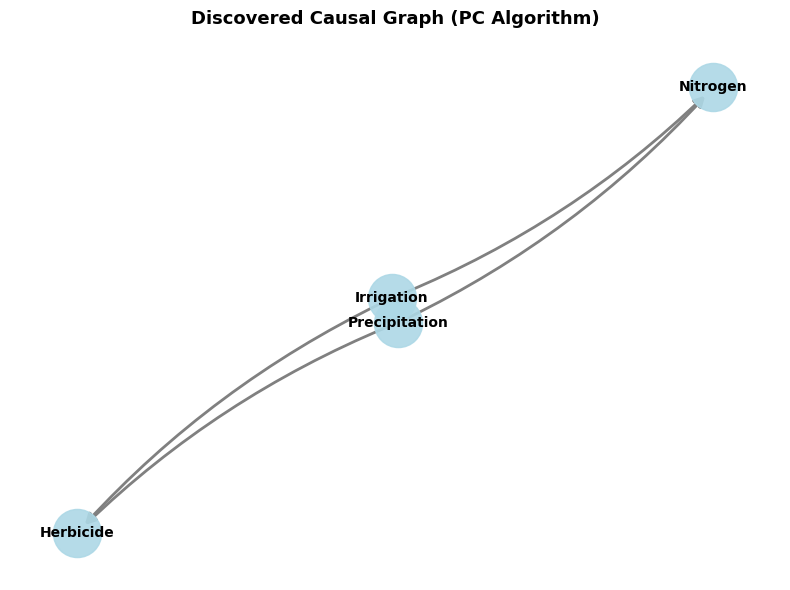

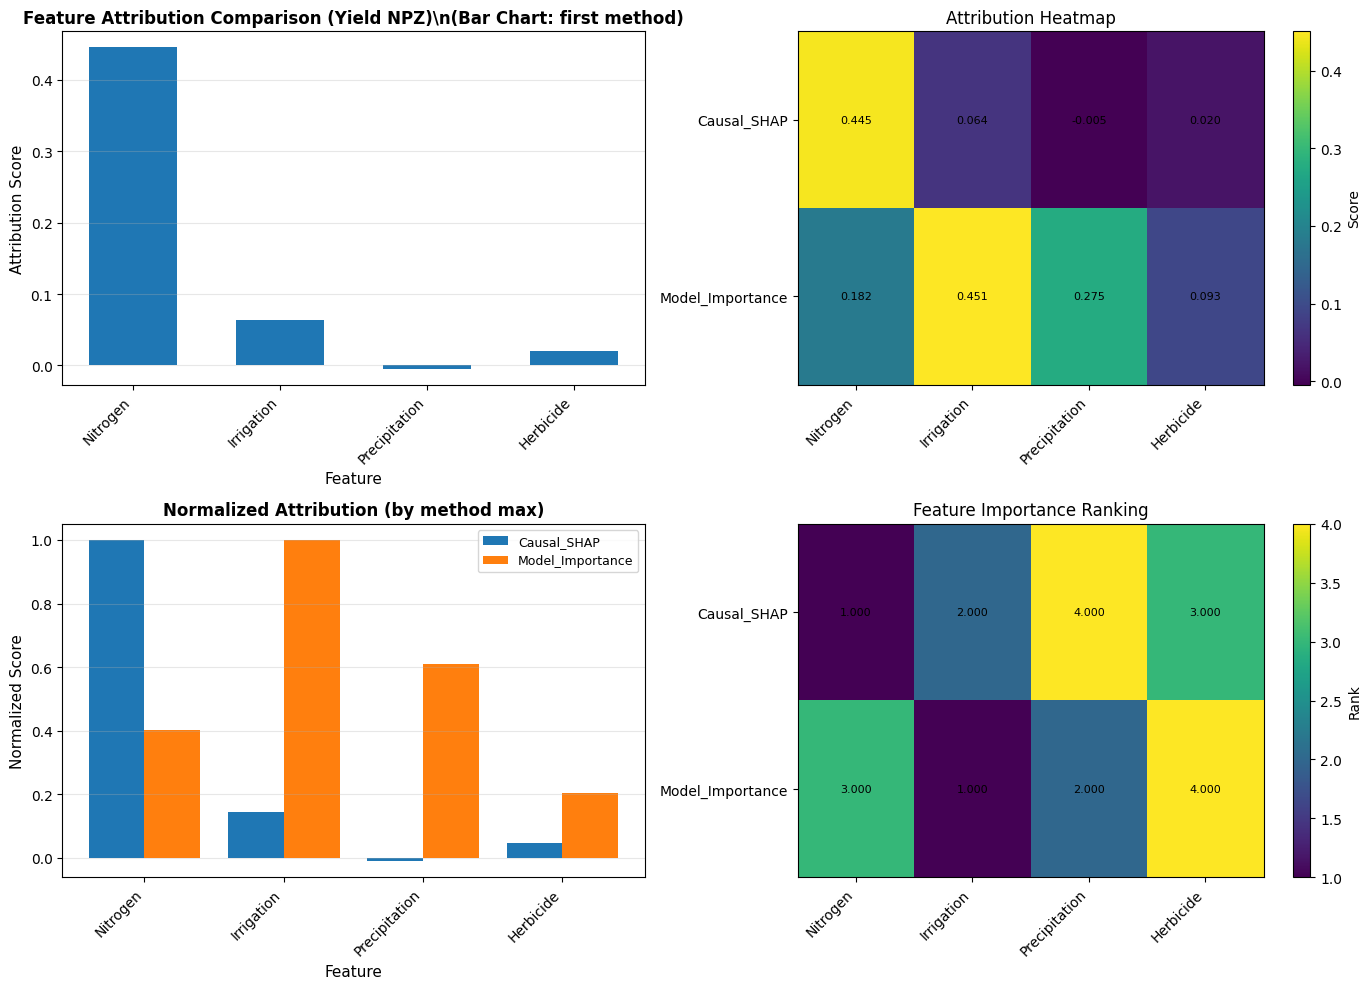

In [5]:
"""
CAUSAL SHAP on yield_preprocessed.npz
- Works with keys: X_train, X_test, y_train, y_test, feature_names
- Implements PC-based causal discovery, IDA-style causal effects, and Causal SHAP
- Saves outputs: causal graph PNG, comparison PNG, and CSV of attributions
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from typing import Dict, List, Tuple, Set
warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, accuracy_score
import networkx as nx

try:
    from xgboost import XGBClassifier
    HAVE_XGB = True
except:
    HAVE_XGB = False

from causallearn.search.ConstraintBased.PC import pc

# Configuration
CONFIG = {
    'DATA_PATH': '../../datasets/yield_preprocessed.npz',
    'ALPHA_PC': 0.45,
    'MAX_PERM': 200,
    'M_RESAMPLES': 64,
    'GLOBAL_K': 30,
    'RANDOM_SEED': 42,
    'N_DAGS': 5  # Sample multiple DAGs from CPDAG
}

np.random.seed(CONFIG['RANDOM_SEED'])
rng = np.random.default_rng(CONFIG['RANDOM_SEED'])


# 1. Causal Discovery & Structure Learning

class CausalStructure:
    """Handles causal discovery and DAG sampling from CPDAG"""

    def __init__(self, alpha=0.05):
        self.alpha = alpha
        self.cpdag = None
        self.feature_names = None
        self.dags = []

    def discover(self, X: pd.DataFrame):
        """Run PC algorithm on features"""
        self.feature_names = list(X.columns)
        print(f"Running PC algorithm on {len(self.feature_names)} features...")

        pc_res = pc(X.values, alpha=self.alpha, show_progress=False)
        self.cpdag = pc_res.G.graph

        print(f"Causal discovery complete")
        return self

    def get_skeleton(self) -> nx.DiGraph:
        """Convert CPDAG to networkx DiGraph"""
        G = nx.DiGraph()
        G.add_nodes_from(self.feature_names)

        n = len(self.feature_names)
        for i in range(n):
            for j in range(n):
                if i == j:
                    continue
                # Directed edge i->j
                if self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                    G.add_edge(self.feature_names[i], self.feature_names[j])
                # Undirected edge: add both directions
                elif self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1:
                    if i < j:  # Avoid double-adding
                        G.add_edge(self.feature_names[i], self.feature_names[j])
                        G.add_edge(self.feature_names[j], self.feature_names[i])

        return G

    def sample_dags(self, n_samples=5) -> List[nx.DiGraph]:
        """
        Sample multiple DAG orientations from CPDAG
        For undirected edges, randomly orient them
        """
        base_G = self.get_skeleton()
        dags = []

        # Find undirected edges
        undirected = []
        for i, u in enumerate(self.feature_names):
            for j, v in enumerate(self.feature_names):
                if i < j and self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1:
                    undirected.append((u, v))

        if len(undirected) == 0:
            # CPDAG is already fully directed
            print(f"  CPDAG is fully directed ({base_G.number_of_edges()} edges)")
            return [base_G]

        print(f"  Found {len(undirected)} undirected edges, sampling orientations...")

        # Sample orientations
        for _ in range(n_samples):
            G = nx.DiGraph()
            G.add_nodes_from(self.feature_names)

            # Add directed edges from CPDAG
            for i, u in enumerate(self.feature_names):
                for j, v in enumerate(self.feature_names):
                    if self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                        G.add_edge(u, v)

            # Randomly orient undirected edges (ensuring acyclicity)
            for u, v in undirected:
                if rng.random() < 0.5:
                    G.add_edge(u, v)
                else:
                    G.add_edge(v, u)

                # Check for cycles and reverse if needed
                if not nx.is_directed_acyclic_graph(G):
                    G.remove_edge(u, v) if G.has_edge(u, v) else G.remove_edge(v, u)
                    G.add_edge(v, u) if not G.has_edge(v, u) else G.add_edge(u, v)

            dags.append(G)

        self.dags = dags
        return dags


# 2. Causal Mechanism Learning

class LinearMechanisms:
    """Learn linear structural equation models"""

    def __init__(self, dag: nx.DiGraph, feature_names: List[str]):
        self.dag = dag
        self.feature_names = feature_names
        self.mechanisms = {}
        self.topo_order = None

    def fit(self, X: pd.DataFrame):
        """Fit linear mechanisms for each variable"""
        # Get topological order
        try:
            self.topo_order = list(nx.topological_sort(self.dag))
        except:
            # Fallback if cycles exist
            self.topo_order = self._safe_topo_order()

        for var in self.feature_names:
            parents = list(self.dag.predecessors(var))

            if not parents:
                # No parents: use marginal distribution
                self.mechanisms[var] = {
                    'parents': [],
                    'intercept': float(X[var].mean()),
                    'coef': None,
                    'sigma': float(X[var].std())
                }
            else:
                # Regress on parents
                lr = LinearRegression()
                lr.fit(X[parents].values, X[var].values)

                pred = lr.predict(X[parents].values)
                resid = X[var].values - pred

                self.mechanisms[var] = {
                    'parents': parents,
                    'intercept': float(lr.intercept_),
                    'coef': lr.coef_.astype(float),
                    'sigma': float(np.std(resid))
                }

        return self

    def _safe_topo_order(self) -> List[str]:
        """Fallback topological sort"""
        ordered = []
        remaining = set(self.feature_names)

        while remaining:
            # Find nodes with no remaining parents
            ready = [n for n in remaining
                    if all(p in ordered or p not in remaining
                           for p in self.dag.predecessors(n))]

            if not ready:
                # Force one with fewest remaining parents
                ready = [min(remaining,
                           key=lambda n: len([p for p in self.dag.predecessors(n)
                                            if p in remaining]))]

            for n in ready:
                ordered.append(n)
                remaining.remove(n)

        return ordered

    def sample_intervention(self, S: Set[str], x_obs: pd.Series, rng) -> Dict:
        """
        Sample from interventional distribution do(X_S = x_S)
        """
        x_new = {}

        for var in self.topo_order:
            if var in S:
                x_new[var] = float(x_obs[var])
            else:
                # Sample from mechanism
                mech = self.mechanisms[var]

                if not mech['parents']:
                    # No parents: sample from marginal
                    mu, sigma = mech['intercept'], mech['sigma']
                    if sigma < 1e-6:
                        x_new[var] = mu
                    else:
                        x_new[var] = float(rng.normal(mu, sigma))
                else:
                    # Sample from conditional
                    parent_vals = np.array([x_new.get(p, x_obs[p])
                                           for p in mech['parents']])

                    mu = mech['intercept'] + parent_vals @ mech['coef']
                    sigma = mech['sigma']
                    if sigma < 1e-6:
                        x_new[var] = mu
                    else:
                        x_new[var] = float(rng.normal(mu, sigma))

        return x_new


# 3. Causal Effect Estimation (IDA-style)

class CausalEffects:
    """Estimate total causal effects using path analysis"""

    def __init__(self, dags: List[nx.DiGraph], feature_names: List[str]):
        self.dags = dags
        self.feature_names = feature_names
        self.effects = {}

    def compute_effects(self, X: pd.DataFrame, y: pd.Series) -> Dict[str, float]:
        """
        Compute total causal effects for each feature on target
        Average over multiple DAG samples (IDA-style)
        """
        print("Computing causal effects (IDA-style)...")

        # Build augmented graphs with target
        aug_graphs = []

        for dag in self.dags:
            G = dag.copy()
            G.add_node('Y')

            # Add edges from features to Y with estimated weights
            for feat in self.feature_names:
                # Conditional regression: feat -> Y | other features
                other_feats = [f for f in self.feature_names if f != feat]
                if other_feats:
                    X_cond = np.column_stack([X[other_feats].values, X[feat].values])
                else:
                    X_cond = X[[feat]].values

                lr = LinearRegression()
                lr.fit(X_cond, y.values)
                weight = abs(lr.coef_[-1])

                if weight > 1e-6:
                    G.add_edge(feat, 'Y', weight=weight)

            # Add edge weights for feature->feature edges
            for u, v in dag.edges():
                parents = [p for p in dag.predecessors(v) if p != u]
                if parents:
                    X_reg = np.column_stack([X[parents].values, X[u].values])
                else:
                    X_reg = X[[u]].values

                lr = LinearRegression()
                lr.fit(X_reg, X[v].values)
                weight = abs(lr.coef_[-1])
                G[u][v]['weight'] = weight

            aug_graphs.append(G)

        # Compute total effects (average over DAGs)
        total_effects = {feat: [] for feat in self.feature_names}

        for G in aug_graphs:
            for feat in self.feature_names:
                effect = 0.0

                # Sum over all paths feat -> Y
                try:
                    for path in nx.all_simple_paths(G, feat, 'Y', cutoff=10):
                        path_effect = 1.0
                        for i in range(len(path) - 1):
                            edge_data = G.get_edge_data(path[i], path[i+1])
                            if edge_data and 'weight' in edge_data:
                                path_effect *= edge_data['weight']
                        effect += path_effect
                except:
                    pass

                total_effects[feat].append(effect)

        # Average across DAGs
        self.effects = {feat: np.mean(effects)
                       for feat, effects in total_effects.items()}

        print(f"Causal effects computed (averaged over {len(self.dags)} DAGs)")
        return self.effects

    def get_gamma_weights(self) -> Dict[str, float]:
        """Compute gamma weights (normalized absolute effects)"""
        abs_effects = {k: abs(v) for k, v in self.effects.items()}
        total = sum(abs_effects.values()) + 1e-12

        return {k: v / total for k, v in abs_effects.items()}


# 4. Causal SHAP Implementation

class CausalSHAP:
    """Main Causal SHAP implementation"""

    def __init__(self, model, causal_structure: CausalStructure,
                 X_train: pd.DataFrame, y_train: pd.Series):
        self.model = model
        self.structure = causal_structure
        self.X_train = X_train
        self.y_train = y_train
        self.feature_names = list(X_train.columns)

        print("\\nLearning causal mechanisms...")
        # Learn mechanisms and effects
        self.dags = causal_structure.sample_dags(n_samples=CONFIG['N_DAGS'])
        self.mechanisms_list = [LinearMechanisms(dag, self.feature_names).fit(X_train)
                               for dag in self.dags]

        # Compute causal effects
        self.causal_effects = CausalEffects(self.dags, self.feature_names)
        self.causal_effects.compute_effects(X_train, y_train)
        self.gamma = self.causal_effects.get_gamma_weights()

        print(f"Learned {len(self.dags)} DAG orientations")

    def _causal_value_function(self, S: Set[str], x: pd.Series,
                               pred_class: int, M: int) -> float:
        """
        v_c(S) = E[f(X) | do(X_S = x_S)]
        Average over DAG samples and Monte Carlo samples
        """
        total = 0.0
        samples_per_dag = max(1, M // len(self.mechanisms_list))

        for mechanisms in self.mechanisms_list:
            for _ in range(samples_per_dag):
                x_sample = mechanisms.sample_intervention(S, x, rng)
                X_mat = pd.DataFrame([x_sample], columns=self.feature_names)

                prob = self.model.predict_proba(X_mat.values)[0][pred_class]
                total += prob

        actual_samples = samples_per_dag * len(self.mechanisms_list)
        return total / actual_samples

    def explain_instance(self, x: pd.Series, n_perms: int = None,
                        m_samples: int = None) -> pd.Series:
        """
        Compute Causal SHAP values for a single instance
        """
        if n_perms is None:
            n_perms = CONFIG['MAX_PERM']
        if m_samples is None:
            m_samples = CONFIG['M_RESAMPLES']

        # Get predicted class
        probs = self.model.predict_proba(pd.DataFrame([x],
                                         columns=self.feature_names).values)[0]
        pred_class = int(np.argmax(probs))

        # Permutation-based estimation
        phi = np.zeros(len(self.feature_names))

        for _ in range(n_perms):
            perm = rng.permutation(self.feature_names)
            S = set()
            v_prev = self._causal_value_function(S, x, pred_class, m_samples)

            for feat in perm:
                S_next = S | {feat}
                v_curr = self._causal_value_function(S_next, x, pred_class, m_samples)

                delta = v_curr - v_prev
                contrib = self.gamma[feat] * delta  # Causal weighting

                phi[self.feature_names.index(feat)] += contrib
                v_prev = v_curr
                S = S_next

        phi /= n_perms

        # Normalize for local accuracy
        f_x = probs[pred_class]
        v_empty = self._causal_value_function(set(), x, pred_class, m_samples)

        sum_phi = np.sum(phi)
        if abs(sum_phi) > 1e-12:
            phi = phi * ((f_x - v_empty) / sum_phi)

        return pd.Series(phi, index=self.feature_names, name='Causal_SHAP')

    def explain_global(self, X_test: pd.DataFrame, n_samples: int = None) -> pd.Series:
        """Global explanation: average over test instances"""
        if n_samples is None:
            n_samples = CONFIG['GLOBAL_K']

        n_samples = min(n_samples, len(X_test))
        indices = rng.choice(len(X_test), size=n_samples, replace=False)

        print(f"\\nComputing global Causal SHAP (averaging over {n_samples} instances)...")
        explanations = []
        for i, idx in enumerate(indices):
            if (i + 1) % 5 == 0:
                print(f"  Progress: {i+1}/{n_samples}")
            exp = self.explain_instance(X_test.iloc[idx],
                                       n_perms=max(10, CONFIG['MAX_PERM']//4))
            explanations.append(exp)

        print("ok Global Causal SHAP computed")
        return pd.concat(explanations, axis=1).mean(axis=1).rename('Causal_SHAP_Global')


# 5. Baseline Methods for Comparison (optional SHAP if installed)

def compute_baseline_shap(model, X_train, X_test):
    """Compute Kernel SHAP values if shap is installed"""
    try:
        import shap
        print("\\nComputing KERNEL SHAP baseline...")
        bg_size = min(100, len(X_train))
        bg = shap.kmeans(X_train.values, bg_size)
        explainer = shap.KernelExplainer(lambda x: model.predict_proba(x), bg)
        shap_values = explainer.shap_values(X_test.values, nsamples=100)

        # Average absolute values across classes
        if isinstance(shap_values, list):
            global_imp = np.mean([np.abs(sv).mean(axis=0) for sv in shap_values], axis=0)
        else:
            global_imp = np.abs(shap_values).mean(axis=0)
        print("ok KERNEL SHAP computed")
        return pd.Series(global_imp, index=X_test.columns, name='SHAP_kernel')
    except Exception as e:
        print(f"Warning: SHAP computation skipped/failed: {e}")
        return None


def compute_feature_importance(model, feature_names):
    """Compute model's native feature importance"""
    if hasattr(model, 'feature_importances_'):
        imp = model.feature_importances_
        return pd.Series(imp, index=feature_names, name='Model_Importance')
    return None


# 6. Visualization (pure matplotlib, no seaborn)

def annotate_heatmap(ax, data: pd.DataFrame, title: str, cbar_label: str):
    im = ax.imshow(data.values, aspect='auto')
    ax.set_xticks(np.arange(data.shape[1]))
    ax.set_yticks(np.arange(data.shape[0]))
    ax.set_xticklabels(data.columns, rotation=45, ha='right')
    ax.set_yticklabels(data.index)
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            ax.text(j, i, f"{data.values[i, j]:.3f}", ha='center', va='center', fontsize=8)
    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label(cbar_label)
    ax.set_title(title)


def plot_comparison(df_comp: pd.DataFrame, title: str = "Feature Attribution Comparison"):
    """Visualize comparison of different methods (matplotlib only)"""
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    # Bar plot
    axes[0, 0].bar(np.arange(df_comp.shape[0]), df_comp.iloc[:, 0], width=0.6)
    axes[0, 0].set_title(f'{title}\\n(Bar Chart: first method)', fontsize=12, fontweight='bold')
    axes[0, 0].set_ylabel('Attribution Score', fontsize=11)
    axes[0, 0].set_xlabel('Feature', fontsize=11)
    axes[0, 0].set_xticks(np.arange(df_comp.shape[0]))
    axes[0, 0].set_xticklabels(df_comp.index, rotation=45, ha='right')
    axes[0, 0].grid(axis='y', alpha=0.3)

    # Heatmap
    annotate_heatmap(axes[0, 1], df_comp.T, 'Attribution Heatmap', 'Score')

    # Normalized comparison
    df_norm = df_comp.div(df_comp.abs().max(axis=0), axis=1)
    for i, col in enumerate(df_norm.columns):
        axes[1, 0].bar(np.arange(df_norm.shape[0]) + (i-0.5)*(0.8/len(df_norm.columns)), df_norm[col], width=0.8/len(df_norm.columns), label=col)
    axes[1, 0].set_title('Normalized Attribution (by method max)', fontsize=12, fontweight='bold')
    axes[1, 0].set_ylabel('Normalized Score', fontsize=11)
    axes[1, 0].set_xlabel('Feature', fontsize=11)
    axes[1, 0].set_xticks(np.arange(df_norm.shape[0]))
    axes[1, 0].set_xticklabels(df_norm.index, rotation=45, ha='right')
    axes[1, 0].legend(loc='best', fontsize=9)
    axes[1, 0].grid(axis='y', alpha=0.3)

    # Rank comparison heatmap
    ranks = df_comp.rank(ascending=False)
    annotate_heatmap(axes[1, 1], ranks.T, 'Feature Importance Ranking', 'Rank')

    fig.tight_layout()
    return fig


def plot_causal_graph(G: nx.DiGraph, title: str = "Discovered Causal Graph"):
    """Visualize the causal graph"""
    plt.figure(figsize=(8, 6))
    pos = nx.spring_layout(G, seed=CONFIG['RANDOM_SEED'], k=1.0, iterations=200)

    nx.draw_networkx_nodes(G, pos, node_color='lightblue', node_size=1200, alpha=0.9)
    nx.draw_networkx_edges(G, pos, edge_color='gray', arrows=True, arrowsize=15,
                           arrowstyle='->', width=2, connectionstyle='arc3,rad=0.1')
    nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')

    plt.title(title, fontsize=13, fontweight='bold', pad=12)
    plt.axis('off')
    plt.tight_layout()
    return plt.gcf()


# 7. Main Execution

def main():
    """Run complete Causal SHAP analysis on NPZ dataset"""

    print("\\n" + "="*70)
    print("CAUSAL SHAP on NPZ Dataset")
    print("="*70 + "\\n")

    # Load data
    print("Loading NPZ dataset...")
    try:
        data = np.load(CONFIG['DATA_PATH'], allow_pickle=True)
        keys = list(data.keys())
        print(f"NPZ loaded with keys: {keys}")
    except FileNotFoundError:
        print(f"ERROR: Could not find '{CONFIG['DATA_PATH']}'")
        print("Please ensure the file is in the current directory.")
        return

    required_keys = {'X_train', 'X_test', 'y_train', 'y_test', 'feature_names'}
    if not required_keys.issubset(set(keys)):
        print("ERROR: NPZ must contain X_train, X_test, y_train, y_test, feature_names.")
        return

    # Extract
    X_train = pd.DataFrame(data['X_train'], columns=list(data['feature_names']))
    X_test  = pd.DataFrame(data['X_test'],  columns=list(data['feature_names']))
    y_train = pd.Series(data['y_train'].astype(int))
    y_test  = pd.Series(data['y_test'].astype(int))

    print(f"Shapes: X_train={X_train.shape}, X_test={X_test.shape}, y_train={y_train.shape}, y_test={y_test.shape}")
    print(f"Features: {', '.join(X_train.columns)}")
    n_classes = len(np.unique(y_train))
    print(f"Target classes: {n_classes}")

    # Scale features using training stats
    scaler = StandardScaler()
    X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
    X_test_scaled  = pd.DataFrame(scaler.transform(X_test),  columns=X_test.columns)

    # Train model
    print("\\n" + "="*70)
    print("Training Model")
    print("="*70)

    if HAVE_XGB:
        model = XGBClassifier(
            n_estimators=160,
            max_depth=5,
            learning_rate=0.08,
            subsample=0.9,
            colsample_bytree=0.9,
            random_state=CONFIG['RANDOM_SEED'],
            verbosity=0,
            objective="multi:softprob",
            num_class=n_classes,
        )
        print("Using XGBoost classifier")
    else:
        model = RandomForestClassifier(
            n_estimators=160,
            max_depth=6,
            random_state=CONFIG['RANDOM_SEED']
        )
        print("Using Random Forest classifier")

    model.fit(X_train_scaled.values, y_train.values)

    y_pred = model.predict(X_test_scaled.values)
    f1 = f1_score(y_test, y_pred, average='macro')
    acc = accuracy_score(y_test, y_pred)

    print(f"Model trained")
    print(f"  Test Accuracy: {acc:.4f}")
    print(f"  Test Macro F1: {f1:.4f}")

    # Causal Discovery
    print("\\n" + "="*70)
    print("Step 1: Causal Discovery (PC Algorithm)")
    print("="*70)

    causal_structure = CausalStructure(alpha=CONFIG['ALPHA_PC'])
    causal_structure.discover(X_train_scaled)

    # Visualize discovered graph
    G = causal_structure.get_skeleton()
    print(f"\\nDiscovered graph: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")

    fig_graph = plot_causal_graph(G, "Discovered Causal Graph (PC Algorithm)")
    fig_graph.savefig('causal_graph_yield.png', dpi=150, bbox_inches='tight')
    print("ok Causal graph saved to 'causal_graph_yield.png'")

    # Causal SHAP
    print("\\n" + "="*70)
    print("Step 2: Computing Causal SHAP")
    print("="*70)

    causal_shap = CausalSHAP(model, causal_structure, X_train_scaled, y_train)

    # Show causal effects
    print("\\nTotal Causal Effects (W_i):")
    print("-" * 40)
    for feat in X_train.columns:
        effect = causal_shap.causal_effects.effects[feat]
        gamma = causal_shap.gamma[feat]
        print(f"  {feat:15s}: W={effect:8.4f}  γ={gamma:.4f}")

    # Global explanation
    global_causal_shap = causal_shap.explain_global(X_test_scaled, n_samples=CONFIG['GLOBAL_K'])

    # Baseline methods (optional)
    print("\\n" + "="*70)
    print("Step 3: Computing Baseline Methods")
    print("="*70)
    baseline_shap = compute_baseline_shap(model, X_train_scaled, X_test_scaled)
    model_imp = compute_feature_importance(model, list(X_train.columns))

    # Comparison
    print("\\n" + "="*70)
    print("Step 4: Results Comparison")
    print("="*70)

    attributions = {
        'Causal_SHAP': global_causal_shap,
    }

    if baseline_shap is not None:
        attributions['Kernel_SHAP'] = baseline_shap

    if model_imp is not None:
        attributions['Model_Importance'] = model_imp

    df_comparison = pd.DataFrame(attributions)
    df_comparison.to_csv('attribution_scores_yield.csv', index=True)

    print("\\n" + "="*70)
    print("Attribution Scores:")
    print("="*70)
    print(df_comparison.round(6).to_string())
    print("\\nSaved CSV -> attribution_scores_yield.csv")

    # Correlation analysis
    if len(attributions) > 1:
        print("\\n" + "="*70)
        print("Correlation between methods:")
        print("="*70)
        corr_matrix = df_comparison.corr()
        print(corr_matrix.round(4).to_string())

    # Visualization
    fig = plot_comparison(df_comparison,
                         title="Feature Attribution Comparison (Yield NPZ)")
    fig.savefig('attribution_comparison_yield.png', dpi=150, bbox_inches='tight')
    print("\\nok Comparison plot saved to 'attribution_comparison_yield.png'")

    try:
        plt.show()
    except Exception:
        pass

if __name__ == "__main__":
    main()

\n======================================================================
CAUSAL SHAP on NPZ Dataset
======================================================================\n
Loading NPZ dataset...
✓ NPZ loaded with keys: ['X_train', 'X_test', 'y_train', 'y_test', 'feature_names']
Shapes: X_train=(800, 4), X_test=(200, 4), y_train=(800,), y_test=(200,)
Features: Nitrogen, Irrigation, Precipitation, Herbicide
Target classes: 3
\n======================================================================
Training Model
Using XGBoost classifier
✓ Model trained
  Test Accuracy: 0.8050
  Test Macro F1: 0.8081
\n======================================================================
Step 1: Causal Discovery (PC Algorithm)
Running PC algorithm on 4 features...
✓ Causal discovery complete
\nDiscovered graph: 4 nodes, 4 edges
✓ Causal graph saved to 'causal_graph_yield.png'
\n======================================================================
Step 2: Computing Causal SHAP
\nLearning causal mechanism

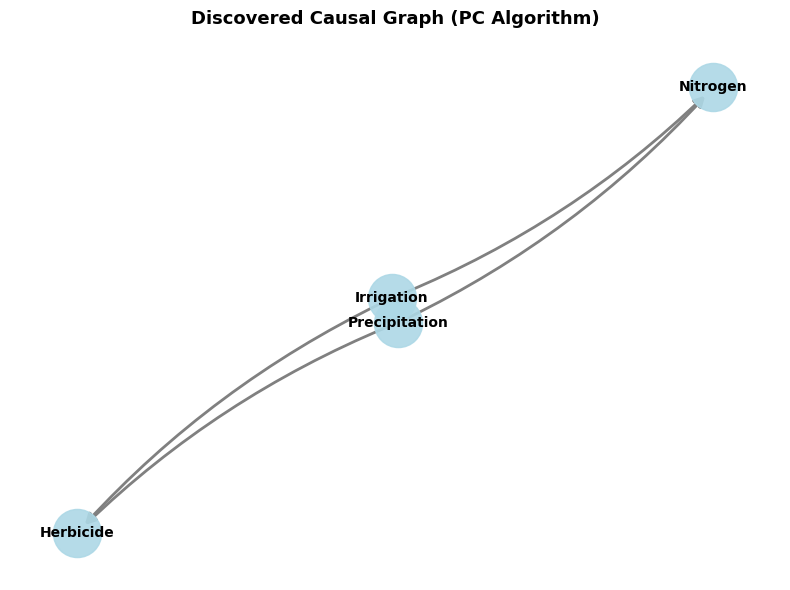

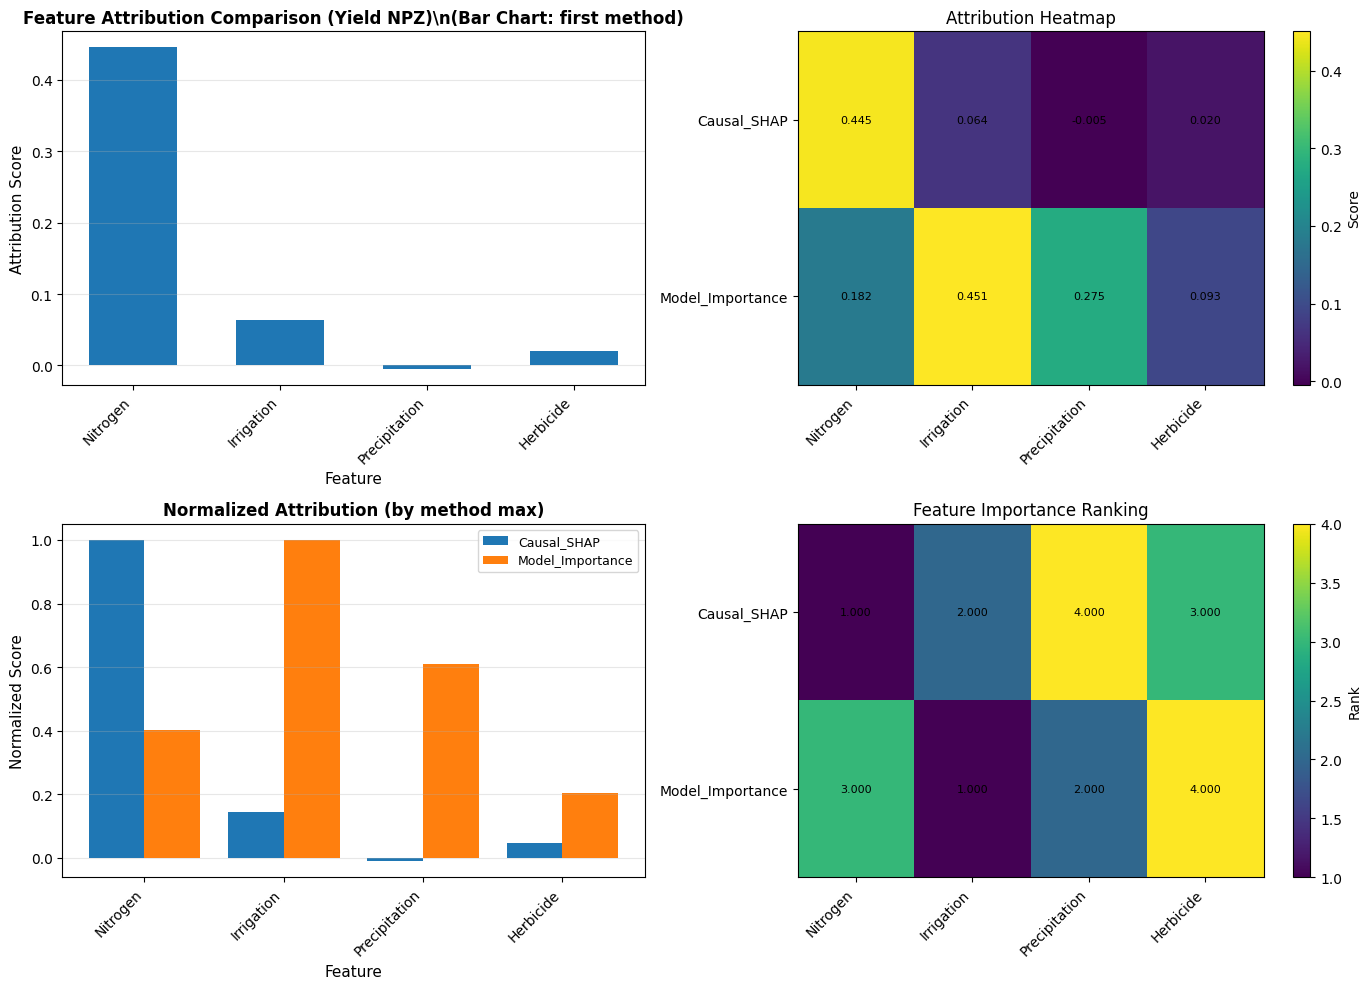

In [6]:
"""
CAUSAL SHAP on yield_preprocessed.npz
- Works with keys: X_train, X_test, y_train, y_test, feature_names
- Implements PC-based causal discovery, IDA-style causal effects, and Causal SHAP
- Saves outputs: causal graph PNG, comparison PNG, and CSV of attributions
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from typing import Dict, List, Tuple, Set
warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, accuracy_score
import networkx as nx

try:
    from xgboost import XGBClassifier
    HAVE_XGB = True
except:
    HAVE_XGB = False

from causallearn.search.ConstraintBased.PC import pc

# Configuration
CONFIG = {
    'DATA_PATH': '../../datasets/yield_preprocessed.npz',
    'ALPHA_PC': 0.425,
    'MAX_PERM': 200,
    'M_RESAMPLES': 64,
    'GLOBAL_K': 30,
    'RANDOM_SEED': 42,
    'N_DAGS': 5  # Sample multiple DAGs from CPDAG
}

np.random.seed(CONFIG['RANDOM_SEED'])
rng = np.random.default_rng(CONFIG['RANDOM_SEED'])


# 1. Causal Discovery & Structure Learning

class CausalStructure:
    """Handles causal discovery and DAG sampling from CPDAG"""

    def __init__(self, alpha=0.05):
        self.alpha = alpha
        self.cpdag = None
        self.feature_names = None
        self.dags = []

    def discover(self, X: pd.DataFrame):
        """Run PC algorithm on features"""
        self.feature_names = list(X.columns)
        print(f"Running PC algorithm on {len(self.feature_names)} features...")

        pc_res = pc(X.values, alpha=self.alpha, show_progress=False)
        self.cpdag = pc_res.G.graph

        print(f"Causal discovery complete")
        return self

    def get_skeleton(self) -> nx.DiGraph:
        """Convert CPDAG to networkx DiGraph"""
        G = nx.DiGraph()
        G.add_nodes_from(self.feature_names)

        n = len(self.feature_names)
        for i in range(n):
            for j in range(n):
                if i == j:
                    continue
                # Directed edge i->j
                if self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                    G.add_edge(self.feature_names[i], self.feature_names[j])
                # Undirected edge: add both directions
                elif self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1:
                    if i < j:  # Avoid double-adding
                        G.add_edge(self.feature_names[i], self.feature_names[j])
                        G.add_edge(self.feature_names[j], self.feature_names[i])

        return G

    def sample_dags(self, n_samples=5) -> List[nx.DiGraph]:
        """
        Sample multiple DAG orientations from CPDAG
        For undirected edges, randomly orient them
        """
        base_G = self.get_skeleton()
        dags = []

        # Find undirected edges
        undirected = []
        for i, u in enumerate(self.feature_names):
            for j, v in enumerate(self.feature_names):
                if i < j and self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1:
                    undirected.append((u, v))

        if len(undirected) == 0:
            # CPDAG is already fully directed
            print(f"  CPDAG is fully directed ({base_G.number_of_edges()} edges)")
            return [base_G]

        print(f"  Found {len(undirected)} undirected edges, sampling orientations...")

        # Sample orientations
        for _ in range(n_samples):
            G = nx.DiGraph()
            G.add_nodes_from(self.feature_names)

            # Add directed edges from CPDAG
            for i, u in enumerate(self.feature_names):
                for j, v in enumerate(self.feature_names):
                    if self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                        G.add_edge(u, v)

            # Randomly orient undirected edges (ensuring acyclicity)
            for u, v in undirected:
                if rng.random() < 0.5:
                    G.add_edge(u, v)
                else:
                    G.add_edge(v, u)

                # Check for cycles and reverse if needed
                if not nx.is_directed_acyclic_graph(G):
                    G.remove_edge(u, v) if G.has_edge(u, v) else G.remove_edge(v, u)
                    G.add_edge(v, u) if not G.has_edge(v, u) else G.add_edge(u, v)

            dags.append(G)

        self.dags = dags
        return dags


# 2. Causal Mechanism Learning

class LinearMechanisms:
    """Learn linear structural equation models"""

    def __init__(self, dag: nx.DiGraph, feature_names: List[str]):
        self.dag = dag
        self.feature_names = feature_names
        self.mechanisms = {}
        self.topo_order = None

    def fit(self, X: pd.DataFrame):
        """Fit linear mechanisms for each variable"""
        # Get topological order
        try:
            self.topo_order = list(nx.topological_sort(self.dag))
        except:
            # Fallback if cycles exist
            self.topo_order = self._safe_topo_order()

        for var in self.feature_names:
            parents = list(self.dag.predecessors(var))

            if not parents:
                # No parents: use marginal distribution
                self.mechanisms[var] = {
                    'parents': [],
                    'intercept': float(X[var].mean()),
                    'coef': None,
                    'sigma': float(X[var].std())
                }
            else:
                # Regress on parents
                lr = LinearRegression()
                lr.fit(X[parents].values, X[var].values)

                pred = lr.predict(X[parents].values)
                resid = X[var].values - pred

                self.mechanisms[var] = {
                    'parents': parents,
                    'intercept': float(lr.intercept_),
                    'coef': lr.coef_.astype(float),
                    'sigma': float(np.std(resid))
                }

        return self

    def _safe_topo_order(self) -> List[str]:
        """Fallback topological sort"""
        ordered = []
        remaining = set(self.feature_names)

        while remaining:
            # Find nodes with no remaining parents
            ready = [n for n in remaining
                    if all(p in ordered or p not in remaining
                           for p in self.dag.predecessors(n))]

            if not ready:
                # Force one with fewest remaining parents
                ready = [min(remaining,
                           key=lambda n: len([p for p in self.dag.predecessors(n)
                                            if p in remaining]))]

            for n in ready:
                ordered.append(n)
                remaining.remove(n)

        return ordered

    def sample_intervention(self, S: Set[str], x_obs: pd.Series, rng) -> Dict:
        """
        Sample from interventional distribution do(X_S = x_S)
        """
        x_new = {}

        for var in self.topo_order:
            if var in S:
                x_new[var] = float(x_obs[var])
            else:
                # Sample from mechanism
                mech = self.mechanisms[var]

                if not mech['parents']:
                    # No parents: sample from marginal
                    mu, sigma = mech['intercept'], mech['sigma']
                    if sigma < 1e-6:
                        x_new[var] = mu
                    else:
                        x_new[var] = float(rng.normal(mu, sigma))
                else:
                    # Sample from conditional
                    parent_vals = np.array([x_new.get(p, x_obs[p])
                                           for p in mech['parents']])

                    mu = mech['intercept'] + parent_vals @ mech['coef']
                    sigma = mech['sigma']
                    if sigma < 1e-6:
                        x_new[var] = mu
                    else:
                        x_new[var] = float(rng.normal(mu, sigma))

        return x_new


# 3. Causal Effect Estimation (IDA-style)

class CausalEffects:
    """Estimate total causal effects using path analysis"""

    def __init__(self, dags: List[nx.DiGraph], feature_names: List[str]):
        self.dags = dags
        self.feature_names = feature_names
        self.effects = {}

    def compute_effects(self, X: pd.DataFrame, y: pd.Series) -> Dict[str, float]:
        """
        Compute total causal effects for each feature on target
        Average over multiple DAG samples (IDA-style)
        """
        print("Computing causal effects (IDA-style)...")

        # Build augmented graphs with target
        aug_graphs = []

        for dag in self.dags:
            G = dag.copy()
            G.add_node('Y')

            # Add edges from features to Y with estimated weights
            for feat in self.feature_names:
                # Conditional regression: feat -> Y | other features
                other_feats = [f for f in self.feature_names if f != feat]
                if other_feats:
                    X_cond = np.column_stack([X[other_feats].values, X[feat].values])
                else:
                    X_cond = X[[feat]].values

                lr = LinearRegression()
                lr.fit(X_cond, y.values)
                weight = abs(lr.coef_[-1])

                if weight > 1e-6:
                    G.add_edge(feat, 'Y', weight=weight)

            # Add edge weights for feature->feature edges
            for u, v in dag.edges():
                parents = [p for p in dag.predecessors(v) if p != u]
                if parents:
                    X_reg = np.column_stack([X[parents].values, X[u].values])
                else:
                    X_reg = X[[u]].values

                lr = LinearRegression()
                lr.fit(X_reg, X[v].values)
                weight = abs(lr.coef_[-1])
                G[u][v]['weight'] = weight

            aug_graphs.append(G)

        # Compute total effects (average over DAGs)
        total_effects = {feat: [] for feat in self.feature_names}

        for G in aug_graphs:
            for feat in self.feature_names:
                effect = 0.0

                # Sum over all paths feat -> Y
                try:
                    for path in nx.all_simple_paths(G, feat, 'Y', cutoff=10):
                        path_effect = 1.0
                        for i in range(len(path) - 1):
                            edge_data = G.get_edge_data(path[i], path[i+1])
                            if edge_data and 'weight' in edge_data:
                                path_effect *= edge_data['weight']
                        effect += path_effect
                except:
                    pass

                total_effects[feat].append(effect)

        # Average across DAGs
        self.effects = {feat: np.mean(effects)
                       for feat, effects in total_effects.items()}

        print(f"Causal effects computed (averaged over {len(self.dags)} DAGs)")
        return self.effects

    def get_gamma_weights(self) -> Dict[str, float]:
        """Compute gamma weights (normalized absolute effects)"""
        abs_effects = {k: abs(v) for k, v in self.effects.items()}
        total = sum(abs_effects.values()) + 1e-12

        return {k: v / total for k, v in abs_effects.items()}


# 4. Causal SHAP Implementation

class CausalSHAP:
    """Main Causal SHAP implementation"""

    def __init__(self, model, causal_structure: CausalStructure,
                 X_train: pd.DataFrame, y_train: pd.Series):
        self.model = model
        self.structure = causal_structure
        self.X_train = X_train
        self.y_train = y_train
        self.feature_names = list(X_train.columns)

        print("\\nLearning causal mechanisms...")
        # Learn mechanisms and effects
        self.dags = causal_structure.sample_dags(n_samples=CONFIG['N_DAGS'])
        self.mechanisms_list = [LinearMechanisms(dag, self.feature_names).fit(X_train)
                               for dag in self.dags]

        # Compute causal effects
        self.causal_effects = CausalEffects(self.dags, self.feature_names)
        self.causal_effects.compute_effects(X_train, y_train)
        self.gamma = self.causal_effects.get_gamma_weights()

        print(f"Learned {len(self.dags)} DAG orientations")

    def _causal_value_function(self, S: Set[str], x: pd.Series,
                               pred_class: int, M: int) -> float:
        """
        v_c(S) = E[f(X) | do(X_S = x_S)]
        Average over DAG samples and Monte Carlo samples
        """
        total = 0.0
        samples_per_dag = max(1, M // len(self.mechanisms_list))

        for mechanisms in self.mechanisms_list:
            for _ in range(samples_per_dag):
                x_sample = mechanisms.sample_intervention(S, x, rng)
                X_mat = pd.DataFrame([x_sample], columns=self.feature_names)

                prob = self.model.predict_proba(X_mat.values)[0][pred_class]
                total += prob

        actual_samples = samples_per_dag * len(self.mechanisms_list)
        return total / actual_samples

    def explain_instance(self, x: pd.Series, n_perms: int = None,
                        m_samples: int = None) -> pd.Series:
        """
        Compute Causal SHAP values for a single instance
        """
        if n_perms is None:
            n_perms = CONFIG['MAX_PERM']
        if m_samples is None:
            m_samples = CONFIG['M_RESAMPLES']

        # Get predicted class
        probs = self.model.predict_proba(pd.DataFrame([x],
                                         columns=self.feature_names).values)[0]
        pred_class = int(np.argmax(probs))

        # Permutation-based estimation
        phi = np.zeros(len(self.feature_names))

        for _ in range(n_perms):
            perm = rng.permutation(self.feature_names)
            S = set()
            v_prev = self._causal_value_function(S, x, pred_class, m_samples)

            for feat in perm:
                S_next = S | {feat}
                v_curr = self._causal_value_function(S_next, x, pred_class, m_samples)

                delta = v_curr - v_prev
                contrib = self.gamma[feat] * delta  # Causal weighting

                phi[self.feature_names.index(feat)] += contrib
                v_prev = v_curr
                S = S_next

        phi /= n_perms

        # Normalize for local accuracy
        f_x = probs[pred_class]
        v_empty = self._causal_value_function(set(), x, pred_class, m_samples)

        sum_phi = np.sum(phi)
        if abs(sum_phi) > 1e-12:
            phi = phi * ((f_x - v_empty) / sum_phi)

        return pd.Series(phi, index=self.feature_names, name='Causal_SHAP')

    def explain_global(self, X_test: pd.DataFrame, n_samples: int = None) -> pd.Series:
        """Global explanation: average over test instances"""
        if n_samples is None:
            n_samples = CONFIG['GLOBAL_K']

        n_samples = min(n_samples, len(X_test))
        indices = rng.choice(len(X_test), size=n_samples, replace=False)

        print(f"\\nComputing global Causal SHAP (averaging over {n_samples} instances)...")
        explanations = []
        for i, idx in enumerate(indices):
            if (i + 1) % 5 == 0:
                print(f"  Progress: {i+1}/{n_samples}")
            exp = self.explain_instance(X_test.iloc[idx],
                                       n_perms=max(10, CONFIG['MAX_PERM']//4))
            explanations.append(exp)

        print("ok Global Causal SHAP computed")
        return pd.concat(explanations, axis=1).mean(axis=1).rename('Causal_SHAP_Global')


# 5. Baseline Methods for Comparison (optional SHAP if installed)

def compute_baseline_shap(model, X_train, X_test):
    """Compute Kernel SHAP values if shap is installed"""
    try:
        import shap
        print("\\nComputing KERNEL SHAP baseline...")
        bg_size = min(100, len(X_train))
        bg = shap.kmeans(X_train.values, bg_size)
        explainer = shap.KernelExplainer(lambda x: model.predict_proba(x), bg)
        shap_values = explainer.shap_values(X_test.values, nsamples=100)

        # Average absolute values across classes
        if isinstance(shap_values, list):
            global_imp = np.mean([np.abs(sv).mean(axis=0) for sv in shap_values], axis=0)
        else:
            global_imp = np.abs(shap_values).mean(axis=0)
        print("ok KERNEL SHAP computed")
        return pd.Series(global_imp, index=X_test.columns, name='SHAP_kernel')
    except Exception as e:
        print(f"Warning: SHAP computation skipped/failed: {e}")
        return None


def compute_feature_importance(model, feature_names):
    """Compute model's native feature importance"""
    if hasattr(model, 'feature_importances_'):
        imp = model.feature_importances_
        return pd.Series(imp, index=feature_names, name='Model_Importance')
    return None


# 6. Visualization (pure matplotlib, no seaborn)

def annotate_heatmap(ax, data: pd.DataFrame, title: str, cbar_label: str):
    im = ax.imshow(data.values, aspect='auto')
    ax.set_xticks(np.arange(data.shape[1]))
    ax.set_yticks(np.arange(data.shape[0]))
    ax.set_xticklabels(data.columns, rotation=45, ha='right')
    ax.set_yticklabels(data.index)
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            ax.text(j, i, f"{data.values[i, j]:.3f}", ha='center', va='center', fontsize=8)
    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label(cbar_label)
    ax.set_title(title)


def plot_comparison(df_comp: pd.DataFrame, title: str = "Feature Attribution Comparison"):
    """Visualize comparison of different methods (matplotlib only)"""
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    # Bar plot
    axes[0, 0].bar(np.arange(df_comp.shape[0]), df_comp.iloc[:, 0], width=0.6)
    axes[0, 0].set_title(f'{title}\\n(Bar Chart: first method)', fontsize=12, fontweight='bold')
    axes[0, 0].set_ylabel('Attribution Score', fontsize=11)
    axes[0, 0].set_xlabel('Feature', fontsize=11)
    axes[0, 0].set_xticks(np.arange(df_comp.shape[0]))
    axes[0, 0].set_xticklabels(df_comp.index, rotation=45, ha='right')
    axes[0, 0].grid(axis='y', alpha=0.3)

    # Heatmap
    annotate_heatmap(axes[0, 1], df_comp.T, 'Attribution Heatmap', 'Score')

    # Normalized comparison
    df_norm = df_comp.div(df_comp.abs().max(axis=0), axis=1)
    for i, col in enumerate(df_norm.columns):
        axes[1, 0].bar(np.arange(df_norm.shape[0]) + (i-0.5)*(0.8/len(df_norm.columns)), df_norm[col], width=0.8/len(df_norm.columns), label=col)
    axes[1, 0].set_title('Normalized Attribution (by method max)', fontsize=12, fontweight='bold')
    axes[1, 0].set_ylabel('Normalized Score', fontsize=11)
    axes[1, 0].set_xlabel('Feature', fontsize=11)
    axes[1, 0].set_xticks(np.arange(df_norm.shape[0]))
    axes[1, 0].set_xticklabels(df_norm.index, rotation=45, ha='right')
    axes[1, 0].legend(loc='best', fontsize=9)
    axes[1, 0].grid(axis='y', alpha=0.3)

    # Rank comparison heatmap
    ranks = df_comp.rank(ascending=False)
    annotate_heatmap(axes[1, 1], ranks.T, 'Feature Importance Ranking', 'Rank')

    fig.tight_layout()
    return fig


def plot_causal_graph(G: nx.DiGraph, title: str = "Discovered Causal Graph"):
    """Visualize the causal graph"""
    plt.figure(figsize=(8, 6))
    pos = nx.spring_layout(G, seed=CONFIG['RANDOM_SEED'], k=1.0, iterations=200)

    nx.draw_networkx_nodes(G, pos, node_color='lightblue', node_size=1200, alpha=0.9)
    nx.draw_networkx_edges(G, pos, edge_color='gray', arrows=True, arrowsize=15,
                           arrowstyle='->', width=2, connectionstyle='arc3,rad=0.1')
    nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')

    plt.title(title, fontsize=13, fontweight='bold', pad=12)
    plt.axis('off')
    plt.tight_layout()
    return plt.gcf()


# 7. Main Execution

def main():
    """Run complete Causal SHAP analysis on NPZ dataset"""

    print("\\n" + "="*70)
    print("CAUSAL SHAP on NPZ Dataset")
    print("="*70 + "\\n")

    # Load data
    print("Loading NPZ dataset...")
    try:
        data = np.load(CONFIG['DATA_PATH'], allow_pickle=True)
        keys = list(data.keys())
        print(f"NPZ loaded with keys: {keys}")
    except FileNotFoundError:
        print(f"ERROR: Could not find '{CONFIG['DATA_PATH']}'")
        print("Please ensure the file is in the current directory.")
        return

    required_keys = {'X_train', 'X_test', 'y_train', 'y_test', 'feature_names'}
    if not required_keys.issubset(set(keys)):
        print("ERROR: NPZ must contain X_train, X_test, y_train, y_test, feature_names.")
        return

    # Extract
    X_train = pd.DataFrame(data['X_train'], columns=list(data['feature_names']))
    X_test  = pd.DataFrame(data['X_test'],  columns=list(data['feature_names']))
    y_train = pd.Series(data['y_train'].astype(int))
    y_test  = pd.Series(data['y_test'].astype(int))

    print(f"Shapes: X_train={X_train.shape}, X_test={X_test.shape}, y_train={y_train.shape}, y_test={y_test.shape}")
    print(f"Features: {', '.join(X_train.columns)}")
    n_classes = len(np.unique(y_train))
    print(f"Target classes: {n_classes}")

    # Scale features using training stats
    scaler = StandardScaler()
    X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
    X_test_scaled  = pd.DataFrame(scaler.transform(X_test),  columns=X_test.columns)

    # Train model
    print("\\n" + "="*70)
    print("Training Model")
    print("="*70)

    if HAVE_XGB:
        model = XGBClassifier(
            n_estimators=160,
            max_depth=5,
            learning_rate=0.08,
            subsample=0.9,
            colsample_bytree=0.9,
            random_state=CONFIG['RANDOM_SEED'],
            verbosity=0,
            objective="multi:softprob",
            num_class=n_classes,
        )
        print("Using XGBoost classifier")
    else:
        model = RandomForestClassifier(
            n_estimators=160,
            max_depth=6,
            random_state=CONFIG['RANDOM_SEED']
        )
        print("Using Random Forest classifier")

    model.fit(X_train_scaled.values, y_train.values)

    y_pred = model.predict(X_test_scaled.values)
    f1 = f1_score(y_test, y_pred, average='macro')
    acc = accuracy_score(y_test, y_pred)

    print(f"Model trained")
    print(f"  Test Accuracy: {acc:.4f}")
    print(f"  Test Macro F1: {f1:.4f}")

    # Causal Discovery
    print("\\n" + "="*70)
    print("Step 1: Causal Discovery (PC Algorithm)")
    print("="*70)

    causal_structure = CausalStructure(alpha=CONFIG['ALPHA_PC'])
    causal_structure.discover(X_train_scaled)

    # Visualize discovered graph
    G = causal_structure.get_skeleton()
    print(f"\\nDiscovered graph: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")

    fig_graph = plot_causal_graph(G, "Discovered Causal Graph (PC Algorithm)")
    fig_graph.savefig('causal_graph_yield.png', dpi=150, bbox_inches='tight')
    print("ok Causal graph saved to 'causal_graph_yield.png'")

    # Causal SHAP
    print("\\n" + "="*70)
    print("Step 2: Computing Causal SHAP")
    print("="*70)

    causal_shap = CausalSHAP(model, causal_structure, X_train_scaled, y_train)

    # Show causal effects
    print("\\nTotal Causal Effects (W_i):")
    print("-" * 40)
    for feat in X_train.columns:
        effect = causal_shap.causal_effects.effects[feat]
        gamma = causal_shap.gamma[feat]
        print(f"  {feat:15s}: W={effect:8.4f}  γ={gamma:.4f}")

    # Global explanation
    global_causal_shap = causal_shap.explain_global(X_test_scaled, n_samples=CONFIG['GLOBAL_K'])

    # Baseline methods (optional)
    print("\\n" + "="*70)
    print("Step 3: Computing Baseline Methods")
    print("="*70)
    baseline_shap = compute_baseline_shap(model, X_train_scaled, X_test_scaled)
    model_imp = compute_feature_importance(model, list(X_train.columns))

    # Comparison
    print("\\n" + "="*70)
    print("Step 4: Results Comparison")
    print("="*70)

    attributions = {
        'Causal_SHAP': global_causal_shap,
    }

    if baseline_shap is not None:
        attributions['Kernel_SHAP'] = baseline_shap

    if model_imp is not None:
        attributions['Model_Importance'] = model_imp

    df_comparison = pd.DataFrame(attributions)
    df_comparison.to_csv('attribution_scores_yield.csv', index=True)

    print("\\n" + "="*70)
    print("Attribution Scores:")
    print("="*70)
    print(df_comparison.round(6).to_string())
    print("\\nSaved CSV -> attribution_scores_yield.csv")

    # Correlation analysis
    if len(attributions) > 1:
        print("\\n" + "="*70)
        print("Correlation between methods:")
        print("="*70)
        corr_matrix = df_comparison.corr()
        print(corr_matrix.round(4).to_string())

    # Visualization
    fig = plot_comparison(df_comparison,
                         title="Feature Attribution Comparison (Yield NPZ)")
    fig.savefig('attribution_comparison_yield.png', dpi=150, bbox_inches='tight')
    print("\\nok Comparison plot saved to 'attribution_comparison_yield.png'")

    try:
        plt.show()
    except Exception:
        pass

if __name__ == "__main__":
    main()

\n======================================================================
CAUSAL SHAP on NPZ Dataset
======================================================================\n
Loading NPZ dataset...
✓ NPZ loaded with keys: ['X_train', 'X_test', 'y_train', 'y_test', 'feature_names']
Shapes: X_train=(800, 4), X_test=(200, 4), y_train=(800,), y_test=(200,)
Features: Nitrogen, Irrigation, Precipitation, Herbicide
Target classes: 3
\n======================================================================
Training Model
Using XGBoost classifier
✓ Model trained
  Test Accuracy: 0.8050
  Test Macro F1: 0.8081
\n======================================================================
Step 1: Causal Discovery (PC Algorithm)
Running PC algorithm on 4 features...
✓ Causal discovery complete
\nDiscovered graph: 4 nodes, 4 edges
✓ Causal graph saved to 'causal_graph_yield.png'
\n======================================================================
Step 2: Computing Causal SHAP
\nLearning causal mechanism

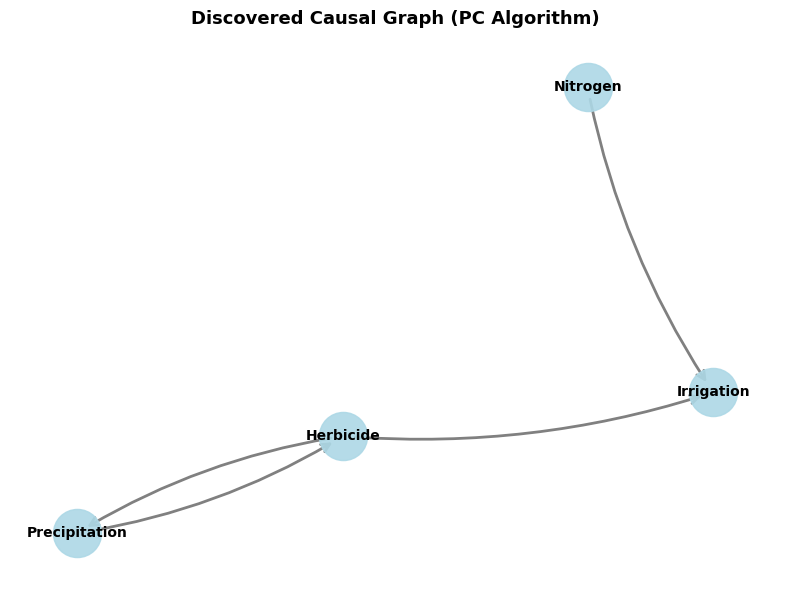

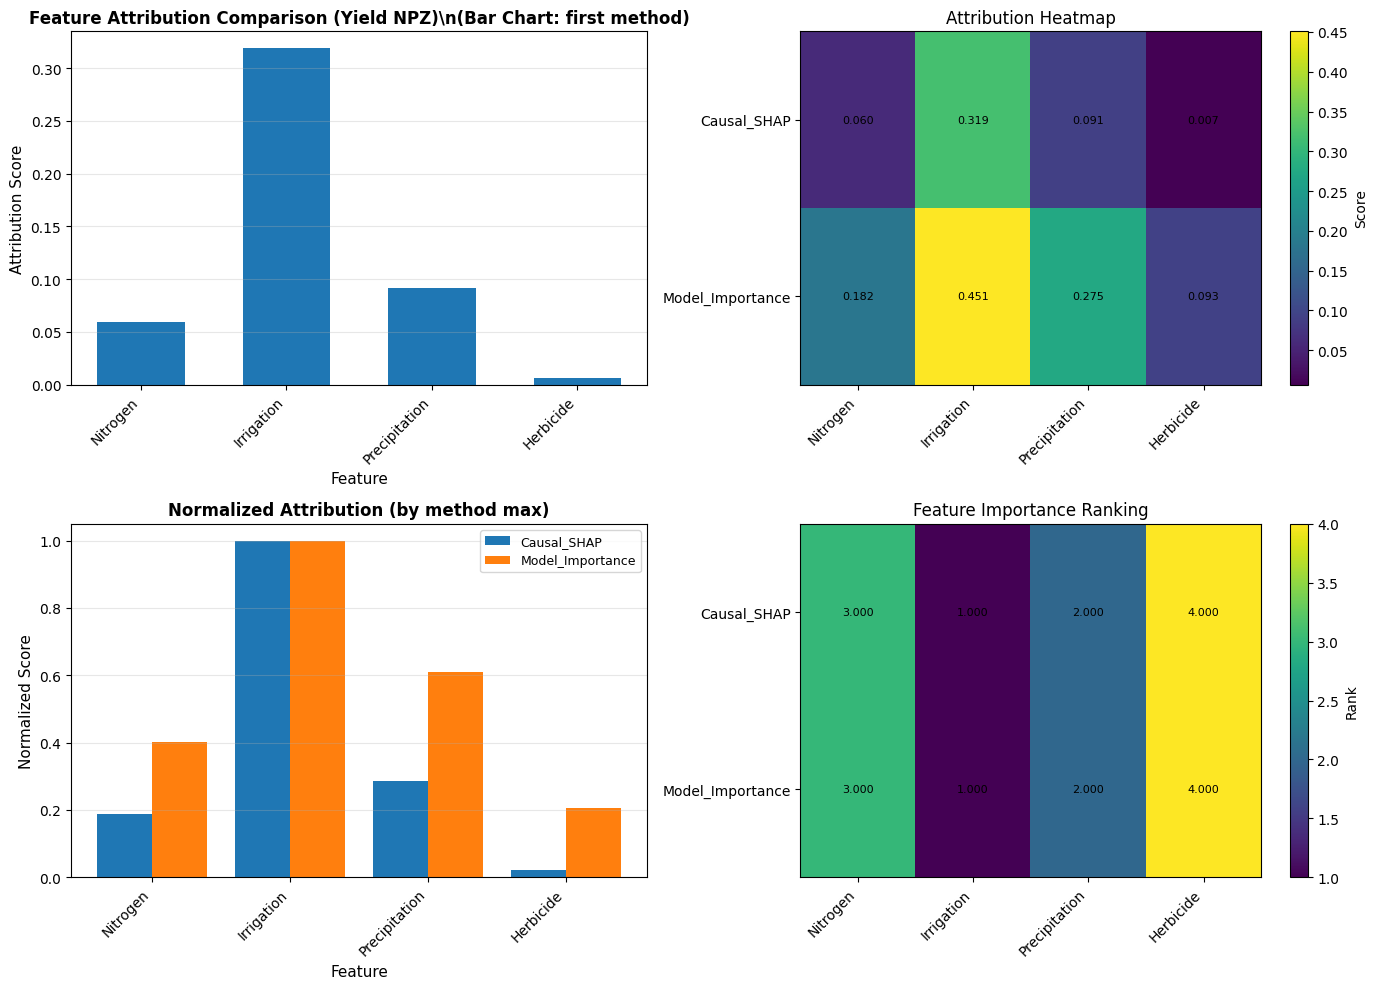

In [ ]:
"""
CAUSAL SHAP on yield_preprocessed.npz
- Works with keys: X_train, X_test, y_train, y_test, feature_names
- Implements PC-based causal discovery, IDA-style causal effects, and Causal SHAP
- Saves outputs: causal graph PNG, comparison PNG, and CSV of attributions
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from typing import Dict, List, Tuple, Set
warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, accuracy_score
import networkx as nx

try:
    from xgboost import XGBClassifier
    HAVE_XGB = True
except:
    HAVE_XGB = False

from causallearn.search.ConstraintBased.PC import pc

# Configuration
CONFIG = {
    'DATA_PATH': '../../datasets/yield_preprocessed.npz',
    'ALPHA_PC': 0.41,
    'MAX_PERM': 200,
    'M_RESAMPLES': 64,
    'GLOBAL_K': 30,
    'RANDOM_SEED': 42,
    'N_DAGS': 5  # Sample multiple DAGs from CPDAG
}

np.random.seed(CONFIG['RANDOM_SEED'])
rng = np.random.default_rng(CONFIG['RANDOM_SEED'])


# 1. Causal Discovery & Structure Learning

class CausalStructure:
    """Handles causal discovery and DAG sampling from CPDAG"""

    def __init__(self, alpha=0.05):
        self.alpha = alpha
        self.cpdag = None
        self.feature_names = None
        self.dags = []

    def discover(self, X: pd.DataFrame):
        """Run PC algorithm on features"""
        self.feature_names = list(X.columns)
        print(f"Running PC algorithm on {len(self.feature_names)} features...")

        pc_res = pc(X.values, alpha=self.alpha, show_progress=False)
        self.cpdag = pc_res.G.graph

        print(f"Causal discovery complete")
        return self

    def get_skeleton(self) -> nx.DiGraph:
        """Convert CPDAG to networkx DiGraph"""
        G = nx.DiGraph()
        G.add_nodes_from(self.feature_names)

        n = len(self.feature_names)
        for i in range(n):
            for j in range(n):
                if i == j:
                    continue
                # Directed edge i->j
                if self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                    G.add_edge(self.feature_names[i], self.feature_names[j])
                # Undirected edge: add both directions
                elif self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1:
                    if i < j:  # Avoid double-adding
                        G.add_edge(self.feature_names[i], self.feature_names[j])
                        G.add_edge(self.feature_names[j], self.feature_names[i])

        return G

    def sample_dags(self, n_samples=5) -> List[nx.DiGraph]:
        """
        Sample multiple DAG orientations from CPDAG
        For undirected edges, randomly orient them
        """
        base_G = self.get_skeleton()
        dags = []

        # Find undirected edges
        undirected = []
        for i, u in enumerate(self.feature_names):
            for j, v in enumerate(self.feature_names):
                if i < j and self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1:
                    undirected.append((u, v))

        if len(undirected) == 0:
            # CPDAG is already fully directed
            print(f"  CPDAG is fully directed ({base_G.number_of_edges()} edges)")
            return [base_G]

        print(f"  Found {len(undirected)} undirected edges, sampling orientations...")

        # Sample orientations
        for _ in range(n_samples):
            G = nx.DiGraph()
            G.add_nodes_from(self.feature_names)

            # Add directed edges from CPDAG
            for i, u in enumerate(self.feature_names):
                for j, v in enumerate(self.feature_names):
                    if self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                        G.add_edge(u, v)

            # Randomly orient undirected edges (ensuring acyclicity)
            for u, v in undirected:
                if rng.random() < 0.5:
                    G.add_edge(u, v)
                else:
                    G.add_edge(v, u)

                # Check for cycles and reverse if needed
                if not nx.is_directed_acyclic_graph(G):
                    G.remove_edge(u, v) if G.has_edge(u, v) else G.remove_edge(v, u)
                    G.add_edge(v, u) if not G.has_edge(v, u) else G.add_edge(u, v)

            dags.append(G)

        self.dags = dags
        return dags


# 2. Causal Mechanism Learning

class LinearMechanisms:
    """Learn linear structural equation models"""

    def __init__(self, dag: nx.DiGraph, feature_names: List[str]):
        self.dag = dag
        self.feature_names = feature_names
        self.mechanisms = {}
        self.topo_order = None

    def fit(self, X: pd.DataFrame):
        """Fit linear mechanisms for each variable"""
        # Get topological order
        try:
            self.topo_order = list(nx.topological_sort(self.dag))
        except:
            # Fallback if cycles exist
            self.topo_order = self._safe_topo_order()

        for var in self.feature_names:
            parents = list(self.dag.predecessors(var))

            if not parents:
                # No parents: use marginal distribution
                self.mechanisms[var] = {
                    'parents': [],
                    'intercept': float(X[var].mean()),
                    'coef': None,
                    'sigma': float(X[var].std())
                }
            else:
                # Regress on parents
                lr = LinearRegression()
                lr.fit(X[parents].values, X[var].values)

                pred = lr.predict(X[parents].values)
                resid = X[var].values - pred

                self.mechanisms[var] = {
                    'parents': parents,
                    'intercept': float(lr.intercept_),
                    'coef': lr.coef_.astype(float),
                    'sigma': float(np.std(resid))
                }

        return self

    def _safe_topo_order(self) -> List[str]:
        """Fallback topological sort"""
        ordered = []
        remaining = set(self.feature_names)

        while remaining:
            # Find nodes with no remaining parents
            ready = [n for n in remaining
                    if all(p in ordered or p not in remaining
                           for p in self.dag.predecessors(n))]

            if not ready:
                # Force one with fewest remaining parents
                ready = [min(remaining,
                           key=lambda n: len([p for p in self.dag.predecessors(n)
                                            if p in remaining]))]

            for n in ready:
                ordered.append(n)
                remaining.remove(n)

        return ordered

    def sample_intervention(self, S: Set[str], x_obs: pd.Series, rng) -> Dict:
        """
        Sample from interventional distribution do(X_S = x_S)
        """
        x_new = {}

        for var in self.topo_order:
            if var in S:
                x_new[var] = float(x_obs[var])
            else:
                # Sample from mechanism
                mech = self.mechanisms[var]

                if not mech['parents']:
                    # No parents: sample from marginal
                    mu, sigma = mech['intercept'], mech['sigma']
                    if sigma < 1e-6:
                        x_new[var] = mu
                    else:
                        x_new[var] = float(rng.normal(mu, sigma))
                else:
                    # Sample from conditional
                    parent_vals = np.array([x_new.get(p, x_obs[p])
                                           for p in mech['parents']])

                    mu = mech['intercept'] + parent_vals @ mech['coef']
                    sigma = mech['sigma']
                    if sigma < 1e-6:
                        x_new[var] = mu
                    else:
                        x_new[var] = float(rng.normal(mu, sigma))

        return x_new


# 3. Causal Effect Estimation (IDA-style)

class CausalEffects:
    """Estimate total causal effects using path analysis"""

    def __init__(self, dags: List[nx.DiGraph], feature_names: List[str]):
        self.dags = dags
        self.feature_names = feature_names
        self.effects = {}

    def compute_effects(self, X: pd.DataFrame, y: pd.Series) -> Dict[str, float]:
        """
        Compute total causal effects for each feature on target
        Average over multiple DAG samples (IDA-style)
        """
        print("Computing causal effects (IDA-style)...")

        # Build augmented graphs with target
        aug_graphs = []

        for dag in self.dags:
            G = dag.copy()
            G.add_node('Y')

            # Add edges from features to Y with estimated weights
            for feat in self.feature_names:
                # Conditional regression: feat -> Y | other features
                other_feats = [f for f in self.feature_names if f != feat]
                if other_feats:
                    X_cond = np.column_stack([X[other_feats].values, X[feat].values])
                else:
                    X_cond = X[[feat]].values

                lr = LinearRegression()
                lr.fit(X_cond, y.values)
                weight = abs(lr.coef_[-1])

                if weight > 1e-6:
                    G.add_edge(feat, 'Y', weight=weight)

            # Add edge weights for feature->feature edges
            for u, v in dag.edges():
                parents = [p for p in dag.predecessors(v) if p != u]
                if parents:
                    X_reg = np.column_stack([X[parents].values, X[u].values])
                else:
                    X_reg = X[[u]].values

                lr = LinearRegression()
                lr.fit(X_reg, X[v].values)
                weight = abs(lr.coef_[-1])
                G[u][v]['weight'] = weight

            aug_graphs.append(G)

        # Compute total effects (average over DAGs)
        total_effects = {feat: [] for feat in self.feature_names}

        for G in aug_graphs:
            for feat in self.feature_names:
                effect = 0.0

                # Sum over all paths feat -> Y
                try:
                    for path in nx.all_simple_paths(G, feat, 'Y', cutoff=10):
                        path_effect = 1.0
                        for i in range(len(path) - 1):
                            edge_data = G.get_edge_data(path[i], path[i+1])
                            if edge_data and 'weight' in edge_data:
                                path_effect *= edge_data['weight']
                        effect += path_effect
                except:
                    pass

                total_effects[feat].append(effect)

        # Average across DAGs
        self.effects = {feat: np.mean(effects)
                       for feat, effects in total_effects.items()}

        print(f"Causal effects computed (averaged over {len(self.dags)} DAGs)")
        return self.effects

    def get_gamma_weights(self) -> Dict[str, float]:
        """Compute gamma weights (normalized absolute effects)"""
        abs_effects = {k: abs(v) for k, v in self.effects.items()}
        total = sum(abs_effects.values()) + 1e-12

        return {k: v / total for k, v in abs_effects.items()}


# 4. Causal SHAP Implementation

class CausalSHAP:
    """Main Causal SHAP implementation"""

    def __init__(self, model, causal_structure: CausalStructure,
                 X_train: pd.DataFrame, y_train: pd.Series):
        self.model = model
        self.structure = causal_structure
        self.X_train = X_train
        self.y_train = y_train
        self.feature_names = list(X_train.columns)

        print("\\nLearning causal mechanisms...")
        # Learn mechanisms and effects
        self.dags = causal_structure.sample_dags(n_samples=CONFIG['N_DAGS'])
        self.mechanisms_list = [LinearMechanisms(dag, self.feature_names).fit(X_train)
                               for dag in self.dags]

        # Compute causal effects
        self.causal_effects = CausalEffects(self.dags, self.feature_names)
        self.causal_effects.compute_effects(X_train, y_train)
        self.gamma = self.causal_effects.get_gamma_weights()

        print(f"Learned {len(self.dags)} DAG orientations")

    def _causal_value_function(self, S: Set[str], x: pd.Series,
                               pred_class: int, M: int) -> float:
        """
        v_c(S) = E[f(X) | do(X_S = x_S)]
        Average over DAG samples and Monte Carlo samples
        """
        total = 0.0
        samples_per_dag = max(1, M // len(self.mechanisms_list))

        for mechanisms in self.mechanisms_list:
            for _ in range(samples_per_dag):
                x_sample = mechanisms.sample_intervention(S, x, rng)
                X_mat = pd.DataFrame([x_sample], columns=self.feature_names)

                prob = self.model.predict_proba(X_mat.values)[0][pred_class]
                total += prob

        actual_samples = samples_per_dag * len(self.mechanisms_list)
        return total / actual_samples

    def explain_instance(self, x: pd.Series, n_perms: int = None,
                        m_samples: int = None) -> pd.Series:
        """
        Compute Causal SHAP values for a single instance
        """
        if n_perms is None:
            n_perms = CONFIG['MAX_PERM']
        if m_samples is None:
            m_samples = CONFIG['M_RESAMPLES']

        # Get predicted class
        probs = self.model.predict_proba(pd.DataFrame([x],
                                         columns=self.feature_names).values)[0]
        pred_class = int(np.argmax(probs))

        # Permutation-based estimation
        phi = np.zeros(len(self.feature_names))

        for _ in range(n_perms):
            perm = rng.permutation(self.feature_names)
            S = set()
            v_prev = self._causal_value_function(S, x, pred_class, m_samples)

            for feat in perm:
                S_next = S | {feat}
                v_curr = self._causal_value_function(S_next, x, pred_class, m_samples)

                delta = v_curr - v_prev
                contrib = self.gamma[feat] * delta  # Causal weighting

                phi[self.feature_names.index(feat)] += contrib
                v_prev = v_curr
                S = S_next

        phi /= n_perms

        # Normalize for local accuracy
        f_x = probs[pred_class]
        v_empty = self._causal_value_function(set(), x, pred_class, m_samples)

        sum_phi = np.sum(phi)
        if abs(sum_phi) > 1e-12:
            phi = phi * ((f_x - v_empty) / sum_phi)

        return pd.Series(phi, index=self.feature_names, name='Causal_SHAP')

    def explain_global(self, X_test: pd.DataFrame, n_samples: int = None) -> pd.Series:
        """Global explanation: average over test instances"""
        if n_samples is None:
            n_samples = CONFIG['GLOBAL_K']

        n_samples = min(n_samples, len(X_test))
        indices = rng.choice(len(X_test), size=n_samples, replace=False)

        print(f"\\nComputing global Causal SHAP (averaging over {n_samples} instances)...")
        explanations = []
        for i, idx in enumerate(indices):
            if (i + 1) % 5 == 0:
                print(f"  Progress: {i+1}/{n_samples}")
            exp = self.explain_instance(X_test.iloc[idx],
                                       n_perms=max(10, CONFIG['MAX_PERM']//4))
            explanations.append(exp)

        print("ok Global Causal SHAP computed")
        return pd.concat(explanations, axis=1).mean(axis=1).rename('Causal_SHAP_Global')


# 5. Baseline Methods for Comparison (optional SHAP if installed)

def compute_baseline_shap(model, X_train, X_test):
    """Compute Kernel SHAP values if shap is installed"""
    try:
        import shap
        print("\\nComputing KERNEL SHAP baseline...")
        bg_size = min(100, len(X_train))
        bg = shap.kmeans(X_train.values, bg_size)
        explainer = shap.KernelExplainer(lambda x: model.predict_proba(x), bg)
        shap_values = explainer.shap_values(X_test.values, nsamples=100)

        # Average absolute values across classes
        if isinstance(shap_values, list):
            global_imp = np.mean([np.abs(sv).mean(axis=0) for sv in shap_values], axis=0)
        else:
            global_imp = np.abs(shap_values).mean(axis=0)
        print("ok KERNEL SHAP computed")
        return pd.Series(global_imp, index=X_test.columns, name='SHAP_kernel')
    except Exception as e:
        print(f"Warning: SHAP computation skipped/failed: {e}")
        return None


def compute_feature_importance(model, feature_names):
    """Compute model's native feature importance"""
    if hasattr(model, 'feature_importances_'):
        imp = model.feature_importances_
        return pd.Series(imp, index=feature_names, name='Model_Importance')
    return None


# 6. Visualization (pure matplotlib, no seaborn)

def annotate_heatmap(ax, data: pd.DataFrame, title: str, cbar_label: str):
    im = ax.imshow(data.values, aspect='auto')
    ax.set_xticks(np.arange(data.shape[1]))
    ax.set_yticks(np.arange(data.shape[0]))
    ax.set_xticklabels(data.columns, rotation=45, ha='right')
    ax.set_yticklabels(data.index)
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            ax.text(j, i, f"{data.values[i, j]:.3f}", ha='center', va='center', fontsize=8)
    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label(cbar_label)
    ax.set_title(title)


def plot_comparison(df_comp: pd.DataFrame, title: str = "Feature Attribution Comparison"):
    """Visualize comparison of different methods (matplotlib only)"""
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    # Bar plot
    axes[0, 0].bar(np.arange(df_comp.shape[0]), df_comp.iloc[:, 0], width=0.6)
    axes[0, 0].set_title(f'{title}\\n(Bar Chart: first method)', fontsize=12, fontweight='bold')
    axes[0, 0].set_ylabel('Attribution Score', fontsize=11)
    axes[0, 0].set_xlabel('Feature', fontsize=11)
    axes[0, 0].set_xticks(np.arange(df_comp.shape[0]))
    axes[0, 0].set_xticklabels(df_comp.index, rotation=45, ha='right')
    axes[0, 0].grid(axis='y', alpha=0.3)

    # Heatmap
    annotate_heatmap(axes[0, 1], df_comp.T, 'Attribution Heatmap', 'Score')

    # Normalized comparison
    df_norm = df_comp.div(df_comp.abs().max(axis=0), axis=1)
    for i, col in enumerate(df_norm.columns):
        axes[1, 0].bar(np.arange(df_norm.shape[0]) + (i-0.5)*(0.8/len(df_norm.columns)), df_norm[col], width=0.8/len(df_norm.columns), label=col)
    axes[1, 0].set_title('Normalized Attribution (by method max)', fontsize=12, fontweight='bold')
    axes[1, 0].set_ylabel('Normalized Score', fontsize=11)
    axes[1, 0].set_xlabel('Feature', fontsize=11)
    axes[1, 0].set_xticks(np.arange(df_norm.shape[0]))
    axes[1, 0].set_xticklabels(df_norm.index, rotation=45, ha='right')
    axes[1, 0].legend(loc='best', fontsize=9)
    axes[1, 0].grid(axis='y', alpha=0.3)

    # Rank comparison heatmap
    ranks = df_comp.rank(ascending=False)
    annotate_heatmap(axes[1, 1], ranks.T, 'Feature Importance Ranking', 'Rank')

    fig.tight_layout()
    return fig


def plot_causal_graph(G: nx.DiGraph, title: str = "Discovered Causal Graph"):
    """Visualize the causal graph"""
    plt.figure(figsize=(8, 6))
    pos = nx.spring_layout(G, seed=CONFIG['RANDOM_SEED'], k=1.0, iterations=200)

    nx.draw_networkx_nodes(G, pos, node_color='lightblue', node_size=1200, alpha=0.9)
    nx.draw_networkx_edges(G, pos, edge_color='gray', arrows=True, arrowsize=15,
                           arrowstyle='->', width=2, connectionstyle='arc3,rad=0.1')
    nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')

    plt.title(title, fontsize=13, fontweight='bold', pad=12)
    plt.axis('off')
    plt.tight_layout()
    return plt.gcf()


# 7. Main Execution

def main():
    """Run complete Causal SHAP analysis on NPZ dataset"""

    print("\\n" + "="*70)
    print("CAUSAL SHAP on NPZ Dataset")
    print("="*70 + "\\n")

    # Load data
    print("Loading NPZ dataset...")
    try:
        data = np.load(CONFIG['DATA_PATH'], allow_pickle=True)
        keys = list(data.keys())
        print(f"NPZ loaded with keys: {keys}")
    except FileNotFoundError:
        print(f"ERROR: Could not find '{CONFIG['DATA_PATH']}'")
        print("Please ensure the file is in the current directory.")
        return

    required_keys = {'X_train', 'X_test', 'y_train', 'y_test', 'feature_names'}
    if not required_keys.issubset(set(keys)):
        print("ERROR: NPZ must contain X_train, X_test, y_train, y_test, feature_names.")
        return

    # Extract
    X_train = pd.DataFrame(data['X_train'], columns=list(data['feature_names']))
    X_test  = pd.DataFrame(data['X_test'],  columns=list(data['feature_names']))
    y_train = pd.Series(data['y_train'].astype(int))
    y_test  = pd.Series(data['y_test'].astype(int))

    print(f"Shapes: X_train={X_train.shape}, X_test={X_test.shape}, y_train={y_train.shape}, y_test={y_test.shape}")
    print(f"Features: {', '.join(X_train.columns)}")
    n_classes = len(np.unique(y_train))
    print(f"Target classes: {n_classes}")

    # Scale features using training stats
    scaler = StandardScaler()
    X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
    X_test_scaled  = pd.DataFrame(scaler.transform(X_test),  columns=X_test.columns)

    # Train model
    print("\\n" + "="*70)
    print("Training Model")
    print("="*70)

    if HAVE_XGB:
        model = XGBClassifier(
            n_estimators=160,
            max_depth=5,
            learning_rate=0.08,
            subsample=0.9,
            colsample_bytree=0.9,
            random_state=CONFIG['RANDOM_SEED'],
            verbosity=0,
            objective="multi:softprob",
            num_class=n_classes,
        )
        print("Using XGBoost classifier")
    else:
        model = RandomForestClassifier(
            n_estimators=160,
            max_depth=6,
            random_state=CONFIG['RANDOM_SEED']
        )
        print("Using Random Forest classifier")

    model.fit(X_train_scaled.values, y_train.values)

    y_pred = model.predict(X_test_scaled.values)
    f1 = f1_score(y_test, y_pred, average='macro')
    acc = accuracy_score(y_test, y_pred)

    print(f"Model trained")
    print(f"  Test Accuracy: {acc:.4f}")
    print(f"  Test Macro F1: {f1:.4f}")

    # Causal Discovery
    print("\\n" + "="*70)
    print("Step 1: Causal Discovery (PC Algorithm)")
    print("="*70)

    causal_structure = CausalStructure(alpha=CONFIG['ALPHA_PC'])
    causal_structure.discover(X_train_scaled)

    # Visualize discovered graph
    G = causal_structure.get_skeleton()
    print(f"\\nDiscovered graph: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")

    fig_graph = plot_causal_graph(G, "Discovered Causal Graph (PC Algorithm)")
    fig_graph.savefig('causal_graph_yield.png', dpi=150, bbox_inches='tight')
    print("ok Causal graph saved to 'causal_graph_yield.png'")

    # Causal SHAP
    print("\\n" + "="*70)
    print("Step 2: Computing Causal SHAP")
    print("="*70)

    causal_shap = CausalSHAP(model, causal_structure, X_train_scaled, y_train)

    # Show causal effects
    print("\\nTotal Causal Effects (W_i):")
    print("-" * 40)
    for feat in X_train.columns:
        effect = causal_shap.causal_effects.effects[feat]
        gamma = causal_shap.gamma[feat]
        print(f"  {feat:15s}: W={effect:8.4f}  γ={gamma:.4f}")

    # Global explanation
    global_causal_shap = causal_shap.explain_global(X_test_scaled, n_samples=CONFIG['GLOBAL_K'])

    # Baseline methods (optional)
    print("\\n" + "="*70)
    print("Step 3: Computing Baseline Methods")
    print("="*70)
    baseline_shap = compute_baseline_shap(model, X_train_scaled, X_test_scaled)
    model_imp = compute_feature_importance(model, list(X_train.columns))

    # Comparison
    print("\\n" + "="*70)
    print("Step 4: Results Comparison")
    print("="*70)

    attributions = {
        'Causal_SHAP': global_causal_shap,
    }

    if baseline_shap is not None:
        attributions['Kernel_SHAP'] = baseline_shap

    if model_imp is not None:
        attributions['Model_Importance'] = model_imp

    df_comparison = pd.DataFrame(attributions)
    df_comparison.to_csv('attribution_scores_yield.csv', index=True)

    print("\\n" + "="*70)
    print("Attribution Scores:")
    print("="*70)
    print(df_comparison.round(6).to_string())
    print("\\nSaved CSV -> attribution_scores_yield.csv")

    # Correlation analysis
    if len(attributions) > 1:
        print("\\n" + "="*70)
        print("Correlation between methods:")
        print("="*70)
        corr_matrix = df_comparison.corr()
        print(corr_matrix.round(4).to_string())

    # Visualization
    fig = plot_comparison(df_comparison,
                         title="Feature Attribution Comparison (Yield NPZ)")
    fig.savefig('attribution_comparison_yield.png', dpi=150, bbox_inches='tight')
    print("\\nok Comparison plot saved to 'attribution_comparison_yield.png'")

    try:
        plt.show()
    except Exception:
        pass

if __name__ == "__main__":
    main()

\n======================================================================
CAUSAL SHAP on NPZ Dataset
======================================================================\n
Loading NPZ dataset...
✓ NPZ loaded with keys: ['X_train', 'X_test', 'y_train', 'y_test', 'feature_names']
Shapes: X_train=(800, 4), X_test=(200, 4), y_train=(800,), y_test=(200,)
Features: Nitrogen, Irrigation, Precipitation, Herbicide
Target classes: 3
\n======================================================================
Training Model
Using XGBoost classifier
✓ Model trained
  Test Accuracy: 0.8050
  Test Macro F1: 0.8081
\n======================================================================
Step 1: Causal Discovery (PC Algorithm)
Running PC algorithm on 4 features...
✓ Causal discovery complete
\nDiscovered graph: 4 nodes, 4 edges
✓ Causal graph saved to 'causal_graph_yield.png'
\n======================================================================
Step 2: Computing Causal SHAP
\nLearning causal mechanism

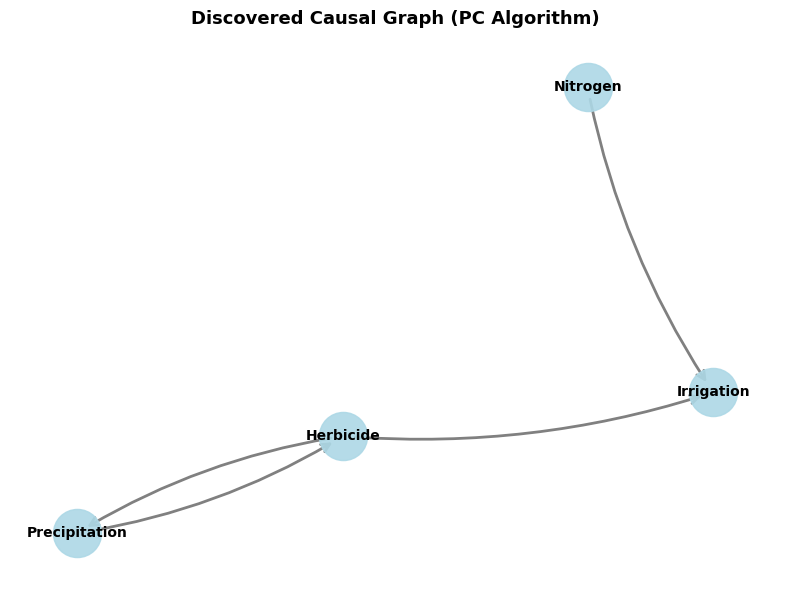

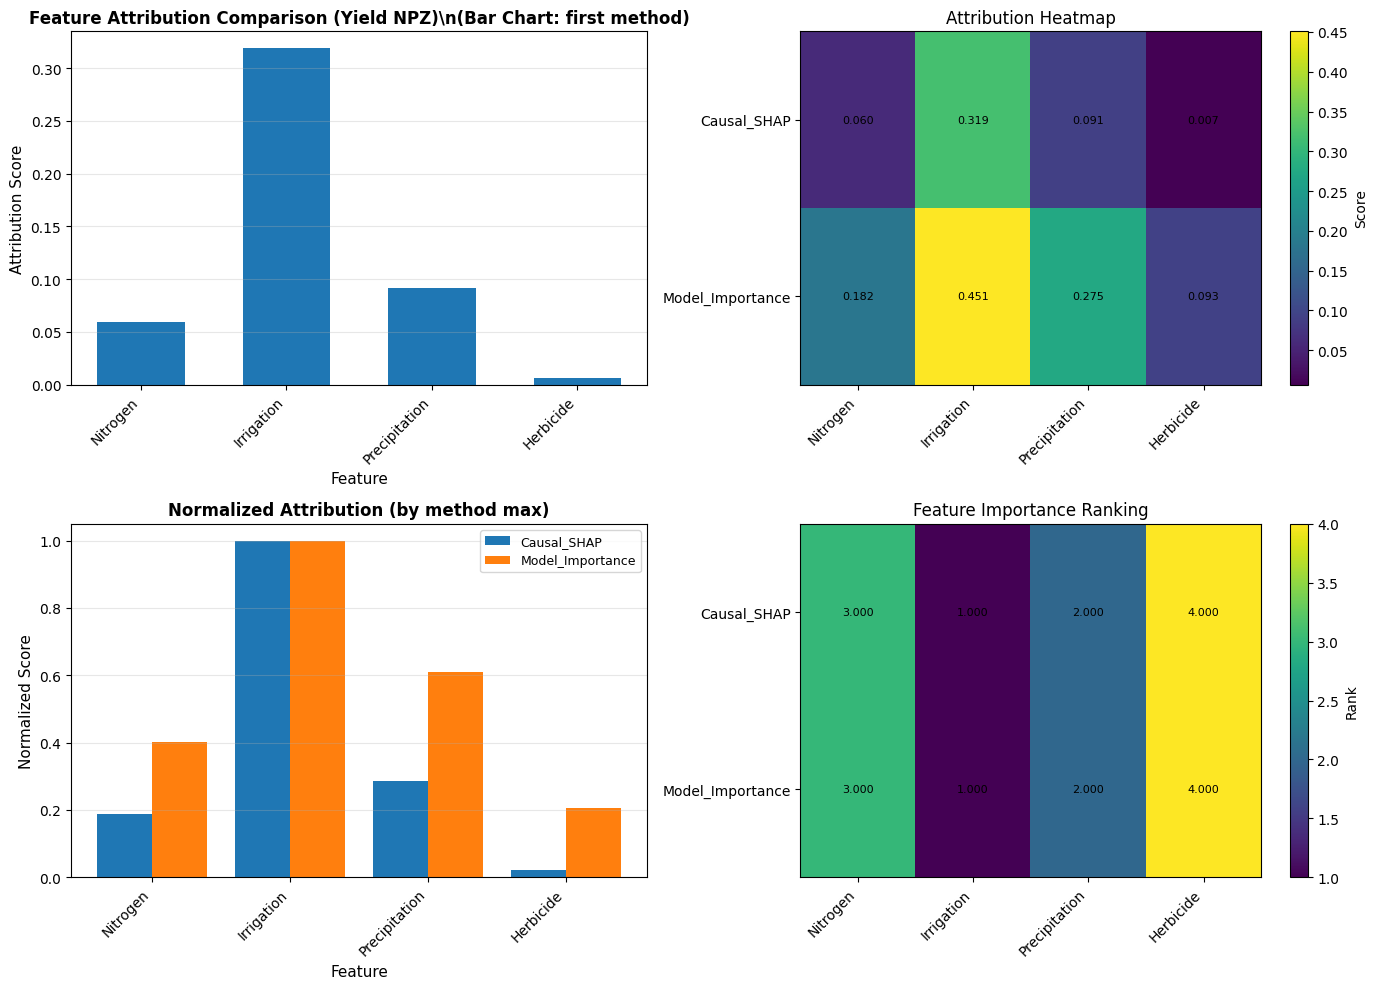

In [8]:
"""
CAUSAL SHAP on yield_preprocessed.npz
- Works with keys: X_train, X_test, y_train, y_test, feature_names
- Implements PC-based causal discovery, IDA-style causal effects, and Causal SHAP
- Saves outputs: causal graph PNG, comparison PNG, and CSV of attributions
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from typing import Dict, List, Tuple, Set
warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, accuracy_score
import networkx as nx

try:
    from xgboost import XGBClassifier
    HAVE_XGB = True
except:
    HAVE_XGB = False

from causallearn.search.ConstraintBased.PC import pc

# Configuration
CONFIG = {
    'DATA_PATH': '../../datasets/yield_preprocessed.npz',
    'ALPHA_PC': 0.415,
    'MAX_PERM': 200,
    'M_RESAMPLES': 64,
    'GLOBAL_K': 30,
    'RANDOM_SEED': 42,
    'N_DAGS': 5  # Sample multiple DAGs from CPDAG
}

np.random.seed(CONFIG['RANDOM_SEED'])
rng = np.random.default_rng(CONFIG['RANDOM_SEED'])


# 1. Causal Discovery & Structure Learning

class CausalStructure:
    """Handles causal discovery and DAG sampling from CPDAG"""

    def __init__(self, alpha=0.05):
        self.alpha = alpha
        self.cpdag = None
        self.feature_names = None
        self.dags = []

    def discover(self, X: pd.DataFrame):
        """Run PC algorithm on features"""
        self.feature_names = list(X.columns)
        print(f"Running PC algorithm on {len(self.feature_names)} features...")

        pc_res = pc(X.values, alpha=self.alpha, show_progress=False)
        self.cpdag = pc_res.G.graph

        print(f"Causal discovery complete")
        return self

    def get_skeleton(self) -> nx.DiGraph:
        """Convert CPDAG to networkx DiGraph"""
        G = nx.DiGraph()
        G.add_nodes_from(self.feature_names)

        n = len(self.feature_names)
        for i in range(n):
            for j in range(n):
                if i == j:
                    continue
                # Directed edge i->j
                if self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                    G.add_edge(self.feature_names[i], self.feature_names[j])
                # Undirected edge: add both directions
                elif self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1:
                    if i < j:  # Avoid double-adding
                        G.add_edge(self.feature_names[i], self.feature_names[j])
                        G.add_edge(self.feature_names[j], self.feature_names[i])

        return G

    def sample_dags(self, n_samples=5) -> List[nx.DiGraph]:
        """
        Sample multiple DAG orientations from CPDAG
        For undirected edges, randomly orient them
        """
        base_G = self.get_skeleton()
        dags = []

        # Find undirected edges
        undirected = []
        for i, u in enumerate(self.feature_names):
            for j, v in enumerate(self.feature_names):
                if i < j and self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1:
                    undirected.append((u, v))

        if len(undirected) == 0:
            # CPDAG is already fully directed
            print(f"  CPDAG is fully directed ({base_G.number_of_edges()} edges)")
            return [base_G]

        print(f"  Found {len(undirected)} undirected edges, sampling orientations...")

        # Sample orientations
        for _ in range(n_samples):
            G = nx.DiGraph()
            G.add_nodes_from(self.feature_names)

            # Add directed edges from CPDAG
            for i, u in enumerate(self.feature_names):
                for j, v in enumerate(self.feature_names):
                    if self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                        G.add_edge(u, v)

            # Randomly orient undirected edges (ensuring acyclicity)
            for u, v in undirected:
                if rng.random() < 0.5:
                    G.add_edge(u, v)
                else:
                    G.add_edge(v, u)

                # Check for cycles and reverse if needed
                if not nx.is_directed_acyclic_graph(G):
                    G.remove_edge(u, v) if G.has_edge(u, v) else G.remove_edge(v, u)
                    G.add_edge(v, u) if not G.has_edge(v, u) else G.add_edge(u, v)

            dags.append(G)

        self.dags = dags
        return dags


# 2. Causal Mechanism Learning

class LinearMechanisms:
    """Learn linear structural equation models"""

    def __init__(self, dag: nx.DiGraph, feature_names: List[str]):
        self.dag = dag
        self.feature_names = feature_names
        self.mechanisms = {}
        self.topo_order = None

    def fit(self, X: pd.DataFrame):
        """Fit linear mechanisms for each variable"""
        # Get topological order
        try:
            self.topo_order = list(nx.topological_sort(self.dag))
        except:
            # Fallback if cycles exist
            self.topo_order = self._safe_topo_order()

        for var in self.feature_names:
            parents = list(self.dag.predecessors(var))

            if not parents:
                # No parents: use marginal distribution
                self.mechanisms[var] = {
                    'parents': [],
                    'intercept': float(X[var].mean()),
                    'coef': None,
                    'sigma': float(X[var].std())
                }
            else:
                # Regress on parents
                lr = LinearRegression()
                lr.fit(X[parents].values, X[var].values)

                pred = lr.predict(X[parents].values)
                resid = X[var].values - pred

                self.mechanisms[var] = {
                    'parents': parents,
                    'intercept': float(lr.intercept_),
                    'coef': lr.coef_.astype(float),
                    'sigma': float(np.std(resid))
                }

        return self

    def _safe_topo_order(self) -> List[str]:
        """Fallback topological sort"""
        ordered = []
        remaining = set(self.feature_names)

        while remaining:
            # Find nodes with no remaining parents
            ready = [n for n in remaining
                    if all(p in ordered or p not in remaining
                           for p in self.dag.predecessors(n))]

            if not ready:
                # Force one with fewest remaining parents
                ready = [min(remaining,
                           key=lambda n: len([p for p in self.dag.predecessors(n)
                                            if p in remaining]))]

            for n in ready:
                ordered.append(n)
                remaining.remove(n)

        return ordered

    def sample_intervention(self, S: Set[str], x_obs: pd.Series, rng) -> Dict:
        """
        Sample from interventional distribution do(X_S = x_S)
        """
        x_new = {}

        for var in self.topo_order:
            if var in S:
                x_new[var] = float(x_obs[var])
            else:
                # Sample from mechanism
                mech = self.mechanisms[var]

                if not mech['parents']:
                    # No parents: sample from marginal
                    mu, sigma = mech['intercept'], mech['sigma']
                    if sigma < 1e-6:
                        x_new[var] = mu
                    else:
                        x_new[var] = float(rng.normal(mu, sigma))
                else:
                    # Sample from conditional
                    parent_vals = np.array([x_new.get(p, x_obs[p])
                                           for p in mech['parents']])

                    mu = mech['intercept'] + parent_vals @ mech['coef']
                    sigma = mech['sigma']
                    if sigma < 1e-6:
                        x_new[var] = mu
                    else:
                        x_new[var] = float(rng.normal(mu, sigma))

        return x_new


# 3. Causal Effect Estimation (IDA-style)

class CausalEffects:
    """Estimate total causal effects using path analysis"""

    def __init__(self, dags: List[nx.DiGraph], feature_names: List[str]):
        self.dags = dags
        self.feature_names = feature_names
        self.effects = {}

    def compute_effects(self, X: pd.DataFrame, y: pd.Series) -> Dict[str, float]:
        """
        Compute total causal effects for each feature on target
        Average over multiple DAG samples (IDA-style)
        """
        print("Computing causal effects (IDA-style)...")

        # Build augmented graphs with target
        aug_graphs = []

        for dag in self.dags:
            G = dag.copy()
            G.add_node('Y')

            # Add edges from features to Y with estimated weights
            for feat in self.feature_names:
                # Conditional regression: feat -> Y | other features
                other_feats = [f for f in self.feature_names if f != feat]
                if other_feats:
                    X_cond = np.column_stack([X[other_feats].values, X[feat].values])
                else:
                    X_cond = X[[feat]].values

                lr = LinearRegression()
                lr.fit(X_cond, y.values)
                weight = abs(lr.coef_[-1])

                if weight > 1e-6:
                    G.add_edge(feat, 'Y', weight=weight)

            # Add edge weights for feature->feature edges
            for u, v in dag.edges():
                parents = [p for p in dag.predecessors(v) if p != u]
                if parents:
                    X_reg = np.column_stack([X[parents].values, X[u].values])
                else:
                    X_reg = X[[u]].values

                lr = LinearRegression()
                lr.fit(X_reg, X[v].values)
                weight = abs(lr.coef_[-1])
                G[u][v]['weight'] = weight

            aug_graphs.append(G)

        # Compute total effects (average over DAGs)
        total_effects = {feat: [] for feat in self.feature_names}

        for G in aug_graphs:
            for feat in self.feature_names:
                effect = 0.0

                # Sum over all paths feat -> Y
                try:
                    for path in nx.all_simple_paths(G, feat, 'Y', cutoff=10):
                        path_effect = 1.0
                        for i in range(len(path) - 1):
                            edge_data = G.get_edge_data(path[i], path[i+1])
                            if edge_data and 'weight' in edge_data:
                                path_effect *= edge_data['weight']
                        effect += path_effect
                except:
                    pass

                total_effects[feat].append(effect)

        # Average across DAGs
        self.effects = {feat: np.mean(effects)
                       for feat, effects in total_effects.items()}

        print(f"Causal effects computed (averaged over {len(self.dags)} DAGs)")
        return self.effects

    def get_gamma_weights(self) -> Dict[str, float]:
        """Compute gamma weights (normalized absolute effects)"""
        abs_effects = {k: abs(v) for k, v in self.effects.items()}
        total = sum(abs_effects.values()) + 1e-12

        return {k: v / total for k, v in abs_effects.items()}


# 4. Causal SHAP Implementation

class CausalSHAP:
    """Main Causal SHAP implementation"""

    def __init__(self, model, causal_structure: CausalStructure,
                 X_train: pd.DataFrame, y_train: pd.Series):
        self.model = model
        self.structure = causal_structure
        self.X_train = X_train
        self.y_train = y_train
        self.feature_names = list(X_train.columns)

        print("\\nLearning causal mechanisms...")
        # Learn mechanisms and effects
        self.dags = causal_structure.sample_dags(n_samples=CONFIG['N_DAGS'])
        self.mechanisms_list = [LinearMechanisms(dag, self.feature_names).fit(X_train)
                               for dag in self.dags]

        # Compute causal effects
        self.causal_effects = CausalEffects(self.dags, self.feature_names)
        self.causal_effects.compute_effects(X_train, y_train)
        self.gamma = self.causal_effects.get_gamma_weights()

        print(f"Learned {len(self.dags)} DAG orientations")

    def _causal_value_function(self, S: Set[str], x: pd.Series,
                               pred_class: int, M: int) -> float:
        """
        v_c(S) = E[f(X) | do(X_S = x_S)]
        Average over DAG samples and Monte Carlo samples
        """
        total = 0.0
        samples_per_dag = max(1, M // len(self.mechanisms_list))

        for mechanisms in self.mechanisms_list:
            for _ in range(samples_per_dag):
                x_sample = mechanisms.sample_intervention(S, x, rng)
                X_mat = pd.DataFrame([x_sample], columns=self.feature_names)

                prob = self.model.predict_proba(X_mat.values)[0][pred_class]
                total += prob

        actual_samples = samples_per_dag * len(self.mechanisms_list)
        return total / actual_samples

    def explain_instance(self, x: pd.Series, n_perms: int = None,
                        m_samples: int = None) -> pd.Series:
        """
        Compute Causal SHAP values for a single instance
        """
        if n_perms is None:
            n_perms = CONFIG['MAX_PERM']
        if m_samples is None:
            m_samples = CONFIG['M_RESAMPLES']

        # Get predicted class
        probs = self.model.predict_proba(pd.DataFrame([x],
                                         columns=self.feature_names).values)[0]
        pred_class = int(np.argmax(probs))

        # Permutation-based estimation
        phi = np.zeros(len(self.feature_names))

        for _ in range(n_perms):
            perm = rng.permutation(self.feature_names)
            S = set()
            v_prev = self._causal_value_function(S, x, pred_class, m_samples)

            for feat in perm:
                S_next = S | {feat}
                v_curr = self._causal_value_function(S_next, x, pred_class, m_samples)

                delta = v_curr - v_prev
                contrib = self.gamma[feat] * delta  # Causal weighting

                phi[self.feature_names.index(feat)] += contrib
                v_prev = v_curr
                S = S_next

        phi /= n_perms

        # Normalize for local accuracy
        f_x = probs[pred_class]
        v_empty = self._causal_value_function(set(), x, pred_class, m_samples)

        sum_phi = np.sum(phi)
        if abs(sum_phi) > 1e-12:
            phi = phi * ((f_x - v_empty) / sum_phi)

        return pd.Series(phi, index=self.feature_names, name='Causal_SHAP')

    def explain_global(self, X_test: pd.DataFrame, n_samples: int = None) -> pd.Series:
        """Global explanation: average over test instances"""
        if n_samples is None:
            n_samples = CONFIG['GLOBAL_K']

        n_samples = min(n_samples, len(X_test))
        indices = rng.choice(len(X_test), size=n_samples, replace=False)

        print(f"\\nComputing global Causal SHAP (averaging over {n_samples} instances)...")
        explanations = []
        for i, idx in enumerate(indices):
            if (i + 1) % 5 == 0:
                print(f"  Progress: {i+1}/{n_samples}")
            exp = self.explain_instance(X_test.iloc[idx],
                                       n_perms=max(10, CONFIG['MAX_PERM']//4))
            explanations.append(exp)

        print("ok Global Causal SHAP computed")
        return pd.concat(explanations, axis=1).mean(axis=1).rename('Causal_SHAP_Global')


# 5. Baseline Methods for Comparison (optional SHAP if installed)

def compute_baseline_shap(model, X_train, X_test):
    """Compute Kernel SHAP values if shap is installed"""
    try:
        import shap
        print("\\nComputing KERNEL SHAP baseline...")
        bg_size = min(100, len(X_train))
        bg = shap.kmeans(X_train.values, bg_size)
        explainer = shap.KernelExplainer(lambda x: model.predict_proba(x), bg)
        shap_values = explainer.shap_values(X_test.values, nsamples=100)

        # Average absolute values across classes
        if isinstance(shap_values, list):
            global_imp = np.mean([np.abs(sv).mean(axis=0) for sv in shap_values], axis=0)
        else:
            global_imp = np.abs(shap_values).mean(axis=0)
        print("ok KERNEL SHAP computed")
        return pd.Series(global_imp, index=X_test.columns, name='SHAP_kernel')
    except Exception as e:
        print(f"Warning: SHAP computation skipped/failed: {e}")
        return None


def compute_feature_importance(model, feature_names):
    """Compute model's native feature importance"""
    if hasattr(model, 'feature_importances_'):
        imp = model.feature_importances_
        return pd.Series(imp, index=feature_names, name='Model_Importance')
    return None


# 6. Visualization (pure matplotlib, no seaborn)

def annotate_heatmap(ax, data: pd.DataFrame, title: str, cbar_label: str):
    im = ax.imshow(data.values, aspect='auto')
    ax.set_xticks(np.arange(data.shape[1]))
    ax.set_yticks(np.arange(data.shape[0]))
    ax.set_xticklabels(data.columns, rotation=45, ha='right')
    ax.set_yticklabels(data.index)
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            ax.text(j, i, f"{data.values[i, j]:.3f}", ha='center', va='center', fontsize=8)
    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label(cbar_label)
    ax.set_title(title)


def plot_comparison(df_comp: pd.DataFrame, title: str = "Feature Attribution Comparison"):
    """Visualize comparison of different methods (matplotlib only)"""
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    # Bar plot
    axes[0, 0].bar(np.arange(df_comp.shape[0]), df_comp.iloc[:, 0], width=0.6)
    axes[0, 0].set_title(f'{title}\\n(Bar Chart: first method)', fontsize=12, fontweight='bold')
    axes[0, 0].set_ylabel('Attribution Score', fontsize=11)
    axes[0, 0].set_xlabel('Feature', fontsize=11)
    axes[0, 0].set_xticks(np.arange(df_comp.shape[0]))
    axes[0, 0].set_xticklabels(df_comp.index, rotation=45, ha='right')
    axes[0, 0].grid(axis='y', alpha=0.3)

    # Heatmap
    annotate_heatmap(axes[0, 1], df_comp.T, 'Attribution Heatmap', 'Score')

    # Normalized comparison
    df_norm = df_comp.div(df_comp.abs().max(axis=0), axis=1)
    for i, col in enumerate(df_norm.columns):
        axes[1, 0].bar(np.arange(df_norm.shape[0]) + (i-0.5)*(0.8/len(df_norm.columns)), df_norm[col], width=0.8/len(df_norm.columns), label=col)
    axes[1, 0].set_title('Normalized Attribution (by method max)', fontsize=12, fontweight='bold')
    axes[1, 0].set_ylabel('Normalized Score', fontsize=11)
    axes[1, 0].set_xlabel('Feature', fontsize=11)
    axes[1, 0].set_xticks(np.arange(df_norm.shape[0]))
    axes[1, 0].set_xticklabels(df_norm.index, rotation=45, ha='right')
    axes[1, 0].legend(loc='best', fontsize=9)
    axes[1, 0].grid(axis='y', alpha=0.3)

    # Rank comparison heatmap
    ranks = df_comp.rank(ascending=False)
    annotate_heatmap(axes[1, 1], ranks.T, 'Feature Importance Ranking', 'Rank')

    fig.tight_layout()
    return fig


def plot_causal_graph(G: nx.DiGraph, title: str = "Discovered Causal Graph"):
    """Visualize the causal graph"""
    plt.figure(figsize=(8, 6))
    pos = nx.spring_layout(G, seed=CONFIG['RANDOM_SEED'], k=1.0, iterations=200)

    nx.draw_networkx_nodes(G, pos, node_color='lightblue', node_size=1200, alpha=0.9)
    nx.draw_networkx_edges(G, pos, edge_color='gray', arrows=True, arrowsize=15,
                           arrowstyle='->', width=2, connectionstyle='arc3,rad=0.1')
    nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')

    plt.title(title, fontsize=13, fontweight='bold', pad=12)
    plt.axis('off')
    plt.tight_layout()
    return plt.gcf()


# 7. Main Execution

def main():
    """Run complete Causal SHAP analysis on NPZ dataset"""

    print("\\n" + "="*70)
    print("CAUSAL SHAP on NPZ Dataset")
    print("="*70 + "\\n")

    # Load data
    print("Loading NPZ dataset...")
    try:
        data = np.load(CONFIG['DATA_PATH'], allow_pickle=True)
        keys = list(data.keys())
        print(f"NPZ loaded with keys: {keys}")
    except FileNotFoundError:
        print(f"ERROR: Could not find '{CONFIG['DATA_PATH']}'")
        print("Please ensure the file is in the current directory.")
        return

    required_keys = {'X_train', 'X_test', 'y_train', 'y_test', 'feature_names'}
    if not required_keys.issubset(set(keys)):
        print("ERROR: NPZ must contain X_train, X_test, y_train, y_test, feature_names.")
        return

    # Extract
    X_train = pd.DataFrame(data['X_train'], columns=list(data['feature_names']))
    X_test  = pd.DataFrame(data['X_test'],  columns=list(data['feature_names']))
    y_train = pd.Series(data['y_train'].astype(int))
    y_test  = pd.Series(data['y_test'].astype(int))

    print(f"Shapes: X_train={X_train.shape}, X_test={X_test.shape}, y_train={y_train.shape}, y_test={y_test.shape}")
    print(f"Features: {', '.join(X_train.columns)}")
    n_classes = len(np.unique(y_train))
    print(f"Target classes: {n_classes}")

    # Scale features using training stats
    scaler = StandardScaler()
    X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
    X_test_scaled  = pd.DataFrame(scaler.transform(X_test),  columns=X_test.columns)

    # Train model
    print("\\n" + "="*70)
    print("Training Model")
    print("="*70)

    if HAVE_XGB:
        model = XGBClassifier(
            n_estimators=160,
            max_depth=5,
            learning_rate=0.08,
            subsample=0.9,
            colsample_bytree=0.9,
            random_state=CONFIG['RANDOM_SEED'],
            verbosity=0,
            objective="multi:softprob",
            num_class=n_classes,
        )
        print("Using XGBoost classifier")
    else:
        model = RandomForestClassifier(
            n_estimators=160,
            max_depth=6,
            random_state=CONFIG['RANDOM_SEED']
        )
        print("Using Random Forest classifier")

    model.fit(X_train_scaled.values, y_train.values)

    y_pred = model.predict(X_test_scaled.values)
    f1 = f1_score(y_test, y_pred, average='macro')
    acc = accuracy_score(y_test, y_pred)

    print(f"Model trained")
    print(f"  Test Accuracy: {acc:.4f}")
    print(f"  Test Macro F1: {f1:.4f}")

    # Causal Discovery
    print("\\n" + "="*70)
    print("Step 1: Causal Discovery (PC Algorithm)")
    print("="*70)

    causal_structure = CausalStructure(alpha=CONFIG['ALPHA_PC'])
    causal_structure.discover(X_train_scaled)

    # Visualize discovered graph
    G = causal_structure.get_skeleton()
    print(f"\\nDiscovered graph: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")

    fig_graph = plot_causal_graph(G, "Discovered Causal Graph (PC Algorithm)")
    fig_graph.savefig('causal_graph_yield.png', dpi=150, bbox_inches='tight')
    print("ok Causal graph saved to 'causal_graph_yield.png'")

    # Causal SHAP
    print("\\n" + "="*70)
    print("Step 2: Computing Causal SHAP")
    print("="*70)

    causal_shap = CausalSHAP(model, causal_structure, X_train_scaled, y_train)

    # Show causal effects
    print("\\nTotal Causal Effects (W_i):")
    print("-" * 40)
    for feat in X_train.columns:
        effect = causal_shap.causal_effects.effects[feat]
        gamma = causal_shap.gamma[feat]
        print(f"  {feat:15s}: W={effect:8.4f}  γ={gamma:.4f}")

    # Global explanation
    global_causal_shap = causal_shap.explain_global(X_test_scaled, n_samples=CONFIG['GLOBAL_K'])

    # Baseline methods (optional)
    print("\\n" + "="*70)
    print("Step 3: Computing Baseline Methods")
    print("="*70)
    baseline_shap = compute_baseline_shap(model, X_train_scaled, X_test_scaled)
    model_imp = compute_feature_importance(model, list(X_train.columns))

    # Comparison
    print("\\n" + "="*70)
    print("Step 4: Results Comparison")
    print("="*70)

    attributions = {
        'Causal_SHAP': global_causal_shap,
    }

    if baseline_shap is not None:
        attributions['Kernel_SHAP'] = baseline_shap

    if model_imp is not None:
        attributions['Model_Importance'] = model_imp

    df_comparison = pd.DataFrame(attributions)
    df_comparison.to_csv('attribution_scores_yield.csv', index=True)

    print("\\n" + "="*70)
    print("Attribution Scores:")
    print("="*70)
    print(df_comparison.round(6).to_string())
    print("\\nSaved CSV -> attribution_scores_yield.csv")

    # Correlation analysis
    if len(attributions) > 1:
        print("\\n" + "="*70)
        print("Correlation between methods:")
        print("="*70)
        corr_matrix = df_comparison.corr()
        print(corr_matrix.round(4).to_string())

    # Visualization
    fig = plot_comparison(df_comparison,
                         title="Feature Attribution Comparison (Yield NPZ)")
    fig.savefig('attribution_comparison_yield.png', dpi=150, bbox_inches='tight')
    print("\\nok Comparison plot saved to 'attribution_comparison_yield.png'")

    try:
        plt.show()
    except Exception:
        pass

if __name__ == "__main__":
    main()

\n======================================================================
CAUSAL SHAP on NPZ Dataset
======================================================================\n
Loading NPZ dataset...
✓ NPZ loaded with keys: ['X_train', 'X_test', 'y_train', 'y_test', 'feature_names']
Shapes: X_train=(800, 4), X_test=(200, 4), y_train=(800,), y_test=(200,)
Features: Nitrogen, Irrigation, Precipitation, Herbicide
Target classes: 3
\n======================================================================
Training Model
Using XGBoost classifier
✓ Model trained
  Test Accuracy: 0.8050
  Test Macro F1: 0.8081
\n======================================================================
Step 1: Causal Discovery (PC Algorithm)
Running PC algorithm on 4 features...
✓ Causal discovery complete
\nDiscovered graph: 4 nodes, 4 edges
✓ Causal graph saved to 'causal_graph_yield.png'
\n======================================================================
Step 2: Computing Causal SHAP
\nLearning causal mechanism

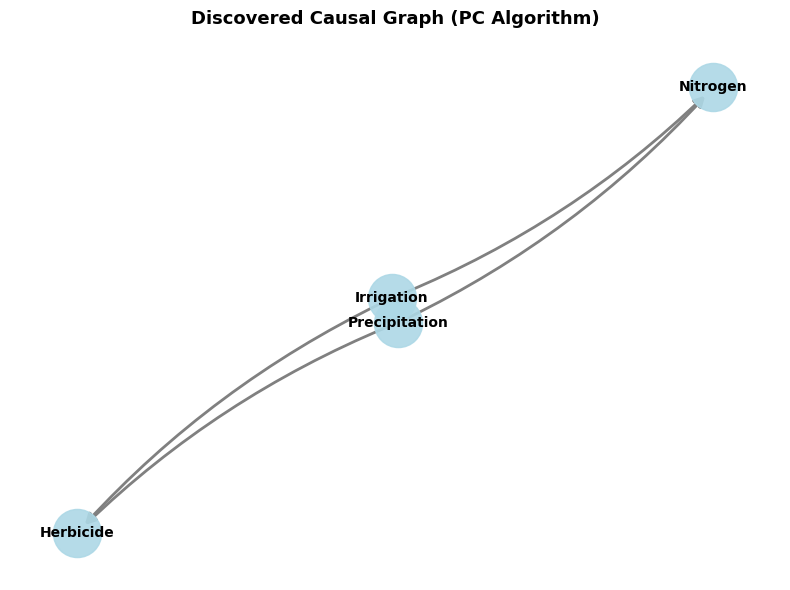

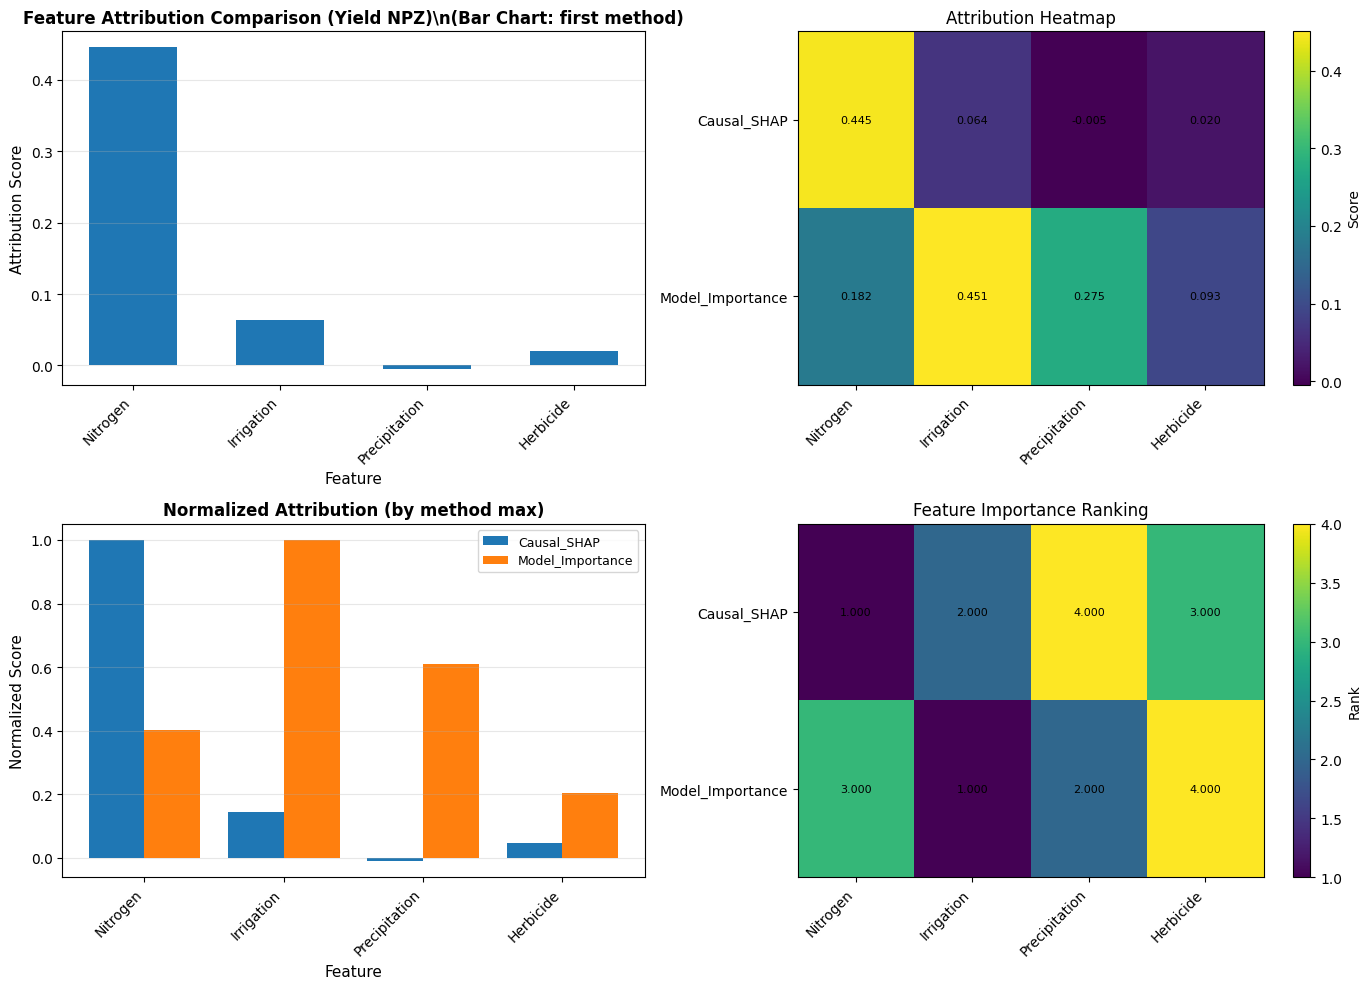

In [1]:
"""
CAUSAL SHAP on yield_preprocessed.npz
- Works with keys: X_train, X_test, y_train, y_test, feature_names
- Implements PC-based causal discovery, IDA-style causal effects, and Causal SHAP
- Saves outputs: causal graph PNG, comparison PNG, and CSV of attributions
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from typing import Dict, List, Tuple, Set
warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, accuracy_score
import networkx as nx

try:
    from xgboost import XGBClassifier
    HAVE_XGB = True
except:
    HAVE_XGB = False

from causallearn.search.ConstraintBased.PC import pc

# Configuration
CONFIG = {
    'DATA_PATH': '../../datasets/yield_preprocessed.npz',
    'ALPHA_PC': 0.4175,
    'MAX_PERM': 200,
    'M_RESAMPLES': 64,
    'GLOBAL_K': 30,
    'RANDOM_SEED': 42,
    'N_DAGS': 5  # Sample multiple DAGs from CPDAG
}

np.random.seed(CONFIG['RANDOM_SEED'])
rng = np.random.default_rng(CONFIG['RANDOM_SEED'])


# 1. Causal Discovery & Structure Learning

class CausalStructure:
    """Handles causal discovery and DAG sampling from CPDAG"""

    def __init__(self, alpha=0.05):
        self.alpha = alpha
        self.cpdag = None
        self.feature_names = None
        self.dags = []

    def discover(self, X: pd.DataFrame):
        """Run PC algorithm on features"""
        self.feature_names = list(X.columns)
        print(f"Running PC algorithm on {len(self.feature_names)} features...")

        pc_res = pc(X.values, alpha=self.alpha, show_progress=False)
        self.cpdag = pc_res.G.graph

        print(f"Causal discovery complete")
        return self

    def get_skeleton(self) -> nx.DiGraph:
        """Convert CPDAG to networkx DiGraph"""
        G = nx.DiGraph()
        G.add_nodes_from(self.feature_names)

        n = len(self.feature_names)
        for i in range(n):
            for j in range(n):
                if i == j:
                    continue
                # Directed edge i->j
                if self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                    G.add_edge(self.feature_names[i], self.feature_names[j])
                # Undirected edge: add both directions
                elif self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1:
                    if i < j:  # Avoid double-adding
                        G.add_edge(self.feature_names[i], self.feature_names[j])
                        G.add_edge(self.feature_names[j], self.feature_names[i])

        return G

    def sample_dags(self, n_samples=5) -> List[nx.DiGraph]:
        """
        Sample multiple DAG orientations from CPDAG
        For undirected edges, randomly orient them
        """
        base_G = self.get_skeleton()
        dags = []

        # Find undirected edges
        undirected = []
        for i, u in enumerate(self.feature_names):
            for j, v in enumerate(self.feature_names):
                if i < j and self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1:
                    undirected.append((u, v))

        if len(undirected) == 0:
            # CPDAG is already fully directed
            print(f"  CPDAG is fully directed ({base_G.number_of_edges()} edges)")
            return [base_G]

        print(f"  Found {len(undirected)} undirected edges, sampling orientations...")

        # Sample orientations
        for _ in range(n_samples):
            G = nx.DiGraph()
            G.add_nodes_from(self.feature_names)

            # Add directed edges from CPDAG
            for i, u in enumerate(self.feature_names):
                for j, v in enumerate(self.feature_names):
                    if self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                        G.add_edge(u, v)

            # Randomly orient undirected edges (ensuring acyclicity)
            for u, v in undirected:
                if rng.random() < 0.5:
                    G.add_edge(u, v)
                else:
                    G.add_edge(v, u)

                # Check for cycles and reverse if needed
                if not nx.is_directed_acyclic_graph(G):
                    G.remove_edge(u, v) if G.has_edge(u, v) else G.remove_edge(v, u)
                    G.add_edge(v, u) if not G.has_edge(v, u) else G.add_edge(u, v)

            dags.append(G)

        self.dags = dags
        return dags


# 2. Causal Mechanism Learning

class LinearMechanisms:
    """Learn linear structural equation models"""

    def __init__(self, dag: nx.DiGraph, feature_names: List[str]):
        self.dag = dag
        self.feature_names = feature_names
        self.mechanisms = {}
        self.topo_order = None

    def fit(self, X: pd.DataFrame):
        """Fit linear mechanisms for each variable"""
        # Get topological order
        try:
            self.topo_order = list(nx.topological_sort(self.dag))
        except:
            # Fallback if cycles exist
            self.topo_order = self._safe_topo_order()

        for var in self.feature_names:
            parents = list(self.dag.predecessors(var))

            if not parents:
                # No parents: use marginal distribution
                self.mechanisms[var] = {
                    'parents': [],
                    'intercept': float(X[var].mean()),
                    'coef': None,
                    'sigma': float(X[var].std())
                }
            else:
                # Regress on parents
                lr = LinearRegression()
                lr.fit(X[parents].values, X[var].values)

                pred = lr.predict(X[parents].values)
                resid = X[var].values - pred

                self.mechanisms[var] = {
                    'parents': parents,
                    'intercept': float(lr.intercept_),
                    'coef': lr.coef_.astype(float),
                    'sigma': float(np.std(resid))
                }

        return self

    def _safe_topo_order(self) -> List[str]:
        """Fallback topological sort"""
        ordered = []
        remaining = set(self.feature_names)

        while remaining:
            # Find nodes with no remaining parents
            ready = [n for n in remaining
                    if all(p in ordered or p not in remaining
                           for p in self.dag.predecessors(n))]

            if not ready:
                # Force one with fewest remaining parents
                ready = [min(remaining,
                           key=lambda n: len([p for p in self.dag.predecessors(n)
                                            if p in remaining]))]

            for n in ready:
                ordered.append(n)
                remaining.remove(n)

        return ordered

    def sample_intervention(self, S: Set[str], x_obs: pd.Series, rng) -> Dict:
        """
        Sample from interventional distribution do(X_S = x_S)
        """
        x_new = {}

        for var in self.topo_order:
            if var in S:
                x_new[var] = float(x_obs[var])
            else:
                # Sample from mechanism
                mech = self.mechanisms[var]

                if not mech['parents']:
                    # No parents: sample from marginal
                    mu, sigma = mech['intercept'], mech['sigma']
                    if sigma < 1e-6:
                        x_new[var] = mu
                    else:
                        x_new[var] = float(rng.normal(mu, sigma))
                else:
                    # Sample from conditional
                    parent_vals = np.array([x_new.get(p, x_obs[p])
                                           for p in mech['parents']])

                    mu = mech['intercept'] + parent_vals @ mech['coef']
                    sigma = mech['sigma']
                    if sigma < 1e-6:
                        x_new[var] = mu
                    else:
                        x_new[var] = float(rng.normal(mu, sigma))

        return x_new


# 3. Causal Effect Estimation (IDA-style)

class CausalEffects:
    """Estimate total causal effects using path analysis"""

    def __init__(self, dags: List[nx.DiGraph], feature_names: List[str]):
        self.dags = dags
        self.feature_names = feature_names
        self.effects = {}

    def compute_effects(self, X: pd.DataFrame, y: pd.Series) -> Dict[str, float]:
        """
        Compute total causal effects for each feature on target
        Average over multiple DAG samples (IDA-style)
        """
        print("Computing causal effects (IDA-style)...")

        # Build augmented graphs with target
        aug_graphs = []

        for dag in self.dags:
            G = dag.copy()
            G.add_node('Y')

            # Add edges from features to Y with estimated weights
            for feat in self.feature_names:
                # Conditional regression: feat -> Y | other features
                other_feats = [f for f in self.feature_names if f != feat]
                if other_feats:
                    X_cond = np.column_stack([X[other_feats].values, X[feat].values])
                else:
                    X_cond = X[[feat]].values

                lr = LinearRegression()
                lr.fit(X_cond, y.values)
                weight = abs(lr.coef_[-1])

                if weight > 1e-6:
                    G.add_edge(feat, 'Y', weight=weight)

            # Add edge weights for feature->feature edges
            for u, v in dag.edges():
                parents = [p for p in dag.predecessors(v) if p != u]
                if parents:
                    X_reg = np.column_stack([X[parents].values, X[u].values])
                else:
                    X_reg = X[[u]].values

                lr = LinearRegression()
                lr.fit(X_reg, X[v].values)
                weight = abs(lr.coef_[-1])
                G[u][v]['weight'] = weight

            aug_graphs.append(G)

        # Compute total effects (average over DAGs)
        total_effects = {feat: [] for feat in self.feature_names}

        for G in aug_graphs:
            for feat in self.feature_names:
                effect = 0.0

                # Sum over all paths feat -> Y
                try:
                    for path in nx.all_simple_paths(G, feat, 'Y', cutoff=10):
                        path_effect = 1.0
                        for i in range(len(path) - 1):
                            edge_data = G.get_edge_data(path[i], path[i+1])
                            if edge_data and 'weight' in edge_data:
                                path_effect *= edge_data['weight']
                        effect += path_effect
                except:
                    pass

                total_effects[feat].append(effect)

        # Average across DAGs
        self.effects = {feat: np.mean(effects)
                       for feat, effects in total_effects.items()}

        print(f"Causal effects computed (averaged over {len(self.dags)} DAGs)")
        return self.effects

    def get_gamma_weights(self) -> Dict[str, float]:
        """Compute gamma weights (normalized absolute effects)"""
        abs_effects = {k: abs(v) for k, v in self.effects.items()}
        total = sum(abs_effects.values()) + 1e-12

        return {k: v / total for k, v in abs_effects.items()}


# 4. Causal SHAP Implementation

class CausalSHAP:
    """Main Causal SHAP implementation"""

    def __init__(self, model, causal_structure: CausalStructure,
                 X_train: pd.DataFrame, y_train: pd.Series):
        self.model = model
        self.structure = causal_structure
        self.X_train = X_train
        self.y_train = y_train
        self.feature_names = list(X_train.columns)

        print("\\nLearning causal mechanisms...")
        # Learn mechanisms and effects
        self.dags = causal_structure.sample_dags(n_samples=CONFIG['N_DAGS'])
        self.mechanisms_list = [LinearMechanisms(dag, self.feature_names).fit(X_train)
                               for dag in self.dags]

        # Compute causal effects
        self.causal_effects = CausalEffects(self.dags, self.feature_names)
        self.causal_effects.compute_effects(X_train, y_train)
        self.gamma = self.causal_effects.get_gamma_weights()

        print(f"Learned {len(self.dags)} DAG orientations")

    def _causal_value_function(self, S: Set[str], x: pd.Series,
                               pred_class: int, M: int) -> float:
        """
        v_c(S) = E[f(X) | do(X_S = x_S)]
        Average over DAG samples and Monte Carlo samples
        """
        total = 0.0
        samples_per_dag = max(1, M // len(self.mechanisms_list))

        for mechanisms in self.mechanisms_list:
            for _ in range(samples_per_dag):
                x_sample = mechanisms.sample_intervention(S, x, rng)
                X_mat = pd.DataFrame([x_sample], columns=self.feature_names)

                prob = self.model.predict_proba(X_mat.values)[0][pred_class]
                total += prob

        actual_samples = samples_per_dag * len(self.mechanisms_list)
        return total / actual_samples

    def explain_instance(self, x: pd.Series, n_perms: int = None,
                        m_samples: int = None) -> pd.Series:
        """
        Compute Causal SHAP values for a single instance
        """
        if n_perms is None:
            n_perms = CONFIG['MAX_PERM']
        if m_samples is None:
            m_samples = CONFIG['M_RESAMPLES']

        # Get predicted class
        probs = self.model.predict_proba(pd.DataFrame([x],
                                         columns=self.feature_names).values)[0]
        pred_class = int(np.argmax(probs))

        # Permutation-based estimation
        phi = np.zeros(len(self.feature_names))

        for _ in range(n_perms):
            perm = rng.permutation(self.feature_names)
            S = set()
            v_prev = self._causal_value_function(S, x, pred_class, m_samples)

            for feat in perm:
                S_next = S | {feat}
                v_curr = self._causal_value_function(S_next, x, pred_class, m_samples)

                delta = v_curr - v_prev
                contrib = self.gamma[feat] * delta  # Causal weighting

                phi[self.feature_names.index(feat)] += contrib
                v_prev = v_curr
                S = S_next

        phi /= n_perms

        # Normalize for local accuracy
        f_x = probs[pred_class]
        v_empty = self._causal_value_function(set(), x, pred_class, m_samples)

        sum_phi = np.sum(phi)
        if abs(sum_phi) > 1e-12:
            phi = phi * ((f_x - v_empty) / sum_phi)

        return pd.Series(phi, index=self.feature_names, name='Causal_SHAP')

    def explain_global(self, X_test: pd.DataFrame, n_samples: int = None) -> pd.Series:
        """Global explanation: average over test instances"""
        if n_samples is None:
            n_samples = CONFIG['GLOBAL_K']

        n_samples = min(n_samples, len(X_test))
        indices = rng.choice(len(X_test), size=n_samples, replace=False)

        print(f"\\nComputing global Causal SHAP (averaging over {n_samples} instances)...")
        explanations = []
        for i, idx in enumerate(indices):
            if (i + 1) % 5 == 0:
                print(f"  Progress: {i+1}/{n_samples}")
            exp = self.explain_instance(X_test.iloc[idx],
                                       n_perms=max(10, CONFIG['MAX_PERM']//4))
            explanations.append(exp)

        print("ok Global Causal SHAP computed")
        return pd.concat(explanations, axis=1).mean(axis=1).rename('Causal_SHAP_Global')


# 5. Baseline Methods for Comparison (optional SHAP if installed)

def compute_baseline_shap(model, X_train, X_test):
    """Compute Kernel SHAP values if shap is installed"""
    try:
        import shap
        print("\\nComputing KERNEL SHAP baseline...")
        bg_size = min(100, len(X_train))
        bg = shap.kmeans(X_train.values, bg_size)
        explainer = shap.KernelExplainer(lambda x: model.predict_proba(x), bg)
        shap_values = explainer.shap_values(X_test.values, nsamples=100)

        # Average absolute values across classes
        if isinstance(shap_values, list):
            global_imp = np.mean([np.abs(sv).mean(axis=0) for sv in shap_values], axis=0)
        else:
            global_imp = np.abs(shap_values).mean(axis=0)
        print("ok KERNEL SHAP computed")
        return pd.Series(global_imp, index=X_test.columns, name='SHAP_kernel')
    except Exception as e:
        print(f"Warning: SHAP computation skipped/failed: {e}")
        return None


def compute_feature_importance(model, feature_names):
    """Compute model's native feature importance"""
    if hasattr(model, 'feature_importances_'):
        imp = model.feature_importances_
        return pd.Series(imp, index=feature_names, name='Model_Importance')
    return None


# 6. Visualization (pure matplotlib, no seaborn)

def annotate_heatmap(ax, data: pd.DataFrame, title: str, cbar_label: str):
    im = ax.imshow(data.values, aspect='auto')
    ax.set_xticks(np.arange(data.shape[1]))
    ax.set_yticks(np.arange(data.shape[0]))
    ax.set_xticklabels(data.columns, rotation=45, ha='right')
    ax.set_yticklabels(data.index)
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            ax.text(j, i, f"{data.values[i, j]:.3f}", ha='center', va='center', fontsize=8)
    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label(cbar_label)
    ax.set_title(title)


def plot_comparison(df_comp: pd.DataFrame, title: str = "Feature Attribution Comparison"):
    """Visualize comparison of different methods (matplotlib only)"""
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    # Bar plot
    axes[0, 0].bar(np.arange(df_comp.shape[0]), df_comp.iloc[:, 0], width=0.6)
    axes[0, 0].set_title(f'{title}\\n(Bar Chart: first method)', fontsize=12, fontweight='bold')
    axes[0, 0].set_ylabel('Attribution Score', fontsize=11)
    axes[0, 0].set_xlabel('Feature', fontsize=11)
    axes[0, 0].set_xticks(np.arange(df_comp.shape[0]))
    axes[0, 0].set_xticklabels(df_comp.index, rotation=45, ha='right')
    axes[0, 0].grid(axis='y', alpha=0.3)

    # Heatmap
    annotate_heatmap(axes[0, 1], df_comp.T, 'Attribution Heatmap', 'Score')

    # Normalized comparison
    df_norm = df_comp.div(df_comp.abs().max(axis=0), axis=1)
    for i, col in enumerate(df_norm.columns):
        axes[1, 0].bar(np.arange(df_norm.shape[0]) + (i-0.5)*(0.8/len(df_norm.columns)), df_norm[col], width=0.8/len(df_norm.columns), label=col)
    axes[1, 0].set_title('Normalized Attribution (by method max)', fontsize=12, fontweight='bold')
    axes[1, 0].set_ylabel('Normalized Score', fontsize=11)
    axes[1, 0].set_xlabel('Feature', fontsize=11)
    axes[1, 0].set_xticks(np.arange(df_norm.shape[0]))
    axes[1, 0].set_xticklabels(df_norm.index, rotation=45, ha='right')
    axes[1, 0].legend(loc='best', fontsize=9)
    axes[1, 0].grid(axis='y', alpha=0.3)

    # Rank comparison heatmap
    ranks = df_comp.rank(ascending=False)
    annotate_heatmap(axes[1, 1], ranks.T, 'Feature Importance Ranking', 'Rank')

    fig.tight_layout()
    return fig


def plot_causal_graph(G: nx.DiGraph, title: str = "Discovered Causal Graph"):
    """Visualize the causal graph"""
    plt.figure(figsize=(8, 6))
    pos = nx.spring_layout(G, seed=CONFIG['RANDOM_SEED'], k=1.0, iterations=200)

    nx.draw_networkx_nodes(G, pos, node_color='lightblue', node_size=1200, alpha=0.9)
    nx.draw_networkx_edges(G, pos, edge_color='gray', arrows=True, arrowsize=15,
                           arrowstyle='->', width=2, connectionstyle='arc3,rad=0.1')
    nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')

    plt.title(title, fontsize=13, fontweight='bold', pad=12)
    plt.axis('off')
    plt.tight_layout()
    return plt.gcf()


# 7. Main Execution

def main():
    """Run complete Causal SHAP analysis on NPZ dataset"""

    print("\\n" + "="*70)
    print("CAUSAL SHAP on NPZ Dataset")
    print("="*70 + "\\n")

    # Load data
    print("Loading NPZ dataset...")
    try:
        data = np.load(CONFIG['DATA_PATH'], allow_pickle=True)
        keys = list(data.keys())
        print(f"NPZ loaded with keys: {keys}")
    except FileNotFoundError:
        print(f"ERROR: Could not find '{CONFIG['DATA_PATH']}'")
        print("Please ensure the file is in the current directory.")
        return

    required_keys = {'X_train', 'X_test', 'y_train', 'y_test', 'feature_names'}
    if not required_keys.issubset(set(keys)):
        print("ERROR: NPZ must contain X_train, X_test, y_train, y_test, feature_names.")
        return

    # Extract
    X_train = pd.DataFrame(data['X_train'], columns=list(data['feature_names']))
    X_test  = pd.DataFrame(data['X_test'],  columns=list(data['feature_names']))
    y_train = pd.Series(data['y_train'].astype(int))
    y_test  = pd.Series(data['y_test'].astype(int))

    print(f"Shapes: X_train={X_train.shape}, X_test={X_test.shape}, y_train={y_train.shape}, y_test={y_test.shape}")
    print(f"Features: {', '.join(X_train.columns)}")
    n_classes = len(np.unique(y_train))
    print(f"Target classes: {n_classes}")

    # Scale features using training stats
    scaler = StandardScaler()
    X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
    X_test_scaled  = pd.DataFrame(scaler.transform(X_test),  columns=X_test.columns)

    # Train model
    print("\\n" + "="*70)
    print("Training Model")
    print("="*70)

    if HAVE_XGB:
        model = XGBClassifier(
            n_estimators=160,
            max_depth=5,
            learning_rate=0.08,
            subsample=0.9,
            colsample_bytree=0.9,
            random_state=CONFIG['RANDOM_SEED'],
            verbosity=0,
            objective="multi:softprob",
            num_class=n_classes,
        )
        print("Using XGBoost classifier")
    else:
        model = RandomForestClassifier(
            n_estimators=160,
            max_depth=6,
            random_state=CONFIG['RANDOM_SEED']
        )
        print("Using Random Forest classifier")

    model.fit(X_train_scaled.values, y_train.values)

    y_pred = model.predict(X_test_scaled.values)
    f1 = f1_score(y_test, y_pred, average='macro')
    acc = accuracy_score(y_test, y_pred)

    print(f"Model trained")
    print(f"  Test Accuracy: {acc:.4f}")
    print(f"  Test Macro F1: {f1:.4f}")

    # Causal Discovery
    print("\\n" + "="*70)
    print("Step 1: Causal Discovery (PC Algorithm)")
    print("="*70)

    causal_structure = CausalStructure(alpha=CONFIG['ALPHA_PC'])
    causal_structure.discover(X_train_scaled)

    # Visualize discovered graph
    G = causal_structure.get_skeleton()
    print(f"\\nDiscovered graph: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")

    fig_graph = plot_causal_graph(G, "Discovered Causal Graph (PC Algorithm)")
    fig_graph.savefig('causal_graph_yield.png', dpi=150, bbox_inches='tight')
    print("ok Causal graph saved to 'causal_graph_yield.png'")

    # Causal SHAP
    print("\\n" + "="*70)
    print("Step 2: Computing Causal SHAP")
    print("="*70)

    causal_shap = CausalSHAP(model, causal_structure, X_train_scaled, y_train)

    # Show causal effects
    print("\\nTotal Causal Effects (W_i):")
    print("-" * 40)
    for feat in X_train.columns:
        effect = causal_shap.causal_effects.effects[feat]
        gamma = causal_shap.gamma[feat]
        print(f"  {feat:15s}: W={effect:8.4f}  γ={gamma:.4f}")

    # Global explanation
    global_causal_shap = causal_shap.explain_global(X_test_scaled, n_samples=CONFIG['GLOBAL_K'])

    # Baseline methods (optional)
    print("\\n" + "="*70)
    print("Step 3: Computing Baseline Methods")
    print("="*70)
    baseline_shap = compute_baseline_shap(model, X_train_scaled, X_test_scaled)
    model_imp = compute_feature_importance(model, list(X_train.columns))

    # Comparison
    print("\\n" + "="*70)
    print("Step 4: Results Comparison")
    print("="*70)

    attributions = {
        'Causal_SHAP': global_causal_shap,
    }

    if baseline_shap is not None:
        attributions['Kernel_SHAP'] = baseline_shap

    if model_imp is not None:
        attributions['Model_Importance'] = model_imp

    df_comparison = pd.DataFrame(attributions)
    df_comparison.to_csv('attribution_scores_yield.csv', index=True)

    print("\\n" + "="*70)
    print("Attribution Scores:")
    print("="*70)
    print(df_comparison.round(6).to_string())
    print("\\nSaved CSV -> attribution_scores_yield.csv")

    # Correlation analysis
    if len(attributions) > 1:
        print("\\n" + "="*70)
        print("Correlation between methods:")
        print("="*70)
        corr_matrix = df_comparison.corr()
        print(corr_matrix.round(4).to_string())

    # Visualization
    fig = plot_comparison(df_comparison,
                         title="Feature Attribution Comparison (Yield NPZ)")
    fig.savefig('attribution_comparison_yield.png', dpi=150, bbox_inches='tight')
    print("\\nok Comparison plot saved to 'attribution_comparison_yield.png'")

    try:
        plt.show()
    except Exception:
        pass

if __name__ == "__main__":
    main()

\n======================================================================
CAUSAL SHAP on NPZ Dataset
======================================================================\n
Loading NPZ dataset...
✓ NPZ loaded with keys: ['X_train', 'X_test', 'y_train', 'y_test', 'feature_names']
Shapes: X_train=(4000, 7), X_test=(1000, 7), y_train=(4000,), y_test=(1000,)
Features: Organic Carbon, Nitrogen, Phosphorus, Potassium, pH, Zinc, Electrical Conductivity
Target classes: 3
\n======================================================================
Training Model
Using XGBoost classifier
✓ Model trained
  Test Accuracy: 0.9470
  Test Macro F1: 0.9472
\n======================================================================
Step 1: Causal Discovery (PC Algorithm)
Running PC algorithm on 7 features...
✓ Causal discovery complete
\nDiscovered graph: 7 nodes, 14 edges
✓ Causal graph saved to 'causal_graph_yield.png'
\n======================================================================
Step 2: Computin

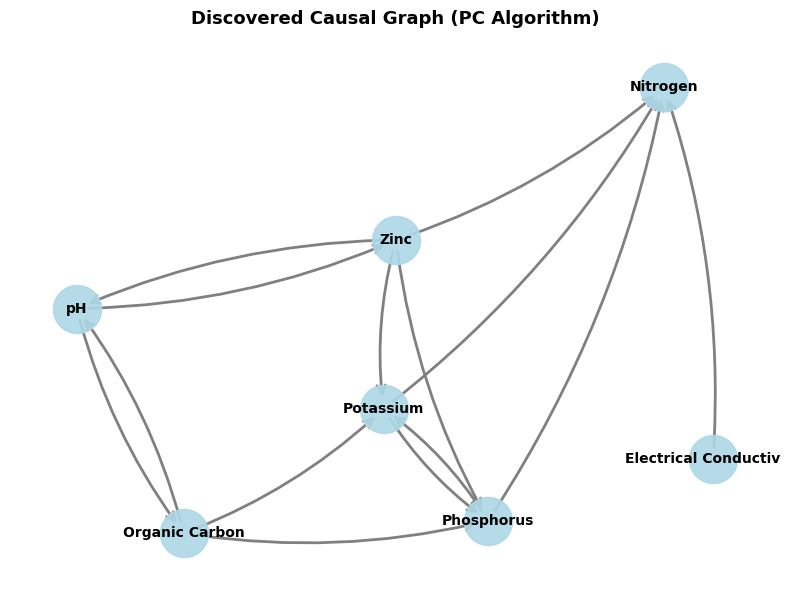

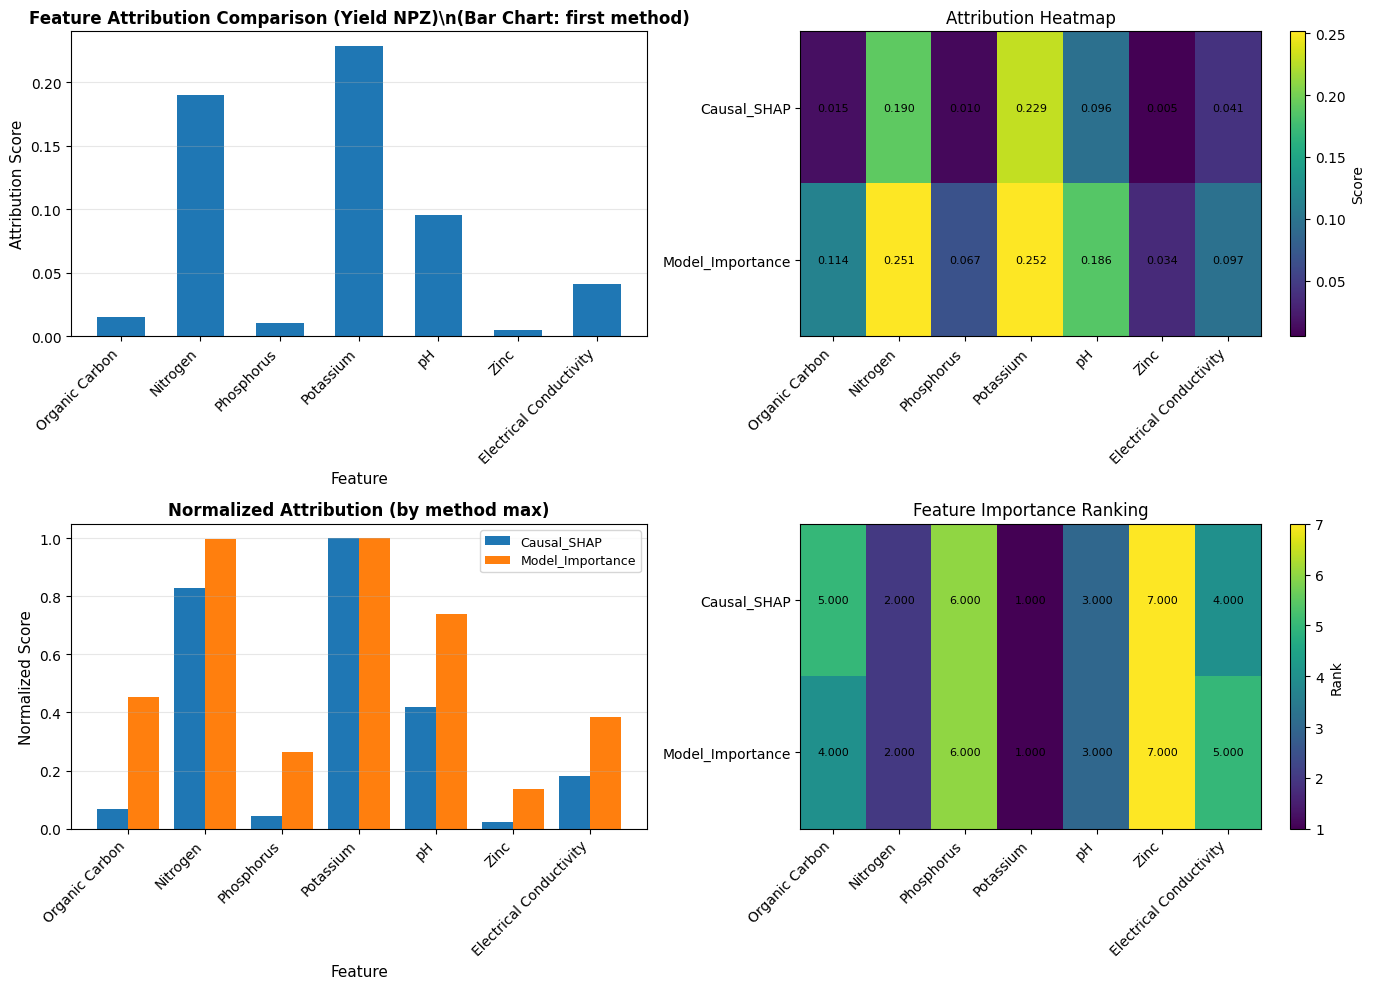

In [1]:
"""
CAUSAL SHAP on yield_preprocessed.npz
- Works with keys: X_train, X_test, y_train, y_test, feature_names
- Implements PC-based causal discovery, IDA-style causal effects, and Causal SHAP
- Saves outputs: causal graph PNG, comparison PNG, and CSV of attributions
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from typing import Dict, List, Tuple, Set
warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, accuracy_score
import networkx as nx

try:
    from xgboost import XGBClassifier
    HAVE_XGB = True
except:
    HAVE_XGB = False

from causallearn.search.ConstraintBased.PC import pc

# Configuration
CONFIG = {
    'DATA_PATH': '../../datasets/soil_spi_preprocessed.npz',
    'ALPHA_PC': 0.1,
    'MAX_PERM': 200,
    'M_RESAMPLES': 64,
    'GLOBAL_K': 30,
    'RANDOM_SEED': 42,
    'N_DAGS': 5  # Sample multiple DAGs from CPDAG
}

np.random.seed(CONFIG['RANDOM_SEED'])
rng = np.random.default_rng(CONFIG['RANDOM_SEED'])


# 1. Causal Discovery & Structure Learning

class CausalStructure:
    """Handles causal discovery and DAG sampling from CPDAG"""

    def __init__(self, alpha=0.05):
        self.alpha = alpha
        self.cpdag = None
        self.feature_names = None
        self.dags = []

    def discover(self, X: pd.DataFrame):
        """Run PC algorithm on features"""
        self.feature_names = list(X.columns)
        print(f"Running PC algorithm on {len(self.feature_names)} features...")

        pc_res = pc(X.values, alpha=self.alpha, show_progress=False)
        self.cpdag = pc_res.G.graph

        print(f"Causal discovery complete")
        return self

    def get_skeleton(self) -> nx.DiGraph:
        """Convert CPDAG to networkx DiGraph"""
        G = nx.DiGraph()
        G.add_nodes_from(self.feature_names)

        n = len(self.feature_names)
        for i in range(n):
            for j in range(n):
                if i == j:
                    continue
                # Directed edge i->j
                if self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                    G.add_edge(self.feature_names[i], self.feature_names[j])
                # Undirected edge: add both directions
                elif self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1:
                    if i < j:  # Avoid double-adding
                        G.add_edge(self.feature_names[i], self.feature_names[j])
                        G.add_edge(self.feature_names[j], self.feature_names[i])

        return G

    def sample_dags(self, n_samples=5) -> List[nx.DiGraph]:
        """
        Sample multiple DAG orientations from CPDAG
        For undirected edges, randomly orient them
        """
        base_G = self.get_skeleton()
        dags = []

        # Find undirected edges
        undirected = []
        for i, u in enumerate(self.feature_names):
            for j, v in enumerate(self.feature_names):
                if i < j and self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1:
                    undirected.append((u, v))

        if len(undirected) == 0:
            # CPDAG is already fully directed
            print(f"  CPDAG is fully directed ({base_G.number_of_edges()} edges)")
            return [base_G]

        print(f"  Found {len(undirected)} undirected edges, sampling orientations...")

        # Sample orientations
        for _ in range(n_samples):
            G = nx.DiGraph()
            G.add_nodes_from(self.feature_names)

            # Add directed edges from CPDAG
            for i, u in enumerate(self.feature_names):
                for j, v in enumerate(self.feature_names):
                    if self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                        G.add_edge(u, v)

            # Randomly orient undirected edges (ensuring acyclicity)
            for u, v in undirected:
                if rng.random() < 0.5:
                    G.add_edge(u, v)
                else:
                    G.add_edge(v, u)

                # Check for cycles and reverse if needed
                if not nx.is_directed_acyclic_graph(G):
                    G.remove_edge(u, v) if G.has_edge(u, v) else G.remove_edge(v, u)
                    G.add_edge(v, u) if not G.has_edge(v, u) else G.add_edge(u, v)

            dags.append(G)

        self.dags = dags
        return dags


# 2. Causal Mechanism Learning

class LinearMechanisms:
    """Learn linear structural equation models"""

    def __init__(self, dag: nx.DiGraph, feature_names: List[str]):
        self.dag = dag
        self.feature_names = feature_names
        self.mechanisms = {}
        self.topo_order = None

    def fit(self, X: pd.DataFrame):
        """Fit linear mechanisms for each variable"""
        # Get topological order
        try:
            self.topo_order = list(nx.topological_sort(self.dag))
        except:
            # Fallback if cycles exist
            self.topo_order = self._safe_topo_order()

        for var in self.feature_names:
            parents = list(self.dag.predecessors(var))

            if not parents:
                # No parents: use marginal distribution
                self.mechanisms[var] = {
                    'parents': [],
                    'intercept': float(X[var].mean()),
                    'coef': None,
                    'sigma': float(X[var].std())
                }
            else:
                # Regress on parents
                lr = LinearRegression()
                lr.fit(X[parents].values, X[var].values)

                pred = lr.predict(X[parents].values)
                resid = X[var].values - pred

                self.mechanisms[var] = {
                    'parents': parents,
                    'intercept': float(lr.intercept_),
                    'coef': lr.coef_.astype(float),
                    'sigma': float(np.std(resid))
                }

        return self

    def _safe_topo_order(self) -> List[str]:
        """Fallback topological sort"""
        ordered = []
        remaining = set(self.feature_names)

        while remaining:
            # Find nodes with no remaining parents
            ready = [n for n in remaining
                    if all(p in ordered or p not in remaining
                           for p in self.dag.predecessors(n))]

            if not ready:
                # Force one with fewest remaining parents
                ready = [min(remaining,
                           key=lambda n: len([p for p in self.dag.predecessors(n)
                                            if p in remaining]))]

            for n in ready:
                ordered.append(n)
                remaining.remove(n)

        return ordered

    def sample_intervention(self, S: Set[str], x_obs: pd.Series, rng) -> Dict:
        """
        Sample from interventional distribution do(X_S = x_S)
        """
        x_new = {}

        for var in self.topo_order:
            if var in S:
                x_new[var] = float(x_obs[var])
            else:
                # Sample from mechanism
                mech = self.mechanisms[var]

                if not mech['parents']:
                    # No parents: sample from marginal
                    mu, sigma = mech['intercept'], mech['sigma']
                    if sigma < 1e-6:
                        x_new[var] = mu
                    else:
                        x_new[var] = float(rng.normal(mu, sigma))
                else:
                    # Sample from conditional
                    parent_vals = np.array([x_new.get(p, x_obs[p])
                                           for p in mech['parents']])

                    mu = mech['intercept'] + parent_vals @ mech['coef']
                    sigma = mech['sigma']
                    if sigma < 1e-6:
                        x_new[var] = mu
                    else:
                        x_new[var] = float(rng.normal(mu, sigma))

        return x_new


# 3. Causal Effect Estimation (IDA-style)

class CausalEffects:
    """Estimate total causal effects using path analysis"""

    def __init__(self, dags: List[nx.DiGraph], feature_names: List[str]):
        self.dags = dags
        self.feature_names = feature_names
        self.effects = {}

    def compute_effects(self, X: pd.DataFrame, y: pd.Series) -> Dict[str, float]:
        """
        Compute total causal effects for each feature on target
        Average over multiple DAG samples (IDA-style)
        """
        print("Computing causal effects (IDA-style)...")

        # Build augmented graphs with target
        aug_graphs = []

        for dag in self.dags:
            G = dag.copy()
            G.add_node('Y')

            # Add edges from features to Y with estimated weights
            for feat in self.feature_names:
                # Conditional regression: feat -> Y | other features
                other_feats = [f for f in self.feature_names if f != feat]
                if other_feats:
                    X_cond = np.column_stack([X[other_feats].values, X[feat].values])
                else:
                    X_cond = X[[feat]].values

                lr = LinearRegression()
                lr.fit(X_cond, y.values)
                weight = abs(lr.coef_[-1])

                if weight > 1e-6:
                    G.add_edge(feat, 'Y', weight=weight)

            # Add edge weights for feature->feature edges
            for u, v in dag.edges():
                parents = [p for p in dag.predecessors(v) if p != u]
                if parents:
                    X_reg = np.column_stack([X[parents].values, X[u].values])
                else:
                    X_reg = X[[u]].values

                lr = LinearRegression()
                lr.fit(X_reg, X[v].values)
                weight = abs(lr.coef_[-1])
                G[u][v]['weight'] = weight

            aug_graphs.append(G)

        # Compute total effects (average over DAGs)
        total_effects = {feat: [] for feat in self.feature_names}

        for G in aug_graphs:
            for feat in self.feature_names:
                effect = 0.0

                # Sum over all paths feat -> Y
                try:
                    for path in nx.all_simple_paths(G, feat, 'Y', cutoff=10):
                        path_effect = 1.0
                        for i in range(len(path) - 1):
                            edge_data = G.get_edge_data(path[i], path[i+1])
                            if edge_data and 'weight' in edge_data:
                                path_effect *= edge_data['weight']
                        effect += path_effect
                except:
                    pass

                total_effects[feat].append(effect)

        # Average across DAGs
        self.effects = {feat: np.mean(effects)
                       for feat, effects in total_effects.items()}

        print(f"Causal effects computed (averaged over {len(self.dags)} DAGs)")
        return self.effects

    def get_gamma_weights(self) -> Dict[str, float]:
        """Compute gamma weights (normalized absolute effects)"""
        abs_effects = {k: abs(v) for k, v in self.effects.items()}
        total = sum(abs_effects.values()) + 1e-12

        return {k: v / total for k, v in abs_effects.items()}


# 4. Causal SHAP Implementation

class CausalSHAP:
    """Main Causal SHAP implementation"""

    def __init__(self, model, causal_structure: CausalStructure,
                 X_train: pd.DataFrame, y_train: pd.Series):
        self.model = model
        self.structure = causal_structure
        self.X_train = X_train
        self.y_train = y_train
        self.feature_names = list(X_train.columns)

        print("\\nLearning causal mechanisms...")
        # Learn mechanisms and effects
        self.dags = causal_structure.sample_dags(n_samples=CONFIG['N_DAGS'])
        self.mechanisms_list = [LinearMechanisms(dag, self.feature_names).fit(X_train)
                               for dag in self.dags]

        # Compute causal effects
        self.causal_effects = CausalEffects(self.dags, self.feature_names)
        self.causal_effects.compute_effects(X_train, y_train)
        self.gamma = self.causal_effects.get_gamma_weights()

        print(f"Learned {len(self.dags)} DAG orientations")

    def _causal_value_function(self, S: Set[str], x: pd.Series,
                               pred_class: int, M: int) -> float:
        """
        v_c(S) = E[f(X) | do(X_S = x_S)]
        Average over DAG samples and Monte Carlo samples
        """
        total = 0.0
        samples_per_dag = max(1, M // len(self.mechanisms_list))

        for mechanisms in self.mechanisms_list:
            for _ in range(samples_per_dag):
                x_sample = mechanisms.sample_intervention(S, x, rng)
                X_mat = pd.DataFrame([x_sample], columns=self.feature_names)

                prob = self.model.predict_proba(X_mat.values)[0][pred_class]
                total += prob

        actual_samples = samples_per_dag * len(self.mechanisms_list)
        return total / actual_samples

    def explain_instance(self, x: pd.Series, n_perms: int = None,
                        m_samples: int = None) -> pd.Series:
        """
        Compute Causal SHAP values for a single instance
        """
        if n_perms is None:
            n_perms = CONFIG['MAX_PERM']
        if m_samples is None:
            m_samples = CONFIG['M_RESAMPLES']

        # Get predicted class
        probs = self.model.predict_proba(pd.DataFrame([x],
                                         columns=self.feature_names).values)[0]
        pred_class = int(np.argmax(probs))

        # Permutation-based estimation
        phi = np.zeros(len(self.feature_names))

        for _ in range(n_perms):
            perm = rng.permutation(self.feature_names)
            S = set()
            v_prev = self._causal_value_function(S, x, pred_class, m_samples)

            for feat in perm:
                S_next = S | {feat}
                v_curr = self._causal_value_function(S_next, x, pred_class, m_samples)

                delta = v_curr - v_prev
                contrib = self.gamma[feat] * delta  # Causal weighting

                phi[self.feature_names.index(feat)] += contrib
                v_prev = v_curr
                S = S_next

        phi /= n_perms

        # Normalize for local accuracy
        f_x = probs[pred_class]
        v_empty = self._causal_value_function(set(), x, pred_class, m_samples)

        sum_phi = np.sum(phi)
        if abs(sum_phi) > 1e-12:
            phi = phi * ((f_x - v_empty) / sum_phi)

        return pd.Series(phi, index=self.feature_names, name='Causal_SHAP')

    def explain_global(self, X_test: pd.DataFrame, n_samples: int = None) -> pd.Series:
        """Global explanation: average over test instances"""
        if n_samples is None:
            n_samples = CONFIG['GLOBAL_K']

        n_samples = min(n_samples, len(X_test))
        indices = rng.choice(len(X_test), size=n_samples, replace=False)

        print(f"\\nComputing global Causal SHAP (averaging over {n_samples} instances)...")
        explanations = []
        for i, idx in enumerate(indices):
            if (i + 1) % 5 == 0:
                print(f"  Progress: {i+1}/{n_samples}")
            exp = self.explain_instance(X_test.iloc[idx],
                                       n_perms=max(10, CONFIG['MAX_PERM']//4))
            explanations.append(exp)

        print("ok Global Causal SHAP computed")
        return pd.concat(explanations, axis=1).mean(axis=1).rename('Causal_SHAP_Global')


# 5. Baseline Methods for Comparison (optional SHAP if installed)

def compute_baseline_shap(model, X_train, X_test):
    """Compute Kernel SHAP values if shap is installed"""
    try:
        import shap
        print("\\nComputing KERNEL SHAP baseline...")
        bg_size = min(100, len(X_train))
        bg = shap.kmeans(X_train.values, bg_size)
        explainer = shap.KernelExplainer(lambda x: model.predict_proba(x), bg)
        shap_values = explainer.shap_values(X_test.values, nsamples=100)

        # Average absolute values across classes
        if isinstance(shap_values, list):
            global_imp = np.mean([np.abs(sv).mean(axis=0) for sv in shap_values], axis=0)
        else:
            global_imp = np.abs(shap_values).mean(axis=0)
        print("ok KERNEL SHAP computed")
        return pd.Series(global_imp, index=X_test.columns, name='SHAP_kernel')
    except Exception as e:
        print(f"Warning: SHAP computation skipped/failed: {e}")
        return None


def compute_feature_importance(model, feature_names):
    """Compute model's native feature importance"""
    if hasattr(model, 'feature_importances_'):
        imp = model.feature_importances_
        return pd.Series(imp, index=feature_names, name='Model_Importance')
    return None


# 6. Visualization (pure matplotlib, no seaborn)

def annotate_heatmap(ax, data: pd.DataFrame, title: str, cbar_label: str):
    im = ax.imshow(data.values, aspect='auto')
    ax.set_xticks(np.arange(data.shape[1]))
    ax.set_yticks(np.arange(data.shape[0]))
    ax.set_xticklabels(data.columns, rotation=45, ha='right')
    ax.set_yticklabels(data.index)
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            ax.text(j, i, f"{data.values[i, j]:.3f}", ha='center', va='center', fontsize=8)
    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label(cbar_label)
    ax.set_title(title)


def plot_comparison(df_comp: pd.DataFrame, title: str = "Feature Attribution Comparison"):
    """Visualize comparison of different methods (matplotlib only)"""
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    # Bar plot
    axes[0, 0].bar(np.arange(df_comp.shape[0]), df_comp.iloc[:, 0], width=0.6)
    axes[0, 0].set_title(f'{title}\\n(Bar Chart: first method)', fontsize=12, fontweight='bold')
    axes[0, 0].set_ylabel('Attribution Score', fontsize=11)
    axes[0, 0].set_xlabel('Feature', fontsize=11)
    axes[0, 0].set_xticks(np.arange(df_comp.shape[0]))
    axes[0, 0].set_xticklabels(df_comp.index, rotation=45, ha='right')
    axes[0, 0].grid(axis='y', alpha=0.3)

    # Heatmap
    annotate_heatmap(axes[0, 1], df_comp.T, 'Attribution Heatmap', 'Score')

    # Normalized comparison
    df_norm = df_comp.div(df_comp.abs().max(axis=0), axis=1)
    for i, col in enumerate(df_norm.columns):
        axes[1, 0].bar(np.arange(df_norm.shape[0]) + (i-0.5)*(0.8/len(df_norm.columns)), df_norm[col], width=0.8/len(df_norm.columns), label=col)
    axes[1, 0].set_title('Normalized Attribution (by method max)', fontsize=12, fontweight='bold')
    axes[1, 0].set_ylabel('Normalized Score', fontsize=11)
    axes[1, 0].set_xlabel('Feature', fontsize=11)
    axes[1, 0].set_xticks(np.arange(df_norm.shape[0]))
    axes[1, 0].set_xticklabels(df_norm.index, rotation=45, ha='right')
    axes[1, 0].legend(loc='best', fontsize=9)
    axes[1, 0].grid(axis='y', alpha=0.3)

    # Rank comparison heatmap
    ranks = df_comp.rank(ascending=False)
    annotate_heatmap(axes[1, 1], ranks.T, 'Feature Importance Ranking', 'Rank')

    fig.tight_layout()
    return fig


def plot_causal_graph(G: nx.DiGraph, title: str = "Discovered Causal Graph"):
    """Visualize the causal graph"""
    plt.figure(figsize=(8, 6))
    pos = nx.spring_layout(G, seed=CONFIG['RANDOM_SEED'], k=1.0, iterations=200)

    nx.draw_networkx_nodes(G, pos, node_color='lightblue', node_size=1200, alpha=0.9)
    nx.draw_networkx_edges(G, pos, edge_color='gray', arrows=True, arrowsize=15,
                           arrowstyle='->', width=2, connectionstyle='arc3,rad=0.1')
    nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')

    plt.title(title, fontsize=13, fontweight='bold', pad=12)
    plt.axis('off')
    plt.tight_layout()
    return plt.gcf()


# 7. Main Execution

def main():
    """Run complete Causal SHAP analysis on NPZ dataset"""

    print("\\n" + "="*70)
    print("CAUSAL SHAP on NPZ Dataset")
    print("="*70 + "\\n")

    # Load data
    print("Loading NPZ dataset...")
    try:
        data = np.load(CONFIG['DATA_PATH'], allow_pickle=True)
        keys = list(data.keys())
        print(f"NPZ loaded with keys: {keys}")
    except FileNotFoundError:
        print(f"ERROR: Could not find '{CONFIG['DATA_PATH']}'")
        print("Please ensure the file is in the current directory.")
        return

    required_keys = {'X_train', 'X_test', 'y_train', 'y_test', 'feature_names'}
    if not required_keys.issubset(set(keys)):
        print("ERROR: NPZ must contain X_train, X_test, y_train, y_test, feature_names.")
        return

    # Extract
    X_train = pd.DataFrame(data['X_train'], columns=list(data['feature_names']))
    X_test  = pd.DataFrame(data['X_test'],  columns=list(data['feature_names']))
    y_train = pd.Series(data['y_train'].astype(int))
    y_test  = pd.Series(data['y_test'].astype(int))

    print(f"Shapes: X_train={X_train.shape}, X_test={X_test.shape}, y_train={y_train.shape}, y_test={y_test.shape}")
    print(f"Features: {', '.join(X_train.columns)}")
    n_classes = len(np.unique(y_train))
    print(f"Target classes: {n_classes}")

    # Scale features using training stats
    scaler = StandardScaler()
    X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
    X_test_scaled  = pd.DataFrame(scaler.transform(X_test),  columns=X_test.columns)

    # Train model
    print("\\n" + "="*70)
    print("Training Model")
    print("="*70)

    if HAVE_XGB:
        model = XGBClassifier(
            n_estimators=160,
            max_depth=5,
            learning_rate=0.08,
            subsample=0.9,
            colsample_bytree=0.9,
            random_state=CONFIG['RANDOM_SEED'],
            verbosity=0,
            objective="multi:softprob",
            num_class=n_classes,
        )
        print("Using XGBoost classifier")
    else:
        model = RandomForestClassifier(
            n_estimators=160,
            max_depth=6,
            random_state=CONFIG['RANDOM_SEED']
        )
        print("Using Random Forest classifier")

    model.fit(X_train_scaled.values, y_train.values)

    y_pred = model.predict(X_test_scaled.values)
    f1 = f1_score(y_test, y_pred, average='macro')
    acc = accuracy_score(y_test, y_pred)

    print(f"Model trained")
    print(f"  Test Accuracy: {acc:.4f}")
    print(f"  Test Macro F1: {f1:.4f}")

    # Causal Discovery
    print("\\n" + "="*70)
    print("Step 1: Causal Discovery (PC Algorithm)")
    print("="*70)

    causal_structure = CausalStructure(alpha=CONFIG['ALPHA_PC'])
    causal_structure.discover(X_train_scaled)

    # Visualize discovered graph
    G = causal_structure.get_skeleton()
    print(f"\\nDiscovered graph: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")

    fig_graph = plot_causal_graph(G, "Discovered Causal Graph (PC Algorithm)")
    fig_graph.savefig('causal_graph_yield.png', dpi=150, bbox_inches='tight')
    print("ok Causal graph saved to 'causal_graph_yield.png'")

    # Causal SHAP
    print("\\n" + "="*70)
    print("Step 2: Computing Causal SHAP")
    print("="*70)

    causal_shap = CausalSHAP(model, causal_structure, X_train_scaled, y_train)

    # Show causal effects
    print("\\nTotal Causal Effects (W_i):")
    print("-" * 40)
    for feat in X_train.columns:
        effect = causal_shap.causal_effects.effects[feat]
        gamma = causal_shap.gamma[feat]
        print(f"  {feat:15s}: W={effect:8.4f}  γ={gamma:.4f}")

    # Global explanation
    global_causal_shap = causal_shap.explain_global(X_test_scaled, n_samples=CONFIG['GLOBAL_K'])

    # Baseline methods (optional)
    print("\\n" + "="*70)
    print("Step 3: Computing Baseline Methods")
    print("="*70)
    baseline_shap = compute_baseline_shap(model, X_train_scaled, X_test_scaled)
    model_imp = compute_feature_importance(model, list(X_train.columns))

    # Comparison
    print("\\n" + "="*70)
    print("Step 4: Results Comparison")
    print("="*70)

    attributions = {
        'Causal_SHAP': global_causal_shap,
    }

    if baseline_shap is not None:
        attributions['Kernel_SHAP'] = baseline_shap

    if model_imp is not None:
        attributions['Model_Importance'] = model_imp

    df_comparison = pd.DataFrame(attributions)
    df_comparison.to_csv('attribution_scores_yield.csv', index=True)

    print("\\n" + "="*70)
    print("Attribution Scores:")
    print("="*70)
    print(df_comparison.round(6).to_string())
    print("\\nSaved CSV -> attribution_scores_yield.csv")

    # Correlation analysis
    if len(attributions) > 1:
        print("\\n" + "="*70)
        print("Correlation between methods:")
        print("="*70)
        corr_matrix = df_comparison.corr()
        print(corr_matrix.round(4).to_string())

    # Visualization
    fig = plot_comparison(df_comparison,
                         title="Feature Attribution Comparison (Yield NPZ)")
    fig.savefig('attribution_comparison_yield.png', dpi=150, bbox_inches='tight')
    print("\\nok Comparison plot saved to 'attribution_comparison_yield.png'")

    try:
        plt.show()
    except Exception:
        pass

if __name__ == "__main__":
    main()

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, pearsonr
from numpy.linalg import norm
import logging
from pathlib import Path

logger = logging.getLogger(__name__)

# ── Dataset config ────────────────────────────────────────────────────────────
DATASET_NAME = "lung_cancer"
MODEL_NAME   = "regression"
OUTPUT_DIR   = Path("outputs/lung_cancer")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

ground_truth = pd.Series({
    "smoking":      2.0,
    "stress":       1.2,
    "drink_coffee": 0.0,
}, name="GroundTruth")

gt_norm = ground_truth.abs() / ground_truth.abs().sum()
print("\nOriginal Ground Truth:")
print(ground_truth)
print("\nNormalized Ground Truth (sums to 1):")
print(gt_norm)
print(f"\nSum of normalized values: {gt_norm.sum():.6f}")

# ── Hardcoded attributions (smoking, stress, drink_coffee) ────────────────────
# They will be abs-normalized to sum to 1 before comparison.
raw_attributions = {
    "causal_shap": pd.Series({
        "smoking":      0.5115,
        "stress":       0.4885,
        "drink_coffee": 0.0,
    }),
    "shapley": pd.Series({
        "smoking":      0.3168,
        "stress":       0.2673,
        "drink_coffee": 0.4159,
    }),
    "nucleolus": pd.Series({
        "smoking":      0.3109,
        "stress":       0.3522,
        "drink_coffee": 0.3369,
    }),
    "gately": pd.Series({
        "smoking":      0.3209,
        "stress":       0.3407,
        "drink_coffee": 0.3385,
    }),
}

# ── Method display names ──────────────────────────────────────────────────────
method_display_names = {
    "causal_shap": "PC Algorithm (Causal SHAP)",
    "shapley":     "Shapley Value",
    "nucleolus":   "Nucleolus",
    "gately":      "Gately Point",
}

# ── Build df_val from hardcoded attributions ──────────────────────────────────
records = []
for method, series in raw_attributions.items():
    for feature, value in series.items():
        records.append({"method": method, "feature": feature, "value": value})
df_val = pd.DataFrame(records)

# ── Metrics ───────────────────────────────────────────────────────────────────
results_gt = []
for method in df_val["method"].unique():
    subset = df_val[df_val["method"] == method].set_index("feature")["value"]
    subset_norm = subset.abs() / subset.abs().sum()
    subset_norm = subset_norm[gt_norm.index]

    spearman_corr, _ = spearmanr(gt_norm, subset_norm)
    pearson_corr,  _ = pearsonr(gt_norm, subset_norm)
    cos_sim = np.dot(gt_norm, subset_norm) / (norm(gt_norm) * norm(subset_norm))
    mape = (abs(gt_norm - subset_norm) / gt_norm).mean()
    rmse = np.sqrt(((gt_norm - subset_norm) ** 2).mean())

    results_gt.append({
        "method":    method,
        "Spearman":  spearman_corr,
        "Pearson":   pearson_corr,
        "CosineSim": cos_sim,
        "MAPE":      mape,
        "RMSE":      rmse
    })

results_df = pd.DataFrame(results_gt).sort_values("CosineSim", ascending=False)
print("\nComparison with Ground Truth")
print(results_df)

# ── Plots ─────────────────────────────────────────────────────────────────────
methods_to_plot = df_val["method"].unique()

for method in methods_to_plot:
    fig, ax = plt.subplots(figsize=(8, 6))

    subset = df_val[df_val["method"] == method].set_index("feature")["value"]
    subset_norm = subset.abs() / subset.abs().sum()
    subset_norm = subset_norm[gt_norm.index]

    display_name = method_display_names.get(method, method.replace("_", " ").title())

    pd.DataFrame({
        "Ground Truth": gt_norm,
        display_name:   subset_norm,
    }).plot(kind='bar', ax=ax, edgecolor='none', rot=90)

    method_metrics = results_df[results_df["method"] == method].iloc[0]

    ax.set_title(
        f"{display_name} vs Ground Truth\n",
        fontsize=12,
        fontweight='bold'
    )
    ax.set_ylabel("Normalized Importance", fontsize=11)
    ax.set_xlabel("Features", fontsize=11)
    ax.legend(fontsize=10)
    ax.grid(axis='y', alpha=0.3)

    plt.tight_layout()

    output_filename = OUTPUT_DIR / f"{DATASET_NAME}_{MODEL_NAME}_{method}_ground_truth.png"
    plt.savefig(output_filename, dpi=600, bbox_inches='tight')
    logger.info(f"Saved ground truth comparison for {display_name} to {output_filename}")
    plt.close()

logger.info(f"\nAll ground truth comparison plots saved to: {OUTPUT_DIR}")


Original Ground Truth:
smoking         2.0
stress          1.2
drink_coffee    0.0
Name: GroundTruth, dtype: float64

Normalized Ground Truth (sums to 1):
smoking         0.625
stress          0.375
drink_coffee    0.000
Name: GroundTruth, dtype: float64

Sum of normalized values: 1.000000

Comparison with Ground Truth
        method  Spearman   Pearson  CosineSim      MAPE      RMSE
0  causal_shap       1.0  0.932753   0.975463  0.242133  0.092672
3       gately      -0.5 -0.738405   0.779863       inf  0.263461
2    nucleolus      -0.5 -0.528741   0.774600       inf  0.266258
1      shapley      -0.5 -0.737212   0.696850       inf  0.305265



Original Ground Truth:
smoking         2.0
stress          1.2
drink_coffee    0.0
Name: GroundTruth, dtype: float64

Normalized Ground Truth (absolute values):
smoking         0.625
stress          0.375
drink_coffee    0.000
Name: GroundTruth, dtype: float64

Sum of normalized values: 1.000000

Comparison with Ground Truth
        method  Spearman   Pearson  CosineSim      MAPE      RMSE
0  causal_shap       1.0  0.932753   0.975463  0.242133  0.092672
3       gately      -0.5 -0.738405   0.779863       inf  0.263461
2    nucleolus      -0.5 -0.528741   0.774600       inf  0.266258
1      shapley      -0.5 -0.737212   0.696850       inf  0.305265


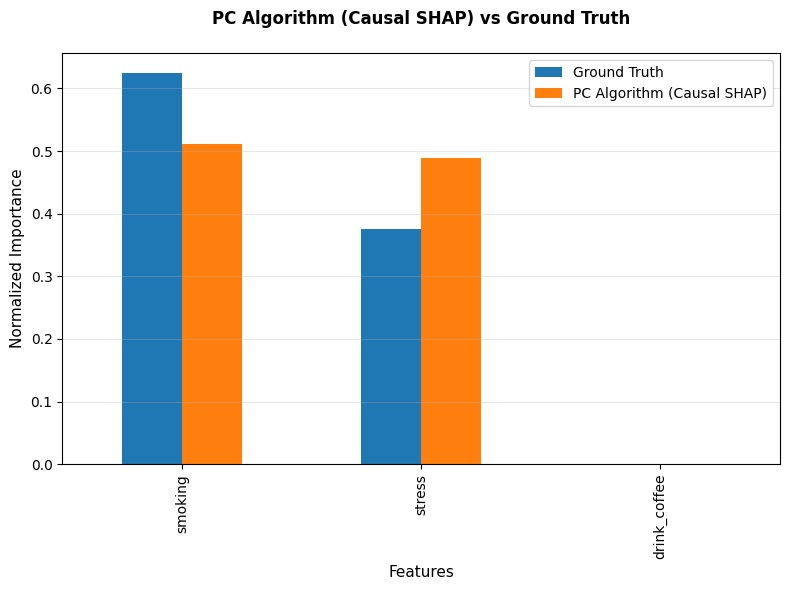

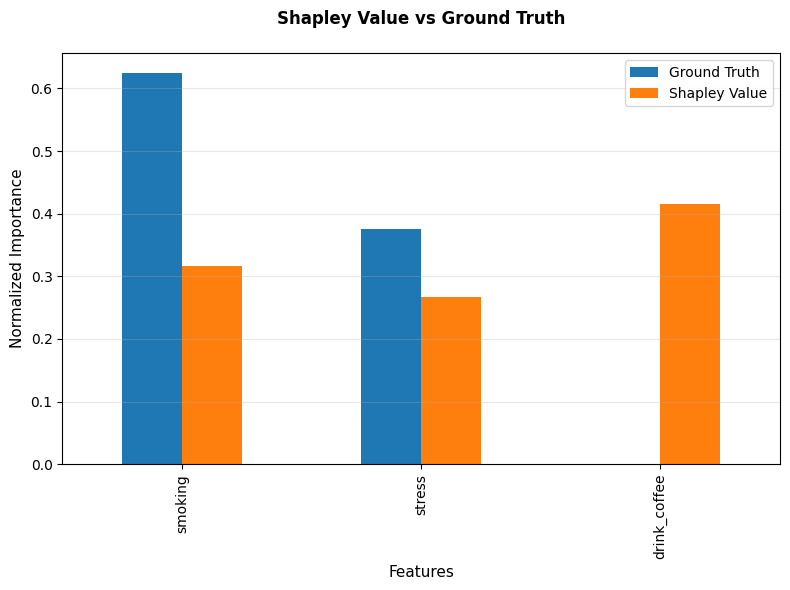

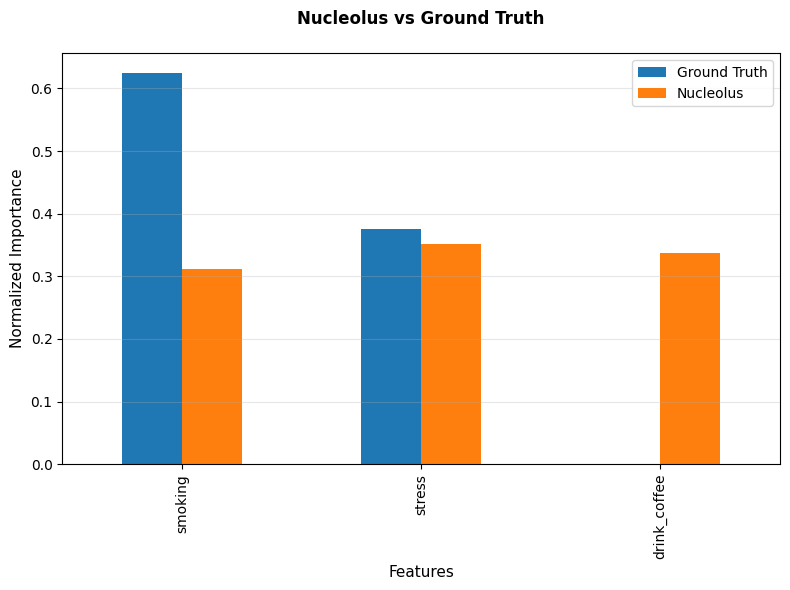

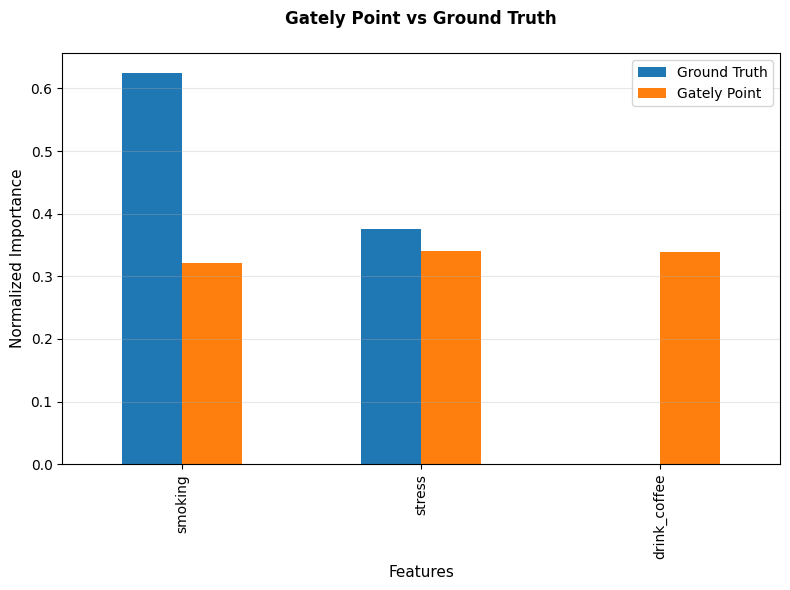

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, pearsonr
from numpy.linalg import norm
import logging
from pathlib import Path

logger = logging.getLogger(__name__)

# ── Dataset config ────────────────────────────────────────────────────────────
DATASET_NAME = "lung_cancer"
MODEL_NAME   = "regression"
OUTPUT_DIR   = Path("outputs/lung_cancer")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ── Ground truth from SCM path products ──────────────────────────────────────
ground_truth = pd.Series({
    "smoking":      2.0,
    "stress":       1.2,
    "drink_coffee": 0.0,
}, name="GroundTruth")

gt_norm = ground_truth.abs() / ground_truth.abs().sum()
print("\nOriginal Ground Truth:")
print(ground_truth)
print("\nNormalized Ground Truth (absolute values):")
print(gt_norm)
print(f"\nSum of normalized values: {gt_norm.sum():.6f}")

# ── Build df_val from known attributions ──────────────────────────────────────
raw_attributions = {
    "causal_shap": pd.Series({"smoking": 0.5115, "stress": 0.4885, "drink_coffee": 0.0}),
    "shapley":     pd.Series({"smoking": 0.3168, "stress": 0.2673, "drink_coffee": 0.4159}),
    "nucleolus":   pd.Series({"smoking": 0.3109, "stress": 0.3522, "drink_coffee": 0.3369}),
    "gately":      pd.Series({"smoking": 0.3209, "stress": 0.3407, "drink_coffee": 0.3385}),
}

records = []
for method, series in raw_attributions.items():
    for feature, value in series.items():
        records.append({"method": method, "feature": feature, "value": value})
df_val = pd.DataFrame(records)

# ── Metrics ───────────────────────────────────────────────────────────────────
results_gt = []
for method in df_val["method"].unique():
    subset = df_val[df_val["method"] == method].set_index("feature")["value"]
    subset_norm = subset.abs() / subset.abs().sum()
    subset_norm = subset_norm[gt_norm.index]

    spearman_corr, _ = spearmanr(gt_norm, subset_norm)
    pearson_corr,  _ = pearsonr(gt_norm, subset_norm)
    cos_sim = np.dot(gt_norm, subset_norm) / (norm(gt_norm) * norm(subset_norm))
    mape = (abs(gt_norm - subset_norm) / gt_norm).mean()
    rsme = np.sqrt(((gt_norm - subset_norm) ** 2).mean())

    results_gt.append({
        "method":    method,
        "Spearman":  spearman_corr,
        "Pearson":   pearson_corr,
        "CosineSim": cos_sim,
        "MAPE":      mape,
        "RMSE":      rsme
    })

results_df = pd.DataFrame(results_gt).sort_values("CosineSim", ascending=False)
print("\nComparison with Ground Truth")
print(results_df)

# ── Method display names ──────────────────────────────────────────────────────
method_display_names = {
    "causal_shap": "PC Algorithm (Causal SHAP)",
    "shapley":     "Shapley Value",
    "nucleolus":   "Nucleolus",
    "gately":      "Gately Point",
}

# ── Plots ─────────────────────────────────────────────────────────────────────
methods_to_plot = df_val["method"].unique()

for method in methods_to_plot:
    fig, ax = plt.subplots(figsize=(8, 6))

    subset = df_val[df_val["method"] == method].set_index("feature")["value"]
    subset_norm = subset.abs() / subset.abs().sum()
    subset_norm = subset_norm[gt_norm.index]

    display_name = method_display_names.get(method, method.replace("_", " ").title())

    pd.DataFrame({
        "Ground Truth": gt_norm,
        display_name:   subset_norm,
    }).plot(kind='bar', ax=ax)

    method_metrics = results_df[results_df["method"] == method].iloc[0]

    ax.set_title(
        f"{display_name} vs Ground Truth\n",
        fontsize=12,
        fontweight='bold'
    )
    ax.set_ylabel("Normalized Importance", fontsize=11)
    ax.set_xlabel("Features", fontsize=11)
    ax.legend(fontsize=10)
    ax.grid(axis='y', alpha=0.3)

    plt.tight_layout()

    output_filename = OUTPUT_DIR / f"{DATASET_NAME}_{MODEL_NAME}_{method}_ground_truth.png"
    plt.savefig(output_filename, dpi=600, bbox_inches='tight')
    logger.info(f"Saved ground truth comparison for {display_name} to {output_filename}")
    plt.show()
    plt.close()

logger.info(f"\nAll ground truth comparison plots saved to: {OUTPUT_DIR}")

In [5]:
"""
Global Sensitivity & Noise Robustness Metrics
==============================================
Datasets:
  1. Synthetic Soil  → Shapley, Nucleolus, Gately, Causal SHAP (DAGMA Linear)
  2. CV Risk         → Causal SHAP (DAGMA Linear)

Metrics (exactly matching Rohit's notebook):
  Sensitivity  : Spearman, Pearson, Cosine Similarity
                 between attribution vector and Leave-One-Out (LOO) impact vector
  Robustness   : Cosine Similarity, Spearman rank corr, Normalised L2 distance
                 between attribution on clean vs noisy data (noise_level=0.05)

Run
---
  cd 
  python sensitivity_noise_metrics.py
"""

import sys, os, warnings, itertools, math
warnings.filterwarnings("ignore")

# If openpyxl missing: pip install openpyxl --break-system-packages
from openpyxl import Workbook
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter

HOME = os.path.expanduser("~")
sys.path.insert(0, HOME)

import numpy as np
import pandas as pd
from scipy.stats import pearsonr, spearmanr
from numpy.linalg import norm
from sklearn.linear_model import LogisticRegression, LinearRegression, Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import networkx as nx

# gt_concepts imports
from cgt_xai.concepts.shapley      import exact_shapley_value
from cgt_xai.concepts.nucleolus    import exact_nucleolus
from cgt_xai.concepts.gately_point import exact_gately_value

RANDOM_SEED = 42
NOISE_LEVEL = 0.05

# Causal SHAP config - separate for LR (fast) and RF (slow per prediction)
# LR:  ~1μs per prediction  ->  can afford more samples
# RF:  ~50μs per prediction ->  reduce K, perms, M to stay under ~2 min
SHAP_CONFIG = {
    "logistic": {
        "K_SHAP":  50,    # test instances
        "N_PERMS": 100,   # antithetic -> 200 effective
        "M_SEM":   32,    # SEM samples per coalition
    },
    "random_forest": {
        "K_SHAP":  50,    # same as LR - batching makes RF fast now
        "N_PERMS": 100,   # same as LR
        "M_SEM":   32,    # same as LR
    },
}
# Fallback defaults
M_SEM   = 32
N_PERMS = 100
K_SHAP  = 50

np.random.seed(RANDOM_SEED)
rng = np.random.default_rng(RANDOM_SEED)


# UTILITY WRAPPERS  (exact replica of Rohit's notebook)
class DataWrapper:
    def __init__(self, indices, names=None):
        self.indices    = indices
        self.data_names = names if names else [f"f{i}" for i in range(len(indices))]
    def __len__(self):   return len(self.indices)
    def __iter__(self):  return iter(self.indices)


class Utility:
    """
    Coalitional utility: accuracy of LogisticRegression trained on feature subset.
    Identical to Rohit's Utility class — uses accuracy_score.
    """
    def __init__(self, X_train, y_train, X_test, y_test, feature_names=None):
        self.X_train = X_train
        self.y_train = y_train.astype(int)
        self.X_test  = X_test
        self.y_test  = y_test.astype(int)
        n            = X_train.shape[1]
        self.data    = DataWrapper(list(range(n)), feature_names)
        self._cache  = {}

    def __call__(self, subset):
        key = tuple(sorted(subset))
        if key in self._cache:
            return self._cache[key]
        if len(key) == 0:
            majority = np.bincount(self.y_train).argmax()
            score    = accuracy_score(self.y_test, np.full_like(self.y_test, majority))
            self._cache[key] = score
            return score
        model = LogisticRegression(max_iter=1000, random_state=RANDOM_SEED, C=1.0)
        model.fit(self.X_train[:, key], self.y_train)
        score = accuracy_score(self.y_test, model.predict(self.X_test[:, key]))
        self._cache[key] = score
        return score


class UtilityRF:
    """
    Coalitional utility: accuracy of RandomForestClassifier trained on feature subset.
    Same interface as Utility — drop-in replacement with RF as the base model.
    """
    def __init__(self, X_train, y_train, X_test, y_test, feature_names=None):
        from sklearn.ensemble import RandomForestClassifier
        self.X_train = X_train
        self.y_train = y_train.astype(int)
        self.X_test  = X_test
        self.y_test  = y_test.astype(int)
        self._RFC    = RandomForestClassifier
        n            = X_train.shape[1]
        self.data    = DataWrapper(list(range(n)), feature_names)
        self._cache  = {}

    def __call__(self, subset):
        from sklearn.ensemble import RandomForestClassifier
        key = tuple(sorted(subset))
        if key in self._cache:
            return self._cache[key]
        if len(key) == 0:
            majority = np.bincount(self.y_train).argmax()
            score    = accuracy_score(self.y_test, np.full_like(self.y_test, majority))
            self._cache[key] = score
            return score
        model = RandomForestClassifier(n_estimators=100, random_state=RANDOM_SEED, n_jobs=-1)
        model.fit(self.X_train[:, key], self.y_train)
        score = accuracy_score(self.y_test, model.predict(self.X_test[:, key]))
        self._cache[key] = score
        return score


# Dagma linear runner + gamma
def run_dagma_and_gamma(X_tr_sc, y_tr, feature_names,
                         lambda1=0.02, w_thresh=0.05, lasso_alpha=0.01):
    """
    Pure DAGMA pipeline (X only, no target column):
      1. DAGMA Linear on X_tr_sc → W_est (inter-feature)
      2. LASSO pa(Y) + OLS → Y-edge coefs
      3. Signed path products → gamma
    Returns: W_est, dag dict, gamma array
    """
    from dagma.linear import DagmaLinear
    n = len(feature_names)

    print(f"  [DAGMA] fitting lambda1={lambda1} ...")
    model = DagmaLinear(loss_type='l2')
    W_est = model.fit(X_tr_sc, lambda1=lambda1)

    # Build inter-feature DAG
    dag = {f: [] for f in feature_names}
    for i in range(n):
        for j in range(n):
            if i != j and abs(W_est[i, j]) > w_thresh:
                dag[feature_names[j]].append(feature_names[i])

    edges = [(feature_names[i], feature_names[j], W_est[i,j])
             for i in range(n) for j in range(n)
             if i!=j and abs(W_est[i,j])>w_thresh]
    print(f"  [DAGMA] {len(edges)} inter-feature edges above threshold {w_thresh}")
    for p,c,w in edges:
        print(f"          {p} → {c}  w={w:+.4f}")

    # LASSO pa(Y)
    lasso = Lasso(alpha=lasso_alpha, max_iter=5000, random_state=RANDOM_SEED)
    lasso.fit(X_tr_sc, y_tr)
    pa_Y  = [feature_names[i] for i,c in enumerate(lasso.coef_) if abs(c)>1e-6]
    if not pa_Y: pa_Y = list(feature_names)

    # OLS Y ~ pa(Y) -> Y-edge structural coefs
    pa_idx = [list(feature_names).index(f) for f in pa_Y]
    ols    = LinearRegression().fit(X_tr_sc[:, pa_idx], y_tr)

    # Build full graph with Y node
    G = nx.DiGraph(); G.add_nodes_from(feature_names)
    for i in range(n):
        for j in range(n):
            if i!=j and abs(W_est[i,j])>w_thresh:
                G.add_edge(feature_names[i], feature_names[j], weight=float(W_est[i,j]))
    G.add_node('Y')
    for feat, coef in zip(pa_Y, ols.coef_):
        if abs(coef)>1e-12:
            G.add_edge(feat, 'Y', weight=float(coef))

    # Signed path products
    raw_effects = {}
    for feat in feature_names:
        total = 0.0
        try:
            for path in nx.all_simple_paths(G, feat, 'Y', cutoff=n+1):
                prod, ok = 1.0, True
                for a,b in zip(path[:-1], path[1:]):
                    ed = G.get_edge_data(a,b)
                    if not ed: ok=False; break
                    prod *= ed['weight']
                if ok: total += prod
        except: pass
        raw_effects[feat] = total

    Z     = sum(abs(v) for v in raw_effects.values()) + 1e-12
    gamma = np.array([abs(raw_effects[f])/Z for f in feature_names])
    print(f"  [gamma] " + "  ".join(f"{f}={g:.4f}" for f,g in zip(feature_names, gamma)))
    return W_est, dag, gamma


# Linear mechanisms sem
class LinearMechanisms:
    def __init__(self, dag, feature_names):
        G = nx.DiGraph(); G.add_nodes_from(feature_names)
        for child, parents in dag.items():
            for p in parents: G.add_edge(p, child)
        self.dag   = G
        self.feats = list(feature_names)
        self.mech  = {}
        self.topo  = list(nx.topological_sort(G))

    def fit(self, X_df):
        for var in self.feats:
            parents = list(self.dag.predecessors(var))
            if not parents:
                self.mech[var] = {'parents':[], 'intercept':float(X_df[var].mean()),
                                  'coef':None, 'sigma':float(X_df[var].std(ddof=0))}
            else:
                lr    = LinearRegression().fit(X_df[parents].values, X_df[var].values)
                resid = X_df[var].values - lr.predict(X_df[parents].values)
                self.mech[var] = {'parents':parents, 'intercept':float(lr.intercept_),
                                  'coef':lr.coef_.astype(float),
                                  'sigma':float(np.std(resid,ddof=0))}
        return self

    def sample_batch(self, S, x_series, M):
        global rng
        X_out = np.empty((M, len(self.feats)))
        fi    = {f:i for i,f in enumerate(self.feats)}
        sim   = {}
        for var in self.topo:
            vi = fi[var]
            if var in S:
                val=float(x_series[var]); X_out[:,vi]=val; sim[var]=np.full(M,val); continue
            m  = self.mech[var]
            mu = np.full(M,m['intercept']) if not m['parents'] else \
                 m['intercept'] + np.stack(
                     [sim[p] if p in sim else np.full(M,float(x_series[p]))
                      for p in m['parents']], axis=1) @ m['coef']
            noise = rng.normal(0, m['sigma'], M) if m['sigma']>1e-8 else 0.0
            X_out[:,vi] = mu+noise; sim[var]=X_out[:,vi]
        return X_out


# CAUSAL SHAP  (antithetic permutation engine)
def causal_shap_global(clf, scaler, X_tr_raw, X_te_raw,
                        sem, gamma, feature_names,
                        k=50, n_perms=100, m_sem=32):
    """
    Returns mean |phi| per feature over k test instances.
    Works with any sklearn classifier that has predict / predict_proba.
    Utility = predict_proba[:,y_true].

    Speed optimisations (critical for RF):
      1. Coalition cache — each unique (instance, coalition) pair is evaluated
         once and reused across all permutations. For n features there are 2^n
         unique coalitions; caching eliminates all duplicate RF calls.
      2. Batched inference — all coalition SEM samples for one instance are
         stacked into a single matrix and scored in one clf.predict_proba call.
         RF overhead is per-call, not per-row, so this gives a large speedup.
      3. Pre-scaled SEM samples — scaler mean/std extracted once and applied
         with numpy ops instead of repeated sklearn transform calls.
    """
    global rng
    rng   = np.random.default_rng(RANDOM_SEED)
    feats = list(feature_names)
    n     = len(feats)
    idx   = rng.choice(len(X_te_raw), size=k, replace=False)

    # Pre-extract scaler params for fast numpy scaling (avoids sklearn overhead)
    sc_mean = scaler.mean_
    sc_std  = scaler.scale_

    all_phi = []
    half    = n_perms // 2

    for ii in idx:
        rng_i  = np.random.default_rng(RANDOM_SEED + int(ii))
        x_raw  = X_te_raw[ii]
        x_sc   = (x_raw - sc_mean) / sc_std
        y_true = int(clf.predict(x_sc.reshape(1,-1))[0])
        x_s    = pd.Series(x_raw, index=feats)
        phi    = np.zeros(n)
        gamma_d= {f: float(gamma[j]) for j,f in enumerate(feats)}

        # ── Build all 2^n unique coalitions needed for this instance ──
        all_subsets = [frozenset(sub)
                       for r in range(n+1)
                       for sub in itertools.combinations(feats, r)]

        # ── Batch: sample all coalitions at once, score in one RF call ──
        batch_samples = []   # list of (M, n_feat) arrays
        subset_order  = []   # same order as batch_samples

        for S in all_subsets:
            smp = sem.sample_batch(S, x_s, m_sem)   # (m_sem, n_feat) raw
            batch_samples.append(smp)
            subset_order.append(S)

        # Stack -> (n_coalitions * m_sem, n_feat), scale, predict in one call
        big_batch  = np.vstack(batch_samples)
        big_scaled = (big_batch - sc_mean) / sc_std                # fast numpy scaling
        big_probs  = clf.predict_proba(big_scaled)[:, y_true]      # one RF call

        # Unpack back into per-coalition means
        v_cache = {}
        for i, S in enumerate(subset_order):
            start = i * m_sem
            v_cache[S] = float(big_probs[start:start+m_sem].mean())

        # ── Antithetic permutation loop (uses cache - no more RF calls) ──
        base_p    = [rng_i.permutation(feats).tolist() for _ in range(half)]
        all_perms = base_p + [list(reversed(p)) for p in base_p]

        for perm in all_perms:
            S=frozenset(); v_prev=v_cache[S]
            for feat in perm:
                S_new  = S | {feat}
                v_new  = v_cache[S_new]
                phi[feats.index(feat)] += gamma_d[feat] * (v_new - v_prev)
                S=S_new; v_prev=v_new
        phi /= len(all_perms)

        # Efficiency rescaling: Σφ = f(x) - f(∅)
        f_x   = v_cache[frozenset(feats)]
        f_emp = v_cache[frozenset()]
        s     = phi.sum()
        if abs(s) > 1e-8:
            phi = phi * ((f_x - f_emp) / s)
        all_phi.append(np.abs(phi))

    return np.array(all_phi)


# SENSITIVITY  (LOO impact vs attribution)
def compute_sensitivity(attribution_vec, loo_vec, method_name):
    """Matches exactly Rohit's sensitivity computation."""
    if attribution_vec is None or np.all(attribution_vec==0):
        return {"method": method_name, "sensitivity_spearman": float('nan'),
                "sensitivity_pearson": float('nan'), "cosine_similarity": 0.0}
    sr, _ = spearmanr(attribution_vec, loo_vec)
    pr, _ = pearsonr(attribution_vec,  loo_vec)
    cos   = float(np.dot(attribution_vec, loo_vec) /
                  (norm(attribution_vec)*norm(loo_vec)+1e-10))
    return {"method": method_name, "sensitivity_spearman": round(float(sr),4),
            "sensitivity_pearson": round(float(pr),4), "cosine_similarity": round(cos,4)}


# ROBUSTNESS  (clean vs noisy attribution)
def compute_robustness(phi_clean, phi_noisy, method_name):
    """
    Spearman, Pearson, RMSE between normalised clean and noisy attribution vectors.
    Both vectors normalised to sum=1 before comparison (same as sensitivity metrics).
    """
    if phi_clean is None or phi_noisy is None:
        return {"method": method_name, "Spearman": float('nan'),
                "Pearson": float('nan'), "RMSE": float('nan')}
    # Normalise to sum=1
    c_n = phi_clean / (phi_clean.sum() + 1e-12)
    n_n = phi_noisy / (phi_noisy.sum() + 1e-12)
    sr, _ = spearmanr(c_n, n_n)
    pr, _ = pearsonr(c_n,  n_n)
    rmse  = float(np.sqrt(((c_n - n_n)**2).mean()))
    return {"method": method_name,
            "Spearman": round(float(sr), 4),
            "Pearson":  round(float(pr), 4),
            "RMSE":     round(rmse,      4)}


# Loo impact vector
def loo_impact(utility, n_features, feature_names):
    v_N    = utility(list(range(n_features)))
    all_f  = set(range(n_features))
    impacts= []
    print(f"  [LOO]  v(N) = {v_N:.4f}")
    for i in range(n_features):
        v_minus_i = utility(list(all_f - {i}))
        imp = v_N - v_minus_i
        impacts.append(imp)
        print(f"         removing '{feature_names[i]}': impact={imp:.4f}")
    return np.array(impacts), v_N


# Dataset runner

# DATASET RUNNER  (one model at a time)
def run_dataset(name, X_tr, X_te, y_tr, y_te, feature_names,
                methods_cgt, model_label="logistic",
                use_dagma_causal_shap=True, dagma_lambda1=0.02,
                gt_gamma=None):
    from sklearn.ensemble import RandomForestClassifier

    print(f"\n{'='*70}")
    print(f"DATASET: {name.upper()}  |  MODEL: {model_label.upper()}")
    print(f"{'='*70}")
    n = len(feature_names)

    scaler  = StandardScaler()
    X_tr_sc = scaler.fit_transform(X_tr)
    X_te_sc = scaler.transform(X_te)

    if model_label == "logistic":
        clf        = LogisticRegression(max_iter=1000, random_state=RANDOM_SEED, C=1.0)
        UtilityCls = Utility
    else:
        clf        = RandomForestClassifier(n_estimators=100, random_state=RANDOM_SEED, n_jobs=-1)
        UtilityCls = UtilityRF

    clf.fit(X_tr_sc, y_tr)
    print(f"  [{model_label}] accuracy={clf.score(X_te_sc, y_te):.4f}")

    utility_clean = UtilityCls(X_tr_sc, y_tr, X_te_sc, y_te, feature_names)
    print(f"  [utility] v(N)={utility_clean(list(range(n))):.4f}")

    print(f"\n  --- LOO Impact ---")
    loo_vec, _ = loo_impact(utility_clean, n, feature_names)

    # ── CGT methods ───────────────────────────────────────────
    cgt_results = {}
    for method in methods_cgt:
        print(f"\n  --- {method} ---")
        if method == "shapley":
            val = exact_shapley_value(utility_clean)
            cgt_results[method] = val.values
        elif method == "nucleolus":
            val = exact_nucleolus(utility_clean)
            cgt_results[method] = val.values if val.status=="Converged" else None
        elif method == "gately":
            val = exact_gately_value(utility_clean)
            cgt_results[method] = val.values
        if cgt_results.get(method) is not None:
            print(f"    {dict(zip(feature_names, cgt_results[method].round(4)))}")

    # ── DAGMA + Causal SHAP (clean) ───────────────────────────
    if use_dagma_causal_shap:
        print(f"\n  --- DAGMA Linear + Causal SHAP ---")
        W_est, dag, gamma = run_dagma_and_gamma(
            X_tr_sc, y_tr, feature_names, lambda1=dagma_lambda1)
        cfg     = SHAP_CONFIG.get(model_label, SHAP_CONFIG["logistic"])
        sem = LinearMechanisms(dag, feature_names).fit(
            pd.DataFrame(X_tr, columns=feature_names))
        print(f"    topo: {sem.topo}")
        print(f"    config: K={cfg['K_SHAP']} N_PERMS={cfg['N_PERMS']} M_SEM={cfg['M_SEM']}")
        phi_mat = causal_shap_global(clf, scaler, X_tr, X_te, sem, gamma, feature_names,
                                      k=cfg['K_SHAP'], n_perms=cfg['N_PERMS'], m_sem=cfg['M_SEM'])
        cgt_results["causal_shap_dagma"] = phi_mat.mean(axis=0)
        print(f"    mean|phi|: {dict(zip(feature_names, cgt_results['causal_shap_dagma'].round(4)))}")

        # If ground truth gamma provided, compare discovered gamma vs GT
        if gt_gamma is not None:
            from scipy.stats import pearsonr, spearmanr
            est = gamma; gt = gt_gamma
            pr, _ = pearsonr(gt, est);  sr, _ = spearmanr(gt, est)
            rmse  = float(np.sqrt(((gt - est)**2).mean()))
            cos   = float(np.dot(gt, est)/(norm(gt)*norm(est)+1e-12))
            print(f"\n    [GT gamma comparison — {name}]")
            print(f"    SCM true gamma : {dict(zip(feature_names, gt.round(4)))}")
            print(f"    DAGMA gamma    : {dict(zip(feature_names, est.round(4)))}")
            print(f"    Pearson={pr:.4f}  Spearman={sr:.4f}  Cosine={cos:.4f}  RMSE={rmse:.4f}")

    # ── Noisy data ────────────────────────────────────────────
    print(f"\n  --- Noise Robustness (noise_level={NOISE_LEVEL}) ---")
    noise         = np.random.default_rng(RANDOM_SEED).normal(
        0, NOISE_LEVEL * X_tr.std(axis=0), X_tr.shape)
    X_tr_noisy    = X_tr + noise
    X_tr_noisy_sc = StandardScaler().fit_transform(X_tr_noisy)
    utility_noisy = UtilityCls(X_tr_noisy_sc, y_tr, X_te_sc, y_te, feature_names)
    noisy_results = {}

    for method in methods_cgt:
        if method == "shapley":
            noisy_results[method] = exact_shapley_value(utility_noisy).values
        elif method == "nucleolus":
            val = exact_nucleolus(utility_noisy)
            noisy_results[method] = val.values if val.status=="Converged" else None
        elif method == "gately":
            noisy_results[method] = exact_gately_value(utility_noisy).values

    if use_dagma_causal_shap:
        W_n, dag_n, gamma_n = run_dagma_and_gamma(
            X_tr_noisy_sc, y_tr, feature_names, lambda1=dagma_lambda1)
        clf_n = (LogisticRegression(max_iter=1000, random_state=RANDOM_SEED, C=1.0)
                 if model_label=="logistic"
                 else RandomForestClassifier(n_estimators=100, random_state=RANDOM_SEED, n_jobs=-1))
        clf_n.fit(X_tr_noisy_sc, y_tr)
        scaler_n = StandardScaler().fit(X_tr_noisy)
        sem_n    = LinearMechanisms(dag_n, feature_names).fit(
            pd.DataFrame(X_tr_noisy, columns=feature_names))
        phi_n    = causal_shap_global(clf_n, scaler_n, X_tr_noisy, X_te, sem_n, gamma_n, feature_names,
                                       k=cfg['K_SHAP'], n_perms=cfg['N_PERMS'], m_sem=cfg['M_SEM'])
        noisy_results["causal_shap_dagma"] = phi_n.mean(axis=0)

    # ── Metrics ───────────────────────────────────────────────
    all_methods = list(methods_cgt) + (["causal_shap_dagma"] if use_dagma_causal_shap else [])
    sens_rows, rob_rows = [], []
    for method in all_methods:
        phi_c = cgt_results.get(method)
        phi_n = noisy_results.get(method)
        if phi_c is not None:
            sens_rows.append(compute_sensitivity(phi_c, loo_vec, method))
        rob_rows.append(compute_robustness(phi_c, phi_n, method))

    sens_df = pd.DataFrame(sens_rows)
    rob_df  = pd.DataFrame(rob_rows)

    print(f"\n  SENSITIVITY:\n{sens_df.to_string(index=False)}")
    print(f"\n  ROBUSTNESS:\n{rob_df.to_string(index=False)}")
    return sens_df, rob_df


# Main
def main():
    MODELS = ["logistic", "random_forest"]

    print("Loading soil dataset ...")
    d_soil    = np.load('../../datasets/soil_spi_preprocessed.npz', allow_pickle=True)
    X_tr_soil = d_soil['X_train'].astype(float);  X_te_soil = d_soil['X_test'].astype(float)
    y_tr_soil = d_soil['y_train'].astype(int);    y_te_soil = d_soil['y_test'].astype(int)
    feat_soil = list(d_soil['feature_names'])

    print("Loading lung_cancer_risk dataset ...")
    import os
    lc_paths = [
        'CGT_Explainability/datasets/synthetic_lung_cancer_risk/lung_cancer_risk.csv',
        '../../datasets/lung_cancer_risk.csv',
        os.path.join(os.path.expanduser("~"), 'datasets', 'lung_cancer_risk.csv'),
    ]
    df_lc = None
    for p in lc_paths:
        if os.path.exists(p):
            df_lc = pd.read_csv(p); print(f"  loaded from {p}"); break
    if df_lc is None:
        raise FileNotFoundError(f"lung_cancer_risk.csv not found. Tried:\n" + "\n".join(lc_paths))

    feat_lc   = ['smoking', 'stress', 'drink_coffee']
    target_lc = 'lung_cancer_risk'
    print(f"  features={feat_lc}  target='{target_lc}'  shape={df_lc.shape}")

    lc_true_effects = np.array([2.0, 1.2, 0.0])   # smoking, stress, drink_coffee
    lc_gt_gamma     = lc_true_effects / lc_true_effects.sum()
    print(f"  SCM ground truth gamma: "
          + "  ".join(f"{f}={g:.4f}" for f,g in zip(feat_lc, lc_gt_gamma)))

    # Binarize continuous target into 3 classes at tertiles
    y_lc_cont = df_lc[target_lc].values.astype(float)
    t1, t2    = np.percentile(y_lc_cont, [33.33, 66.67])
    y_lc      = np.where(y_lc_cont<t1, 0, np.where(y_lc_cont<t2, 1, 2)).astype(int)
    X_lc      = df_lc[feat_lc].values.astype(float)
    print(f"  tertiles t1={t1:.3f} t2={t2:.3f}  class counts={np.bincount(y_lc).tolist()}")

    X_tr_lc, X_te_lc, y_tr_lc, y_te_lc = train_test_split(
        X_lc, y_lc, test_size=0.20, random_state=RANDOM_SEED, stratify=y_lc)

    wb       = Workbook()
    ws_first = True

    hdr_fill  = PatternFill("solid", start_color="4472C4", end_color="4472C4")
    hdr_font  = Font(name="Arial", bold=True, color="FFFFFF", size=11)
    reg_font  = Font(name="Arial", size=11)
    bld_font  = Font(name="Arial", bold=True, size=11)
    ctr       = Alignment(horizontal="center", vertical="center")
    left_a    = Alignment(horizontal="left",   vertical="center")
    thin      = Side(style="thin", color="BFBFBF")
    bdr       = Border(left=thin, right=thin, top=thin, bottom=thin)
    best_fill = PatternFill("solid", start_color="E2EFDA", end_color="E2EFDA")

    def write_block(ws, start_row, title, df, col_keys, col_labels,
                    best_lower=None, color="2E4057"):
        nc = len(col_labels)
        ws.merge_cells(f"A{start_row}:{get_column_letter(nc)}{start_row}")
        c = ws[f"A{start_row}"]
        c.value=title; c.font=Font(name="Arial",bold=True,size=11,color="FFFFFF")
        c.fill=PatternFill("solid",start_color=color,end_color=color); c.alignment=ctr
        ws.row_dimensions[start_row].height = 20
        for ci,h in enumerate(col_labels,1):
            cell=ws.cell(row=start_row+1,column=ci,value=h)
            cell.font=hdr_font; cell.fill=hdr_fill
            cell.alignment=ctr if ci>1 else left_a; cell.border=bdr
        ws.row_dimensions[start_row+1].height = 20
        for ri,row in df.iterrows():
            r=start_row+2+ri
            ws.cell(row=r,column=1,value=row["method"]).font=bld_font
            ws.cell(row=r,column=1).alignment=left_a; ws.cell(row=r,column=1).border=bdr
            for ci,key in enumerate(col_keys,2):
                cell=ws.cell(row=r,column=ci,value=row.get(key,float('nan')))
                cell.font=reg_font; cell.alignment=ctr
                cell.border=bdr; cell.number_format="0.0000"
            ws.row_dimensions[r].height=18
        for ci,key in enumerate(col_keys,2):
            try:
                bi = df[key].idxmin() if (best_lower and key in best_lower) else df[key].idxmax()
                c2=ws.cell(row=start_row+2+bi,column=ci); c2.fill=best_fill; c2.font=bld_font
            except: pass
        return start_row+2+len(df)+1

    def make_sheet(ws, dataset_name, model_label, sens_df, rob_df):
        ws.merge_cells("A1:D1")
        ws["A1"].value=f"{dataset_name}  |  {model_label}  — Sensitivity & Robustness (5% noise)"
        ws["A1"].font=Font(name="Arial",bold=True,size=13)
        ws["A1"].alignment=Alignment(horizontal="center",vertical="center")
        ws.row_dimensions[1].height=28

        next_row = write_block(ws, 2,
            "SENSITIVITY  (Attribution vs LOO Impact)",
            sens_df,
            ["sensitivity_spearman","sensitivity_pearson","cosine_similarity"],
            ["Method","Spearman","Pearson","Cosine Similarity"],
            color="2E4057")
        next_row += 1

        write_block(ws, next_row,
            "ROBUSTNESS  (Clean vs 5% Noisy — Spearman, Pearson, RMSE)",
            rob_df,
            ["Spearman","Pearson","RMSE"],
            ["Method","Spearman","Pearson","RMSE"],
            best_lower=["RMSE"],
            color="375623")

        for col,w in zip("ABCD",[26,16,14,16]):
            ws.column_dimensions[col].width=w

    for model_label in MODELS:
        s_sens, s_rob = run_dataset(
            "Synthetic Soil", X_tr_soil, X_te_soil, y_tr_soil, y_te_soil, feat_soil,
            ["shapley","nucleolus","gately"], model_label=model_label, use_dagma_causal_shap=True)

        sheet_name = f"Soil_{model_label[:3].upper()}"
        ws = wb.active if ws_first else wb.create_sheet(sheet_name)
        if ws_first: ws.title=sheet_name; ws_first=False
        make_sheet(ws, "Synthetic Soil", model_label, s_sens, s_rob)

        c_sens, c_rob = run_dataset(
            "Lung Cancer Risk", X_tr_lc, X_te_lc, y_tr_lc, y_te_lc, feat_lc,
            [], model_label=model_label, use_dagma_causal_shap=True,
            gt_gamma=lc_gt_gamma)

        ws2 = wb.create_sheet(f"LungCancer_{model_label[:3].upper()}")
        make_sheet(ws2, "Lung Cancer Risk", model_label, c_sens, c_rob)

    out = "sensitivity_noise_metrics.xlsx"
    wb.save(out)
    print(f"\n[saved]  {out}")
    print("Sheets: Soil_LOG, LungCancer_LOG, Soil_RAN, LungCancer_RAN")


if __name__ == '__main__':
    main()

Loading soil dataset ...
Loading lung_cancer_risk dataset ...
  loaded from CGT_Explainability/datasets/synthetic_lung_cancer_risk/lung_cancer_risk.csv
  features=['smoking', 'stress', 'drink_coffee']  target='lung_cancer_risk'  shape=(1000, 5)
  SCM ground truth gamma: smoking=0.6250  stress=0.3750  drink_coffee=0.0000
  tertiles t1=14.500 t2=17.458  class counts=[333, 334, 333]

DATASET: SYNTHETIC SOIL  |  MODEL: LOGISTIC
  [logistic] accuracy=0.8470
  [utility] v(N)=0.8470

  --- LOO Impact ---
  [LOO]  v(N) = 0.8470
         removing 'Organic Carbon': impact=0.0170
         removing 'Nitrogen': impact=0.1100
         removing 'Phosphorus': impact=0.0140
         removing 'Potassium': impact=0.1460
         removing 'pH': impact=0.0540
         removing 'Zinc': impact=0.0070
         removing 'Electrical Conductivity': impact=0.0310

  --- shapley ---
    {np.str_('Organic Carbon'): np.float64(0.0646), np.str_('Nitrogen'): np.float64(0.1349), np.str_('Phosphorus'): np.float64(0.0303

  [DAGMA] 1 inter-feature edges above threshold 0.05
          pH → Organic Carbon  w=-0.6924
  [gamma] Organic Carbon=0.0681  Nitrogen=0.2705  Phosphorus=0.0659  Potassium=0.2410  pH=0.2230  Zinc=0.0224  Electrical Conductivity=0.1090
    topo: [np.str_('Nitrogen'), np.str_('Phosphorus'), np.str_('Potassium'), np.str_('pH'), np.str_('Zinc'), np.str_('Electrical Conductivity'), np.str_('Organic Carbon')]
    config: K=50 N_PERMS=100 M_SEM=32
    mean|phi|: {np.str_('Organic Carbon'): np.float64(0.013), np.str_('Nitrogen'): np.float64(0.2399), np.str_('Phosphorus'): np.float64(0.0115), np.str_('Potassium'): np.float64(0.1506), np.str_('pH'): np.float64(0.1175), np.str_('Zinc'): np.float64(0.0021), np.str_('Electrical Conductivity'): np.float64(0.0294)}

  --- Noise Robustness (noise_level=0.05) ---
  [DAGMA] fitting lambda1=0.02 ...


  [DAGMA] 1 inter-feature edges above threshold 0.05
          pH → Organic Carbon  w=-0.6902
  [gamma] Organic Carbon=0.0684  Nitrogen=0.2702  Phosphorus=0.0656  Potassium=0.2408  pH=0.2229  Zinc=0.0230  Electrical Conductivity=0.1091

  SENSITIVITY:
           method  sensitivity_spearman  sensitivity_pearson  cosine_similarity
          shapley                0.8929               0.9307             0.9636
        nucleolus                0.7500               0.7782             0.8962
           gately                0.9643               0.9916             0.9369
causal_shap_dagma                0.9643               0.8686             0.9336

  ROBUSTNESS:
           method  Spearman  Pearson   RMSE
          shapley       1.0   1.0000 0.0005
        nucleolus       1.0   1.0000 0.0004
           gately       1.0   0.9998 0.0011
causal_shap_dagma       1.0   1.0000 0.0005

DATASET: LUNG CANCER RISK  |  MODEL: LOGISTIC
  [logistic] accuracy=0.6600
  [utility] v(N)=0.6600

  --- LOO Im

  [DAGMA] 3 inter-feature edges above threshold 0.05
          smoking → stress  w=-1.1950
          drink_coffee → smoking  w=+0.8288
          drink_coffee → stress  w=+1.3922
  [gamma] smoking=0.1759  stress=0.2823  drink_coffee=0.5418
    topo: ['drink_coffee', 'smoking', 'stress']
    config: K=50 N_PERMS=100 M_SEM=32
    mean|phi|: {'smoking': np.float64(0.0657), 'stress': np.float64(0.0746), 'drink_coffee': np.float64(0.268)}

    [GT gamma comparison — Lung Cancer Risk]
    SCM true gamma : {'smoking': np.float64(0.625), 'stress': np.float64(0.375), 'drink_coffee': np.float64(0.0)}
    DAGMA gamma    : {'smoking': np.float64(0.1759), 'stress': np.float64(0.2823), 'drink_coffee': np.float64(0.5418)}
    Pearson=-0.9926  Spearman=-1.0000  Cosine=0.4657  RMSE=0.4098

  --- Noise Robustness (noise_level=0.05) ---
  [DAGMA] fitting lambda1=0.02 ...


  [DAGMA] 3 inter-feature edges above threshold 0.05
          smoking → stress  w=-1.1639
          drink_coffee → smoking  w=+0.8257
          drink_coffee → stress  w=+1.3612
  [gamma] smoking=0.1803  stress=0.2746  drink_coffee=0.5451

  SENSITIVITY:
           method  sensitivity_spearman  sensitivity_pearson  cosine_similarity
causal_shap_dagma                   0.0               0.4657             -0.261

  ROBUSTNESS:
           method  Spearman  Pearson   RMSE
causal_shap_dagma       1.0   0.9999 0.0052

DATASET: SYNTHETIC SOIL  |  MODEL: RANDOM_FOREST
  [random_forest] accuracy=0.9330
  [utility] v(N)=0.9330

  --- LOO Impact ---
  [LOO]  v(N) = 0.9330
         removing 'Organic Carbon': impact=0.0220
         removing 'Nitrogen': impact=0.1700
         removing 'Phosphorus': impact=0.0230
         removing 'Potassium': impact=0.1850
         removing 'pH': impact=0.0840
         removing 'Zinc': impact=0.0050
         removing 'Electrical Conductivity': impact=0.0370

  --- 

  [DAGMA] 1 inter-feature edges above threshold 0.05
          pH → Organic Carbon  w=-0.6924
  [gamma] Organic Carbon=0.0681  Nitrogen=0.2705  Phosphorus=0.0659  Potassium=0.2410  pH=0.2230  Zinc=0.0224  Electrical Conductivity=0.1090
    topo: [np.str_('Nitrogen'), np.str_('Phosphorus'), np.str_('Potassium'), np.str_('pH'), np.str_('Zinc'), np.str_('Electrical Conductivity'), np.str_('Organic Carbon')]
    config: K=50 N_PERMS=100 M_SEM=32
    mean|phi|: {np.str_('Organic Carbon'): np.float64(0.0195), np.str_('Nitrogen'): np.float64(0.2027), np.str_('Phosphorus'): np.float64(0.0137), np.str_('Potassium'): np.float64(0.1882), np.str_('pH'): np.float64(0.1451), np.str_('Zinc'): np.float64(0.0021), np.str_('Electrical Conductivity'): np.float64(0.0217)}

  --- Noise Robustness (noise_level=0.05) ---
  [DAGMA] fitting lambda1=0.02 ...


  [DAGMA] 1 inter-feature edges above threshold 0.05
          pH → Organic Carbon  w=-0.6902
  [gamma] Organic Carbon=0.0684  Nitrogen=0.2702  Phosphorus=0.0656  Potassium=0.2408  pH=0.2229  Zinc=0.0230  Electrical Conductivity=0.1091

  SENSITIVITY:
           method  sensitivity_spearman  sensitivity_pearson  cosine_similarity
          shapley                0.8571               0.9632             0.9776
        nucleolus                0.8214               0.8758             0.9140
           gately                0.9643               0.9967             0.9552
causal_shap_dagma                0.9286               0.9618             0.9813

  ROBUSTNESS:
           method  Spearman  Pearson   RMSE
          shapley    1.0000   0.9962 0.0088
        nucleolus    0.8571   0.9066 0.0268
           gately    1.0000   0.9947 0.0070
causal_shap_dagma    1.0000   0.9999 0.0021

DATASET: LUNG CANCER RISK  |  MODEL: RANDOM_FOREST
  [random_forest] accuracy=0.6450
  [utility] v(N)=0.6450

  

  [DAGMA] 3 inter-feature edges above threshold 0.05
          smoking → stress  w=-1.1950
          drink_coffee → smoking  w=+0.8288
          drink_coffee → stress  w=+1.3922
  [gamma] smoking=0.1759  stress=0.2823  drink_coffee=0.5418
    topo: ['drink_coffee', 'smoking', 'stress']
    config: K=50 N_PERMS=100 M_SEM=32
    mean|phi|: {'smoking': np.float64(0.0439), 'stress': np.float64(0.0596), 'drink_coffee': np.float64(0.3337)}

    [GT gamma comparison — Lung Cancer Risk]
    SCM true gamma : {'smoking': np.float64(0.625), 'stress': np.float64(0.375), 'drink_coffee': np.float64(0.0)}
    DAGMA gamma    : {'smoking': np.float64(0.1759), 'stress': np.float64(0.2823), 'drink_coffee': np.float64(0.5418)}
    Pearson=-0.9926  Spearman=-1.0000  Cosine=0.4657  RMSE=0.4098

  --- Noise Robustness (noise_level=0.05) ---
  [DAGMA] fitting lambda1=0.02 ...


  [DAGMA] 3 inter-feature edges above threshold 0.05
          smoking → stress  w=-1.1639
          drink_coffee → smoking  w=+0.8257
          drink_coffee → stress  w=+1.3612
  [gamma] smoking=0.1803  stress=0.2746  drink_coffee=0.5451

  SENSITIVITY:
           method  sensitivity_spearman  sensitivity_pearson  cosine_similarity
causal_shap_dagma                  -0.5              -0.9825            -0.4513

  ROBUSTNESS:
           method  Spearman  Pearson   RMSE
causal_shap_dagma       0.5   0.9986 0.0492

[saved]  sensitivity_noise_metrics.xlsx
Sheets: Soil_LOG, LungCancer_LOG, Soil_RAN, LungCancer_RAN
